# SupplySight AI – Enterprise Procurement Decision Intelligence Platform

## Notebook 05B — Enterprise Feature Store EDA

### Part 1 — Notebook Initialization & Feature Store Baseline

## Objective

The objective of this section is to initialize the exploratory data analysis environment and load the finalized Enterprise Feature Store produced by Notebook 05A – Enterprise Feature Engineering.

The baseline validation establishes the starting analytical state of the feature store before any exploratory analysis is performed.

The validation will confirm:

- Feature store successfully loads.
- Transaction count is preserved.
- Expected feature columns are present.
- Duplicate transaction records are absent.
- Duplicate column names are absent.
- Expected analytical missing values are identified.
- Datatypes are available for downstream EDA.

The feature store represents the transaction-level analytical layer and contains the engineered temporal, operational, financial, market, weather, and holiday intelligence features created in Notebook 05A.

In [2]:
# ============================================================
# Enterprise Feature Store EDA
# Notebook 05B
# ============================================================

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt

from pathlib import Path

from IPython.display import display

print("=" * 70)
print("ENTERPRISE FEATURE STORE EDA")
print("=" * 70)

print("Environment initialized successfully.")

ENTERPRISE FEATURE STORE EDA
Environment initialized successfully.


## Load Enterprise Feature Store

The finalized Enterprise Feature Store generated by Notebook 05A is loaded as the primary analytical dataset for this notebook.

The feature store contains transaction-level procurement records enriched with engineered temporal, operational, financial, external-market, weather, and holiday intelligence features.

The dataset is treated as the analytical source of truth for exploratory analysis.

No transformation is applied during loading beyond standard datatype restoration where required.

In [3]:
# ============================================================
# Load Enterprise Feature Store
# ============================================================

BASE_DIR = Path(
    r"C:\Users\chavi\Desktop\SupplySight AI – Enterprise Procurement Decision Intelligence Platform"
)

INTEGRATED = BASE_DIR / "Datasets" / "Integrated Dataset"
FEATURE_FILE = INTEGRATED / "enterprise_feature_store.csv"

feature_store = pd.read_csv(
    FEATURE_FILE,
    low_memory=False,
    keep_default_na=False
)

print("=" * 70)
print("ENTERPRISE FEATURE STORE LOADED")
print("=" * 70)

print(f"Rows    : {len(feature_store):,}")
print(f"Columns : {len(feature_store.columns):,}")

ENTERPRISE FEATURE STORE LOADED
Rows    : 180,519
Columns : 189


## Baseline Dataset Validation

Before beginning exploratory analysis, the feature store is subjected to a structural baseline validation.

The purpose is to confirm that the exported analytical dataset retains the structural characteristics established during feature engineering.

The validation focuses on:

1. Transaction volume.
2. Feature count.
3. Duplicate transaction records.
4. Duplicate column names.
5. Missing-value profile.
6. Datatype availability.

Expected analytical missing values in the five commodity market movement features are preserved because they represent mathematically undefined first-period percentage changes rather than failed integration or data-quality defects.

In [4]:
# ============================================================
# Baseline Dataset Validation
# ============================================================

duplicate_rows = feature_store.duplicated().sum()
duplicate_columns = feature_store.columns.duplicated().sum()

total_missing = (
    feature_store.isnull()
    .sum()
    .sum()
)

missing_columns = (
    feature_store.isnull()
    .sum()
    .loc[lambda x: x > 0]
)

print("=" * 70)
print("BASELINE DATASET VALIDATION")
print("=" * 70)

print(f"Rows                    : {len(feature_store):,}")
print(f"Columns                 : {len(feature_store.columns):,}")
print(f"Duplicate Rows          : {duplicate_rows:,}")
print(f"Duplicate Columns       : {duplicate_columns:,}")
print(f"Total Missing Values    : {total_missing:,}")
print(f"Missing-Value Columns   : {len(missing_columns):,}")

print("\nMissing-Value Profile")

display(
    missing_columns
    .rename("Missing Values")
    .to_frame()
)

BASELINE DATASET VALIDATION
Rows                    : 180,519
Columns                 : 189
Duplicate Rows          : 0
Duplicate Columns       : 0
Total Missing Values    : 0
Missing-Value Columns   : 0

Missing-Value Profile


,Missing Values


### Key observations:

- The feature store contains **180,519 transaction-level records**, confirming preservation of the analytical population.
- The dataset contains **189 columns**, representing the original enterprise attributes and engineered analytical features.
- **No duplicate transaction records** are present.
- **No duplicate column names** are present, confirming a clean feature-store schema.
- The current EDA dataset contains **0 missing values across all 189 columns**.
- The missing-value profile is therefore empty, indicating that the dataset loaded for Notebook 05B is currently complete.

## 1.1 Temporal Datatype Restoration

The CSV export stores temporal fields in serialized form. Before performing time-based exploratory analysis, the core temporal attributes are explicitly converted to datetime format.

The primary analytical date fields are:

- `order_datetime`
- `shipping_datetime`
- `order_day`

Restoring these fields ensures that subsequent monthly, quarterly, weekday, and time-series analyses operate on proper temporal datatypes rather than string representations.

In [5]:
# ============================================================
# Restore Temporal Datatypes
# ============================================================

datetime_columns = [
    "order_datetime",
    "shipping_datetime",
    "order_day"
]

for col in datetime_columns:

    feature_store[col] = pd.to_datetime(
        feature_store[col],
        errors="coerce"
    )

print("=" * 70)
print("TEMPORAL DATATYPE VALIDATION")
print("=" * 70)

display(
    feature_store[datetime_columns]
    .dtypes
    .to_frame("Data Type")
)

TEMPORAL DATATYPE VALIDATION


,Data Type
order_datetime,datetime64[us]
shipping_datetime,datetime64[us]
order_day,datetime64[us]


In [6]:
# ============================================================
# Temporal Completeness Validation
# ============================================================

datetime_missing = (
    feature_store[datetime_columns]
    .isnull()
    .sum()
)

print("=" * 70)
print("TEMPORAL COMPLETENESS")
print("=" * 70)

display(
    datetime_missing
    .to_frame("Missing Values")
)

TEMPORAL COMPLETENESS


,Missing Values
order_datetime,0
shipping_datetime,0
order_day,0


## 1.2 Feature Store Baseline Profile

A compact baseline profile is generated to establish the analytical starting point for Notebook 05B.

This profile provides a reference for:

- Transaction volume
- Feature volume
- Numerical feature coverage
- Categorical feature coverage
- Boolean feature coverage
- Missing-value presence
- Temporal coverage

The baseline will be used as the reference state throughout the exploratory analysis.

In [7]:
# ============================================================
# Feature Store Baseline Profile
# ============================================================

numeric_columns = feature_store.select_dtypes(
    include=np.number
).columns

boolean_columns = feature_store.select_dtypes(
    include="bool"
).columns

categorical_columns = feature_store.select_dtypes(
    include=["object", "string"]
).columns

print("=" * 70)
print("FEATURE STORE BASELINE PROFILE")
print("=" * 70)

print(f"Transactions            : {len(feature_store):,}")
print(f"Total Features          : {len(feature_store.columns):,}")
print(f"Numeric Features        : {len(numeric_columns):,}")
print(f"Boolean Features        : {len(boolean_columns):,}")
print(f"Categorical Features    : {len(categorical_columns):,}")

print(
    "\nOrder Date Range        :",
    feature_store["order_day"].min(),
    "to",
    feature_store["order_day"].max()
)

print(
    "\nDuplicate Rows          :",
    feature_store.duplicated().sum()
)

print(
    "Duplicate Columns       :",
    feature_store.columns.duplicated().sum()
)

FEATURE STORE BASELINE PROFILE
Transactions            : 180,519
Total Features          : 189
Numeric Features        : 123
Boolean Features        : 13
Categorical Features    : 50

Order Date Range        : 2015-01-01 00:00:00 to 2018-01-31 00:00:00

Duplicate Rows          : 0
Duplicate Columns       : 0


### Key observations:

- The feature store contains **180,519 transaction-level records** across **189 features**.
- The dataset contains **123 numerical features**, supporting statistical analysis, aggregation, and quantitative modeling.
- **13 Boolean features** provide binary operational and analytical indicators.
- **50 categorical features** support segmentation, classification, and business-oriented analysis.
- The order-date coverage extends from **1 January 2015 to 31 January 2018**, providing approximately three years of transaction history for temporal analysis.
- **No duplicate rows** are present, confirming preservation of unique transaction-level observations.
- **No duplicate columns** are present, confirming that the feature-store schema remains structurally clean.

#### Analytical Readiness

The temporal fields have been restored to appropriate datetime representations, enabling reliable monthly, quarterly, weekday, and time-series analysis.

The feature-store baseline is therefore structurally suitable for downstream exploratory analysis across temporal, operational, financial, market, weather, and holiday dimensions.

In [8]:
# ============================================================
# Baseline Validation Status
# ============================================================

baseline_checks = {

    "Transaction Records Available":
        len(feature_store) > 0,

    "Duplicate Rows Absent":
        feature_store.duplicated().sum() == 0,

    "Duplicate Columns Absent":
        feature_store.columns.duplicated().sum() == 0,

    "Order Date Available":
        feature_store["order_day"].notna().all(),

    "Shipping Date Available":
        feature_store["shipping_datetime"].notna().all()
}

baseline_scorecard = pd.DataFrame({

    "Validation Check":
        list(baseline_checks.keys()),

    "Result": [
        "PASS" if result else "FAIL"
        for result in baseline_checks.values()
    ]
})

display(baseline_scorecard)

passed = sum(baseline_checks.values())
total = len(baseline_checks)

print(
    f"\nBaseline Checks Passed : {passed}/{total}"
)

print(
    "Baseline Status        :",
    "READY"
    if passed == total
    else "REVIEW REQUIRED"
)

,Validation Check,Result
0,Transaction Records Available,PASS
1,Duplicate Rows Absent,PASS
2,Duplicate Columns Absent,PASS
3,Order Date Available,PASS
4,Shipping Date Available,PASS



Baseline Checks Passed : 5/5
Baseline Status        : READY


# Part 2 — Statistical & Distribution Profiling

The next stage should establish a broad statistical understanding of the feature store before we start business-domain analysis.

We will profile:

- Numerical feature distributions
- Categorical feature distributions
- Boolean feature distributions
- Key procurement measures
- Outlier/extreme-value indicators
- Feature variability

We will not modify the data in this section. This is strictly exploratory.

## 2.1 Numerical Feature Profiling

The numerical feature space is profiled to understand the distribution, central tendency, variability, and range of transaction-level and engineered analytical attributes.

The profiling includes:

- Minimum value
- First quartile
- Median
- Third quartile
- Maximum value
- Mean
- Standard deviation
- Missing-value count

This assessment provides an initial understanding of feature scale and distribution before domain-level exploratory analysis.

The profiling is descriptive only. No values are removed, transformed, or capped during this stage.

In [9]:
# ============================================================
# Numerical Feature Profiling
# ============================================================

numeric_columns = feature_store.select_dtypes(
    include=np.number
).columns.tolist()

numeric_profile = (
    feature_store[numeric_columns]
    .describe()
    .T
)

numeric_profile["missing_values"] = (
    feature_store[numeric_columns]
    .isnull()
    .sum()
)

numeric_profile = numeric_profile[
    [
        "count",
        "missing_values",
        "mean",
        "std",
        "min",
        "25%",
        "50%",
        "75%",
        "max"
    ]
]

print("=" * 70)
print("NUMERICAL FEATURE PROFILE")
print("=" * 70)

print(
    f"Numerical Features : {len(numeric_columns)}"
)

display(
    numeric_profile.round(3)
)

NUMERICAL FEATURE PROFILE
Numerical Features : 123


,count,missing_values,mean,std,min,25%,50%,75%,max
order_id,180519.0,0,36221.895,21045.380,1.000,18057.000,36140.000,54144.000,77204.000
order_item_id,180519.0,0,90260.000,52111.491,1.000,45130.500,90260.000,135389.500,180519.000
late_delivery_risk,180519.0,0,0.548,0.498,0.000,0.000,1.000,1.000,1.000
year,180519.0,0,2015.971,0.829,2015.000,2015.000,2016.000,2017.000,2018.000
month,180519.0,0,6.235,3.404,1.000,3.000,6.000,9.000,12.000
...,...,...,...,...,...,...,...,...,...
profit_per_unit,180519.0,0,15.175,86.249,-4274.980,3.740,15.427,37.130,911.800
sales_per_unit,180519.0,0,141.233,139.732,9.990,50.000,59.990,199.990,1999.990
fuel_price_change_pct,180519.0,0,-0.006,0.503,-3.931,0.000,0.000,0.000,5.873
usd_inr_change_pct,180519.0,0,0.002,0.263,-1.093,-0.090,0.000,0.074,1.376


### Key Observations

- The numerical feature space contains **123 features**, covering original transaction attributes and engineered temporal, operational, financial, and market indicators.
- The profiled numerical features currently show **no missing values** in the EDA dataset.
- Several operational indicators, such as `late_delivery_risk`, are binary in nature even though they are stored as numerical values and should therefore be interpreted as categorical/binary measures rather than continuous variables.
- Temporal fields such as `year` and `month` have bounded and interpretable ranges consistent with the available transaction period.
- Financial measures exhibit substantially different scales. For example, `sales_per_unit` ranges from **9.99 to 1,999.99**, while `profit_per_unit` ranges from **-4,274.98 to 911.80**.
- The large difference between the mean and median of `profit_per_unit` indicates a **strongly skewed distribution and the presence of extreme observations**.
- Market movement features such as `fuel_price_change_pct`, `usd_inr_change_pct`, and `usd_eur_change_pct` are centered close to zero, which is consistent with percentage-change variables representing short-term market movements.
- The relatively small median values compared with some maximum values indicate that several market and financial variables may contain **right-skewed or extreme observations**.

#### Analytical Implication

The numerical profiling indicates that the feature store contains heterogeneous feature scales and several potentially skewed variables. These characteristics should be considered during subsequent distribution analysis, correlation analysis, outlier assessment, and predictive modeling.

No outliers or extreme observations are removed at this stage. The profiling is strictly descriptive and establishes the statistical baseline for the upcoming business-domain analysis.

## 2.2 Numerical Feature Variability Assessment

Numerical features are assessed for variability to identify attributes with limited or zero variance.

A feature with zero variance carries the same value across all transactions and therefore provides no discriminatory information for exploratory analysis or predictive modeling.

The assessment identifies:

- Zero-variance features
- Near-zero variability features
- Highly variable features

No feature is removed at this stage. The purpose is to establish an analytical profile for subsequent feature-selection decisions.

In [10]:
# ============================================================
# Numerical Feature Variability
# ============================================================

numeric_variance = (
    feature_store[numeric_columns]
    .nunique(dropna=False)
    .sort_values()
)

zero_variance_features = (
    numeric_variance[
        numeric_variance <= 1
    ]
)

print("=" * 70)
print("NUMERICAL FEATURE VARIABILITY")
print("=" * 70)

print(
    "Numerical Features       :",
    len(numeric_columns)
)

print(
    "Zero/Single-Value Fields :",
    len(zero_variance_features)
)

if len(zero_variance_features) > 0:

    display(
        zero_variance_features
        .rename("Unique Values")
        .to_frame()
    )

else:

    print(
        "\nPASS - No zero-variance numerical features detected."
    )

NUMERICAL FEATURE VARIABILITY
Numerical Features       : 123
Zero/Single-Value Fields : 3


,Unique Values
product_status,1
price_discount_pct,1
price_discount_amount,1


### Key Observations

- `product_status` contains only **one unique value**, indicating no variation across the current transaction population.
- `price_discount_pct` contains only **one unique value**, indicating that the feature does not provide discriminatory information in the current dataset.
- `price_discount_amount` also contains only **one unique value**, confirming that the corresponding discount measure has no observed variation.

These features therefore have **zero variance** within the current feature store and cannot contribute meaningful information to statistical comparisons, segmentation, or predictive modeling.

#### Analytical Implication

The three zero-variance features should be **flagged for potential exclusion during downstream feature selection**, as retaining constant features provides no analytical value and may unnecessarily increase model dimensionality.

No features are removed during this EDA stage. The finding is documented for subsequent feature-selection and modeling decisions.

All remaining numerical features exhibit more than one unique value and therefore retain some degree of observed variability.

## 2.3 Core Procurement Measure Profiling

The primary transaction-level procurement measures are profiled separately to establish the economic and operational scale of the dataset.

The core measures include:

- Quantity
- Unit Price
- Gross Sales
- Net Profit
- Line Total
- Actual Shipping Days
- Scheduled Shipping Days
- Fuel Price
- Discount Percentage
- Profit Margin

These measures form the foundation for subsequent procurement performance, profitability, supplier, product, and external-market analysis.

In [11]:
# ============================================================
# Core Procurement Measure Profile
# ============================================================

core_measures = [
    "quantity",
    "unit_price",
    "gross_sales",
    "net_profit",
    "line_total",
    "actual_shipping_days",
    "scheduled_shipping_days",
    "fuel_price",
    "price_discount_pct",
    "profit_margin"
]

available_core_measures = [
    col
    for col in core_measures
    if col in feature_store.columns
]

core_measure_profile = (
    feature_store[available_core_measures]
    .describe()
    .T
)

core_measure_profile["missing_values"] = (
    feature_store[available_core_measures]
    .isnull()
    .sum()
)

print("=" * 70)
print("CORE PROCUREMENT MEASURE PROFILE")
print("=" * 70)

display(
    core_measure_profile[
        [
            "count",
            "missing_values",
            "mean",
            "std",
            "min",
            "25%",
            "50%",
            "75%",
            "max"
        ]
    ].round(2)
)

CORE PROCUREMENT MEASURE PROFILE


,count,missing_values,mean,std,min,25%,50%,75%,max
quantity,180519.0,0,2.13,1.45,1.00,1.00,1.00,3.00,5.00
unit_price,180519.0,0,141.23,139.73,9.99,50.00,59.99,199.99,1999.99
gross_sales,180519.0,0,203.77,132.27,9.99,119.98,199.92,299.95,1999.99
net_profit,180519.0,0,21.97,104.43,-4274.98,7.00,31.52,64.80,911.80
line_total,180519.0,0,183.11,120.04,7.49,104.38,163.99,247.40,1939.99
actual_shipping_days,180519.0,0,3.50,1.62,0.00,2.00,3.00,5.00,6.00
scheduled_shipping_days,180519.0,0,2.93,1.37,0.00,2.00,4.00,4.00,4.00
fuel_price,180519.0,0,2.55,0.25,1.98,2.41,2.53,2.78,3.14
price_discount_pct,180519.0,0,0.00,0.00,0.00,0.00,0.00,0.00,0.00
profit_margin,180519.0,0,10.83,42.06,-275.00,6.22,24.25,33.60,50.04


### Key Observations

- All **10 core procurement measures** are complete, with **no missing values** across 180,519 transactions.
- The average procurement quantity is **2.13 units per transaction**, while the median quantity is **1 unit**, indicating that most procurement transactions involve relatively small purchase volumes.
- **Unit price** varies substantially, ranging from **9.99 to 1,999.99**, with a median value of **59.99**, suggesting a wide mix of low-value and premium products.
- The average **gross sales** per transaction are **203.77**, while the average **line total** is **183.11**, reflecting variation in transaction values across procurement records.
- **Net profit** exhibits significant variability, ranging from **-4,274.98 to 911.80**, indicating the presence of both highly profitable and loss-making transactions.
- The average **profit margin** is **10.83%**, although the wide standard deviation and negative minimum value demonstrate substantial variation in transaction-level profitability.
- Shipping performance shows an average **actual shipping time of 3.5 days**, compared with an average **scheduled shipping time of 2.93 days**, suggesting that delayed deliveries are common across the dataset.
- Daily **fuel prices** remain relatively stable throughout the project period, with values ranging between **1.98 and 3.14**, making them suitable for external market sensitivity analysis.
- Both **price_discount_pct** and its standard deviation are **0**, confirming that no price discount variation exists in the current feature store.

#### Analytical Implication

The procurement measures indicate a dataset dominated by relatively small-quantity transactions with highly variable transaction values and profitability. Financial measures, particularly **net profit** and **profit margin**, exhibit substantial dispersion and extreme values, making them important candidates for detailed distribution and outlier analysis.

The shipping metrics also suggest meaningful operational variability, supporting subsequent delivery-performance and logistics analysis.

## 2.4 Categorical Feature Profiling

Categorical features are profiled to understand the composition of the enterprise procurement population.

The analysis captures:

- Number of unique categories
- Most frequent category
- Frequency of the most frequent category
- Percentage representation of the dominant category
- Missing values

This assessment helps identify dominant procurement segments and provides context for subsequent segmentation analysis.

No categorical values are modified during this stage.

In [12]:
# ============================================================
# Categorical Feature Profiling
# ============================================================

categorical_columns = feature_store.select_dtypes(
    include=["object", "string"]
).columns.tolist()

categorical_profile = []

for col in categorical_columns:

    value_counts = (
        feature_store[col]
        .value_counts(dropna=False)
    )

    top_value = (
        value_counts.index[0]
        if len(value_counts) > 0
        else None
    )

    top_count = (
        value_counts.iloc[0]
        if len(value_counts) > 0
        else 0
    )

    categorical_profile.append({

        "Feature": col,

        "Unique Values":
            feature_store[col].nunique(
                dropna=True
            ),

        "Missing Values":
            feature_store[col].isnull().sum(),

        "Top Category":
            top_value,

        "Top Category Count":
            top_count,

        "Top Category %":
            round(
                top_count
                / len(feature_store)
                * 100,
                2
            )
    })

categorical_profile = pd.DataFrame(
    categorical_profile
)

print("=" * 70)
print("CATEGORICAL FEATURE PROFILE")
print("=" * 70)

print(
    f"Categorical Features : {len(categorical_columns)}"
)

display(
    categorical_profile
)

CATEGORICAL FEATURE PROFILE
Categorical Features : 50


,Feature,Unique Values,Missing Values,Top Category,Top Category Count,Top Category %
0,transaction_type,4,0,DEBIT,69295,38.39
1,order_status,9,0,COMPLETE,59491,32.96
2,delivery_status,4,0,Late delivery,98977,54.83
3,year_month,37,0,2016-10,5398,2.99
4,customer_first_name,782,0,Mary,65150,36.09
5,customer_last_name,1110,0,Smith,64104,35.51
6,customer_email,1,0,XXXXXXXXX,180519,100.00
7,customer_password,1,0,XXXXXXXXX,180519,100.00
8,customer_segment,3,0,Consumer,93504,51.80
9,customer_address,7458,0,9126 Wishing Expressway,122,0.07


### Key Observations

- All 50 categorical features currently contain **0 missing values**, indicating complete categorical coverage in the EDA dataset.
- Several operational classifications show meaningful concentration:
  - `delivery_status` is dominated by **Late delivery (54.83%)**.
  - `shipping_performance` is dominated by **Delayed (57.28%)**.
  - `order_size_category` is dominated by **Small (54.92%)**.
  - `transaction_value_category` is dominated by **Medium Value (49.93%)**.
  - `profitability_category` is dominated by **Medium Profitability (50.00%)**.
- `customer_segment` is primarily **Consumer (51.80%)**, indicating that consumers represent the largest customer segment.
- `department_name` is concentrated in **Fan Shop (37.04%)**, while `category_name` is led by **Cleats (13.60%)**.
- Geographic attributes show notable concentration. `customer_country` is dominated by **EE. UU. (61.57%)**, while the largest `world_region` is **Americas (42.87%)**.
- `holiday_name` is highly concentrated in **No Public Holiday (97.03%)**, indicating that most transactions occur outside identified public holidays.
- Calendar features show that **Weekday transactions account for 71.28%**, while the largest month-position category is **End (34.40%)**.
- Weather classifications show substantial exposure to adverse conditions:
  - `weather_severity` is led by **Severe (44.39%)**.
  - `rainfall_intensity` is led by **Low (49.94%)**.
  - `wind_intensity` is led by **Medium (49.15%)**.
- The market-movement features are incorrectly represented as **categorical/string features** in this profile, despite their intended numerical meaning as percentage-change variables. This should be investigated before correlation, distribution, or predictive modeling.
- `customer_email` and `customer_password` each contain only **one unique value**, indicating that these fields have no analytical variability in the current dataset and should not be considered useful modeling features.
- `product_image_url` closely mirrors `product_name` in category concentration and is primarily an identifier/reference attribute rather than an analytical categorical feature.

#### Analytical Implication

The categorical profile reveals several highly concentrated operational, geographic, and calendar segments that can support downstream segmentation and comparative analysis. At the same time, constant fields and incorrectly typed analytical variables should be flagged for data-type and feature-selection review.

No categorical values are modified during this exploratory stage. The findings will be used to guide subsequent business-domain analysis and feature-quality assessment.

## 2.5 Boolean Feature Profiling

Boolean features represent operational flags and binary analytical conditions within the feature store.

Examples include:

- Delayed shipment indicators
- Bulk-order indicators
- High-value transaction indicators
- Weather condition flags
- Holiday and working-day indicators

The distribution of `True` and `False` values is assessed to understand the prevalence of each operational condition.

In [13]:
# ============================================================
# Boolean Feature Profiling
# ============================================================

boolean_columns = feature_store.select_dtypes(
    include="bool"
).columns.tolist()

boolean_profile = []

for col in boolean_columns:

    true_count = (
        feature_store[col]
        .sum()
    )

    false_count = (
        (~feature_store[col])
        .sum()
    )

    boolean_profile.append({

        "Feature": col,

        "True Count":
            true_count,

        "False Count":
            false_count,

        "True Percentage":
            round(
                true_count
                / len(feature_store)
                * 100,
                2
            ),

        "False Percentage":
            round(
                false_count
                / len(feature_store)
                * 100,
                2
            )
    })

boolean_profile = pd.DataFrame(
    boolean_profile
)

print("=" * 70)
print("BOOLEAN FEATURE PROFILE")
print("=" * 70)

print(
    f"Boolean Features : {len(boolean_columns)}"
)

display(
    boolean_profile
)

BOOLEAN FEATURE PROFILE
Boolean Features : 13


,Feature,True Count,False Count,True Percentage,False Percentage
0,is_holiday,5360,175159,2.97,97.03
1,is_weekend,51847,128672,28.72,71.28
2,is_month_start,6050,174469,3.35,96.65
3,is_month_end,5963,174556,3.30,96.70
4,is_delayed,103400,77119,57.28,42.72
5,is_bulk_order,40720,139799,22.56,77.44
6,is_high_value_transaction,45079,135440,24.97,75.03
7,is_rainy_day,90374,90145,50.06,49.94
8,is_snowy_day,3185,177334,1.76,98.24
9,is_high_wind_day,45062,135457,24.96,75.04


### Key observations include:

- **Shipment performance:** `is_delayed` is `True` for **57.28%** of transactions, indicating that delayed shipments represent a substantial portion of the transaction population.
- **Operational calendar:** `is_working_day` is `True` for **68.91%** of transactions, while **31.09%** occur on non-working days.
- **Holiday activity:** Public holidays account for **2.97%** of transactions, while transactions occurring simultaneously on a holiday and weekend represent only **0.60%**.
- **Weekend activity:** **28.72%** of transactions occur on weekends.
- **Order characteristics:** **22.56%** of transactions are classified as bulk orders and **24.97%** as high-value transactions.
- **Weather conditions:** Rainy days occur in approximately **50.06%** of transactions, while snowy days are relatively uncommon at **1.76%**. High-wind conditions occur in **24.96%** of transactions.
- **Calendar boundaries:** Month-start and month-end indicators occur in approximately **3.35%** and **3.30%** of transactions respectively.

Overall, the boolean features provide meaningful variation across operational, transactional, calendar, and environmental conditions. The relatively high prevalence of delayed shipments and non-working-day transactions makes these indicators particularly relevant for subsequent **delivery-risk, operational planning, and procurement performance analysis**.

No data-quality issues or missing boolean values were identified, and no transformations are required at this stage.

## What we learned from Part 2

- 123 numerical features and 50 categorical features plus 13 Boolean features are present.
- There are 3 zero/single-value numerical fields:
    - `product_status`
    - `price_discount_pct`
    - `price_discount_amount`
- `price_discount_pct` and `price_discount_amount` are effectively constant at zero, so they have no analytical variability in this dataset. We should not remove them in 05B, but flag them for later feature-selection consideration.
- `net_profit` has a substantial negative tail, reaching -4,274.98, while the maximum is 911.80. This is worth investigating in the financial EDA.
- `profit_margin` ranges from -275% to 50.04%, also indicating potentially important loss-making transactions.
- Shipping performance is skewed toward delays: 57.28% delayed.
- `is_rainy_day` is almost evenly split: 50.06% rainy vs 49.94% non-rainy.
- `is_working_day` represents 68.91% of transactions.
- The categorical profile also reveals that `customer_email` and `customer_password` each have only one masked value across all records. We should not analyze these fields as business dimensions.
- The five commodity movement features have 37 unique values because they are monthly signals repeated across transaction records. Their earlier analytical missingness has disappeared in this exported version, so we should use the actual current feature store rather than assuming the previous 5,322 missing values remain.


# Part 3 — Procurement Performance EDA

This phase analyzes the enterprise procurement feature store to understand transaction activity, operational performance, procurement scale, transaction value, and financial outcomes.

The analysis addresses the following major business questions:

- How is procurement activity distributed over time?
- What are the major temporal patterns and changes in transaction activity?
- What is the overall shipping-performance profile?
- How prevalent are delayed transactions?
- How does actual shipping duration compare with scheduled shipping duration?
- Does shipping performance vary across years and operational day types?
- How are procurement quantities and order sizes distributed?
- What proportion of transactions are classified as bulk or high-value?
- What is the overall financial scale of procurement activity?
- How do transaction value and procurement volume interact?
- What is the overall profitability profile of the procurement portfolio?
- How does profitability vary across years and markets?
- Where is negative-profit exposure concentrated across departments and products?

The analysis progresses from procurement activity and operational performance to transaction volume, financial scale, and profitability.

This provides a structured view of procurement performance and establishes the analytical foundation for subsequent business and diagnostic analysis.

## 3.1 Procurement Activity Over Time

Temporal procurement analysis establishes the overall activity pattern of the enterprise dataset.

The analysis examines transaction volume across:

- Year
- Month
- Year-Month
- Quarter

The objective is to identify:

- Growth or contraction in procurement activity.
- Seasonal patterns.
- High-activity and low-activity periods.
- Changes in procurement volume over the project horizon.

Because the feature store operates at transaction level, transaction counts are used as the primary measure of procurement activity.

The analysis is descriptive and does not modify the underlying feature store.

In [14]:
# ============================================================
# Annual Procurement Activity
# ============================================================

annual_activity = (
    feature_store
    .groupby("year")
    .size()
    .reset_index(name="Transactions")
)

annual_activity["Transaction Share %"] = (
    annual_activity["Transactions"]
    / len(feature_store)
    * 100
).round(2)

print("=" * 70)
print("ANNUAL PROCUREMENT ACTIVITY")
print("=" * 70)

display(
    annual_activity
)

ANNUAL PROCUREMENT ACTIVITY


,year,Transactions,Transaction Share %
0,2015,62650,34.71
1,2016,62550,34.65
2,2017,53196,29.47
3,2018,2123,1.18


### Key observations:

- **2015** recorded **62,650 transactions**, representing **34.71%** of the dataset.
- **2016** recorded **62,550 transactions** (**34.65%**), indicating almost identical activity levels to 2015.
- **2017** declined to **53,196 transactions** (**29.47%**), suggesting a reduction in transaction activity compared with the previous two full years.
- **2018** contains only **2,123 transactions** (**1.18%**) and should not be interpreted as a full-year trend because the feature store covers only **January 2018**.

Overall, the dataset shows a relatively stable procurement volume during 2015–2016, followed by lower activity in 2017. The 2018 observations represent a partial period and should therefore be treated separately in trend and year-over-year comparisons.

These results establish the annual baseline for subsequent **monthly, quarterly, seasonal, and procurement-volume analysis**.

In [15]:
# ============================================================
# Monthly Procurement Activity
# ============================================================

monthly_activity = (
    feature_store
    .groupby("year_month")
    .size()
    .reset_index(name="Transactions")
    .sort_values("year_month")
)

monthly_activity["Transaction Share %"] = (
    monthly_activity["Transactions"]
    / len(feature_store)
    * 100
).round(2)

print("=" * 70)
print("MONTHLY PROCUREMENT ACTIVITY")
print("=" * 70)

print(
    "Months Covered :",
    len(monthly_activity)
)

display(
    monthly_activity.head(15)
)

MONTHLY PROCUREMENT ACTIVITY
Months Covered : 37


,year_month,Transactions,Transaction Share %
0,2015-01,5322,2.95
1,2015-02,4729,2.62
2,2015-03,5362,2.97
3,2015-04,5126,2.84
4,2015-05,5357,2.97
5,2015-06,5134,2.84
6,2015-07,5299,2.94
7,2015-08,5273,2.92
8,2015-09,5140,2.85
9,2015-10,5302,2.94


### Key observations:

- Monthly transaction volume remains relatively **stable across the observed period**, with most months contributing approximately **2.6%–3.0%** of total transactions.
- In **2015**, monthly activity generally remained above 5,000 transactions, with **December 2015** recording 5,371 transactions and **March 2015** recording 5,362.
- **February 2015** represents a comparatively lower-activity month with 4,729 transactions.
- The relatively narrow range of monthly transaction volumes suggests that procurement activity does not exhibit extreme month-to-month volatility at the transaction-count level.
- The **37-month coverage** should be considered when interpreting seasonality, particularly because **2018 contains only January observations**.
- Transaction count provides a useful baseline for activity analysis, but volume alone does not capture changes in procurement value, quantity, profitability, or operational risk.

Overall, the monthly profile indicates a relatively consistent procurement transaction flow with moderate seasonal variation. Further analysis of **monthly quantities, transaction values, shipping performance, and profitability** is required to determine whether stable transaction volume corresponds to stable procurement performance.

In [16]:
# ============================================================
# Procurement Activity Extremes
# ============================================================

highest_activity_months = (
    monthly_activity
    .sort_values(
        "Transactions",
        ascending=False
    )
    .head(10)
)

lowest_activity_months = (
    monthly_activity
    .sort_values(
        "Transactions",
        ascending=True
    )
    .head(10)
)

print("=" * 70)
print("HIGHEST PROCUREMENT ACTIVITY MONTHS")
print("=" * 70)

display(
    highest_activity_months
)

print("=" * 70)
print("LOWEST PROCUREMENT ACTIVITY MONTHS")
print("=" * 70)

display(
    lowest_activity_months
)

HIGHEST PROCUREMENT ACTIVITY MONTHS


,year_month,Transactions,Transaction Share %
21,2016-10,5398,2.99
11,2015-12,5371,2.98
2,2015-03,5362,2.97
4,2015-05,5357,2.97
26,2017-03,5347,2.96
19,2016-08,5334,2.95
0,2015-01,5322,2.95
30,2017-07,5318,2.95
28,2017-05,5317,2.95
12,2016-01,5317,2.95


LOWEST PROCUREMENT ACTIVITY MONTHS


,year_month,Transactions,Transaction Share %
34,2017-11,2055,1.14
36,2018-01,2123,1.18
35,2017-12,2124,1.18
33,2017-10,2255,1.25
1,2015-02,4729,2.62
13,2016-02,4894,2.71
25,2017-02,4906,2.72
29,2017-06,4951,2.74
17,2016-06,5054,2.80
15,2016-04,5097,2.82


### Observations

The monthly activity extremes show that procurement transaction volumes are generally stable through most of the dataset, but a pronounced decline appears toward the end of 2017.

### Highest-Activity Periods

- **October 2016** recorded the highest monthly activity with **5,398 transactions** (2.99% of all transactions).
- Other high-activity months include **December 2015 (5,371)**, **March 2015 (5,362)**, **May 2015 (5,357)**, and **March 2017 (5,347)**.
- The highest months are relatively close in volume, reinforcing the observation that normal monthly procurement activity is fairly consistent.

### Lowest-Activity Periods

- **November 2017** recorded the lowest activity with only **2,055 transactions** (1.14%).
- Activity remained unusually low in **December 2017 (2,124)** and **October 2017 (2,255)**.
- **January 2018 (2,123)** is also low, but this represents only the first month of the final partial year and should not be interpreted as evidence of a full-year decline.
- Earlier low-activity months, such as **February 2015 (4,729)** and **February 2016 (4,894)**, were substantially higher than the late-2017 minimums.

#### Analytical Interpretation

The results suggest that procurement activity was relatively stable from **2015 through most of 2017**, followed by a substantial reduction during **October–December 2017**. This decline warrants further investigation to determine whether it reflects a genuine reduction in procurement activity, changes in business operations, dataset coverage, or another structural factor.

Subsequent analysis should compare these activity changes against **procurement value, quantity, order volume, shipping performance, and external market conditions** to determine their business significance.

In [17]:
# ============================================================
# Quarterly Procurement Activity
# ============================================================

quarterly_activity = (
    feature_store
    .groupby(
        ["year", "quarter", "quarter_label"]
    )
    .size()
    .reset_index(
        name="Transactions"
    )
)

quarterly_activity["Transaction Share %"] = (
    quarterly_activity["Transactions"]
    / len(feature_store)
    * 100
).round(2)

print("=" * 70)
print("QUARTERLY PROCUREMENT ACTIVITY")
print("=" * 70)

display(
    quarterly_activity
)

QUARTERLY PROCUREMENT ACTIVITY


,year,quarter,quarter_label,Transactions,Transaction Share %
0,2015,1,Q1,15413,8.54
1,2015,2,Q2,15617,8.65
2,2015,3,Q3,15712,8.70
3,2015,4,Q4,15908,8.81
4,2016,1,Q1,15421,8.54
5,2016,2,Q2,15453,8.56
6,2016,3,Q3,15799,8.75
7,2016,4,Q4,15877,8.80
8,2017,1,Q1,15470,8.57
9,2017,2,Q2,15480,8.58


### Key observations:

- Quarterly activity during **2015** increased gradually from **15,413 transactions in Q1** to **15,908 in Q4**, indicating relatively stable quarterly procurement volume with a modest year-end increase.
- **2016** follows a similar pattern, ranging from **15,421 transactions in Q1** to **15,877 in Q4**.
- **2017 Q1–Q3** also remains highly consistent, with transaction volumes between **15,470 and 15,812**.
- **2017 Q4** records only **6,434 transactions**, substantially below the approximately 15,000–16,000 transactions observed in the preceding full quarters. This is consistent with the sharp decline identified in the monthly analysis during October–December 2017.
- **2018 Q1** contains only **2,123 transactions** because the dataset covers January 2018 only. It should therefore not be compared directly with complete quarters.
- For the complete years, Q4 generally shows slightly higher procurement activity than Q1–Q3, suggesting a possible modest year-end increase under normal coverage conditions.

Overall, procurement activity appears **structurally stable at the quarterly level through Q3 2017**, with the major deviation occurring in Q4 2017. This pattern should be investigated further before attributing the decline to seasonality or business contraction.

The next analysis should examine whether the change in transaction activity is accompanied by changes in **procurement quantities, transaction values, shipping performance, and profitability**.

## 3.2 Procurement Activity Trend

The monthly procurement transaction volume is visualized to identify temporal patterns that may not be immediately apparent from tabular summaries.

The visualization supports:

- Seasonal pattern identification.
- Procurement activity monitoring.
- Period-level comparison.
- Identification of unusually high or low activity periods.

The visualization is exploratory and does not imply causal relationships between time and procurement volume.

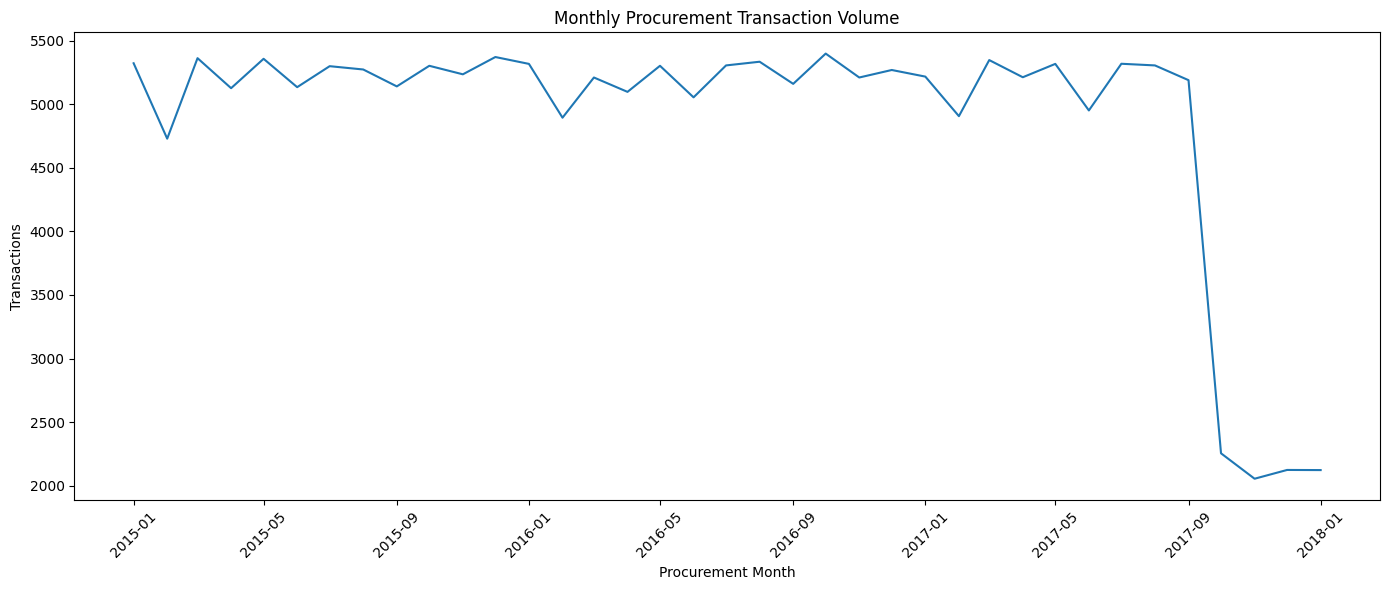

In [18]:
# ============================================================
# Monthly Procurement Activity Trend
# ============================================================

plot_data = monthly_activity.copy()

plot_data["year_month"] = pd.to_datetime(
    plot_data["year_month"]
)

plt.figure(figsize=(14, 6))

plt.plot(
    plot_data["year_month"],
    plot_data["Transactions"]
)

plt.title(
    "Monthly Procurement Transaction Volume"
)

plt.xlabel(
    "Procurement Month"
)

plt.ylabel(
    "Transactions"
)

plt.xticks(
    rotation=45
)

plt.tight_layout()

plt.show()

### Observations

- Monthly procurement activity remains relatively stable between approximately **4,700 and 5,400 transactions** from January 2015 through September 2017.
- The highest monthly activity is observed around **October 2016 (5,398 transactions)**, while February 2015 records the lowest activity during the stable period with **4,729 transactions**.
- The series shows recurring month-to-month fluctuations, but there is **no sustained upward or downward trend** during the main 2015–2017 operating period.
- A pronounced decline occurs from **October 2017 onward**, with monthly activity falling to approximately **2,055–2,255 transactions**.
- January 2018 records only **2,123 transactions**, consistent with the reduced activity observed at the end of 2017.
- The sharp decline should **not immediately be interpreted as a business contraction**. It may reflect incomplete-period coverage, changes in data availability, or an operational shift near the end of the dataset.

#### Analytical Implications

- Procurement activity appears broadly stable during the core observation period, with moderate seasonal/monthly fluctuations.
- The late-2017 decline represents a **structural change point** that should be investigated separately before being used for trend or forecasting conclusions.
- The January 2018 observation should be treated cautiously because it may represent a **partial observation period**.
- Subsequent analysis should compare procurement performance before and after the late-2017 activity reduction to determine whether the change affects shipping, profitability, product mix, and market sensitivity.

#### Possible Actions

- Validate whether the **October 2017 onward decline** is caused by incomplete source-data coverage or an actual change in procurement activity.
- Compare transaction volume with **order counts, quantities, sales, and supplier/product activity** to determine whether the decline is broad-based.
- Investigate whether the change coincides with shifts in **market, country, department, or product mix**.
- Exclude or separately flag potentially incomplete periods when performing **trend estimation or predictive modeling**.

## 3.3 Procurement Activity Reconciliation

The aggregated temporal transaction counts are reconciled against the Enterprise Feature Store total transaction count.

This ensures that the temporal aggregation does not exclude or duplicate transaction records.

The reconciliation must satisfy:

`Sum of Monthly Transactions = Total Feature Store Transactions`

In [19]:
# ============================================================
# Temporal Aggregation Reconciliation
# ============================================================

monthly_transaction_total = (
    monthly_activity["Transactions"]
    .sum()
)

feature_store_transaction_total = (
    len(feature_store)
)

print("=" * 70)
print("TEMPORAL AGGREGATION RECONCILIATION")
print("=" * 70)

print(
    "Monthly Aggregated Transactions :",
    f"{monthly_transaction_total:,}"
)

print(
    "Feature Store Transactions      :",
    f"{feature_store_transaction_total:,}"
)

print(
    "Difference                      :",
    f"{monthly_transaction_total - feature_store_transaction_total:,}"
)

print(
    "\nReconciliation                  :",
    "PASS"
    if monthly_transaction_total
    == feature_store_transaction_total
    else "FAIL"
)

TEMPORAL AGGREGATION RECONCILIATION
Monthly Aggregated Transactions : 180,519
Feature Store Transactions      : 180,519
Difference                      : 0

Reconciliation                  : PASS


### Observations

- The monthly temporal aggregation accounts for **all 180,519 transactions** in the Enterprise Feature Store.
- The aggregated monthly transaction count exactly matches the feature store transaction count.
- The reconciliation difference is **0**, confirming that no transactions were lost or duplicated during the monthly aggregation.
- The temporal grouping by `year_month` therefore provides a complete representation of transaction activity across the available observation period.

#### Validation Result

**PASS — Temporal aggregation is fully reconciled with the Enterprise Feature Store.**

This confirms that the monthly procurement activity analysis can be used reliably for subsequent trend, seasonality, and period-level analysis.

## 3.4 Shipping Performance & Delivery Risk Analysis

Shipping performance is analyzed to understand the operational reliability of procurement transactions.

The analysis uses the engineered shipping features:

- `shipping_delay_days`
- `is_delayed`
- `shipping_performance`

The objective is to determine:

- The overall prevalence of delayed transactions.
- The distribution of shipping delay duration.
- The proportion of On-Time, Delayed, and Early transactions.
- Whether delivery performance varies across the observation period.
- The relationship between scheduled and actual shipping duration.

These indicators provide the foundation for subsequent delivery-risk and operational performance analysis.

### 3.4.1 Overall Shipping Performance

In [20]:
# ============================================================
# Overall Shipping Performance
# ============================================================

shipping_performance_summary = (
    feature_store["shipping_performance"]
    .value_counts()
    .rename_axis("Shipping Performance")
    .reset_index(name="Transactions")
)

shipping_performance_summary["Transaction Share %"] = (
    shipping_performance_summary["Transactions"]
    / len(feature_store)
    * 100
).round(2)

print("=" * 70)
print("OVERALL SHIPPING PERFORMANCE")
print("=" * 70)

display(
    shipping_performance_summary
)

OVERALL SHIPPING PERFORMANCE


,Shipping Performance,Transactions,Transaction Share %
0,Delayed,103400,57.28
1,Early,43366,24.02
2,On Time,33753,18.70


### Analytical Observations

The shipping-performance analysis indicates a significant delivery-risk concentration within the procurement transaction population.

* **57.28% of transactions are classified as Delayed**, representing 103,400 transactions and making delayed delivery the dominant shipping-performance category.
* **24.02% of transactions are classified as Early**, indicating that a meaningful portion of shipments arrive ahead of the expected schedule.
* Only **18.70% of transactions are On Time**, suggesting that schedule adherence is relatively limited across the observed procurement population.
* The difference between delayed and on-time transactions indicates that **delivery reliability is a significant operational performance area** requiring further investigation.
* The substantial proportion of early shipments should also be examined because consistently early deliveries may indicate conservative scheduling, excess lead-time buffers, or differences in planned versus actual logistics performance.

These results establish shipping performance as an important dimension for subsequent analysis. Further investigation should examine **delay duration, scheduled versus actual shipping days, temporal patterns, product and category differences, geographic variation, and the relationship between delivery delays and transaction value or profitability**.


### 3.4.2 Delayed Transaction Profile

In [21]:
# ============================================================
# Delivery Delay Profile
# ============================================================

delay_summary = pd.DataFrame({

    "Metric": [
        "Total Transactions",
        "Delayed Transactions",
        "Non-Delayed Transactions",
        "Delay Rate",
        "Average Delay Days",
        "Median Delay Days",
        "Maximum Delay Days"
    ],

    "Value": [

        len(feature_store),

        feature_store["is_delayed"].sum(),

        (~feature_store["is_delayed"]).sum(),

        (
            feature_store["is_delayed"].mean()
            * 100
        ).round(2),

        feature_store["shipping_delay_days"].mean(),

        feature_store["shipping_delay_days"].median(),

        feature_store["shipping_delay_days"].max()
    ]
})

print("=" * 70)
print("DELIVERY DELAY PROFILE")
print("=" * 70)

display(
    delay_summary
)

DELIVERY DELAY PROFILE


,Metric,Value
0,Total Transactions,180519.000000
1,Delayed Transactions,103400.000000
2,Non-Delayed Transactions,77119.000000
3,Delay Rate,57.280000
4,Average Delay Days,0.565807
5,Median Delay Days,1.000000
6,Maximum Delay Days,4.000000


### Observations

* Out of **180,519 transactions**, **103,400 transactions were delayed**, resulting in an overall **delay rate of 57.28%**.
* **77,119 transactions (42.72%)** were non-delayed, meaning delayed transactions substantially outnumbered non-delayed transactions.
* The **average shipping delay is 0.57 days**, while the **median delay is 1 day**.
* The **maximum observed delay is 4 days**, indicating that delay duration is relatively limited even though delayed transactions are frequent.
* The concentration around small delay durations suggests that the primary operational concern is the **frequency of delivery delays rather than prolonged delays**.
* The combination of a high delay rate and relatively short delay duration indicates an opportunity to improve **schedule adherence and delivery reliability**.

#### Analytical Implications

The high prevalence of delayed transactions makes delivery performance an important procurement-performance dimension. Further analysis should examine whether delays are concentrated across specific **time periods, products, categories, markets, countries, shipping modes, or customer segments**, and whether delayed transactions are associated with changes in **transaction value, profitability, or external market conditions**.


### 3.4.3 Shipping Delay Distribution

In [22]:
# ============================================================
# Shipping Delay Distribution
# ============================================================

delay_distribution = (
    feature_store["shipping_delay_days"]
    .value_counts()
    .sort_index()
    .rename_axis("Shipping Delay Days")
    .reset_index(name="Transactions")
)

delay_distribution["Transaction Share %"] = (
    delay_distribution["Transactions"]
    / len(feature_store)
    * 100
).round(2)

print("=" * 70)
print("SHIPPING DELAY DISTRIBUTION")
print("=" * 70)

display(
    delay_distribution
)

SHIPPING DELAY DISTRIBUTION


,Shipping Delay Days,Transactions,Transaction Share %
0,-2,21666,12.00
1,-1,21700,12.02
2,0,33753,18.70
3,1,60647,33.60
4,2,28718,15.91
5,3,7052,3.91
6,4,6983,3.87


### Observations

* **33,753 transactions (18.70%)** have a shipping delay of **0 days**, representing on-time deliveries.
* The largest concentration occurs at **1 day of delay**, with **60,647 transactions (33.60%)**.
* **28,718 transactions (15.91%)** experienced **2 days of delay**, while **7,052 transactions (3.91%)** experienced **3 days of delay**.
* The remaining **6,983 transactions (3.87%)** experienced **4 days of delay**.
* Early deliveries are also present, with **21,700 transactions (12.02%)** arriving **1 day early** and **21,666 transactions (12.00%)** arriving **2 days early**.
* The distribution is concentrated around **small deviations from scheduled shipping duration**, with **1-day delays representing the dominant category**.
* Transactions with delays beyond 2 days account for a relatively small proportion of the dataset, indicating that **severe delivery delays are less common than short delays**.

#### Analytical Implication

The distribution indicates that delivery-risk improvement should primarily focus on **reducing frequent short delays**, particularly the dominant 1-day delay category. Further analysis should examine whether these delays are concentrated across specific **shipping modes, markets, products, geographic regions, or time periods**.


### 3.4.4 Scheduled vs Actual Shipping Duration

This is particularly important because it gives us a direct operational measure rather than looking only at the binary delayed flag.

In [23]:
# ============================================================
# Scheduled vs Actual Shipping Duration
# ============================================================

shipping_duration_summary = pd.DataFrame({

    "Metric": [
        "Scheduled Shipping Days",
        "Actual Shipping Days",
        "Shipping Duration Difference"
    ],

    "Mean": [
        feature_store["scheduled_shipping_days"].mean(),
        feature_store["actual_shipping_days"].mean(),
        (
            feature_store["actual_shipping_days"]
            - feature_store["scheduled_shipping_days"]
        ).mean()
    ],

    "Median": [
        feature_store["scheduled_shipping_days"].median(),
        feature_store["actual_shipping_days"].median(),
        (
            feature_store["actual_shipping_days"]
            - feature_store["scheduled_shipping_days"]
        ).median()
    ],

    "Minimum": [
        feature_store["scheduled_shipping_days"].min(),
        feature_store["actual_shipping_days"].min(),
        (
            feature_store["actual_shipping_days"]
            - feature_store["scheduled_shipping_days"]
        ).min()
    ],

    "Maximum": [
        feature_store["scheduled_shipping_days"].max(),
        feature_store["actual_shipping_days"].max(),
        (
            feature_store["actual_shipping_days"]
            - feature_store["scheduled_shipping_days"]
        ).max()
    ]
})

print("=" * 70)
print("SCHEDULED VS ACTUAL SHIPPING DURATION")
print("=" * 70)

display(
    shipping_duration_summary.round(2)
)

SCHEDULED VS ACTUAL SHIPPING DURATION


,Metric,Mean,Median,Minimum,Maximum
0,Scheduled Shipping Days,2.93,4.0,0,4
1,Actual Shipping Days,3.50,3.0,0,6
2,Shipping Duration Difference,0.57,1.0,-2,4


### 3.4.5 Shipping Performance by Year

In [24]:
# ============================================================
# Shipping Performance by Year
# ============================================================

shipping_by_year = (
    feature_store
    .groupby("year")
    .agg(
        Transactions=("is_delayed", "size"),
        Delayed_Transactions=("is_delayed", "sum"),
        Average_Delay_Days=("shipping_delay_days", "mean")
    )
    .reset_index()
)

shipping_by_year["Delay Rate %"] = (
    shipping_by_year["Delayed_Transactions"]
    / shipping_by_year["Transactions"]
    * 100
).round(2)

shipping_by_year["Average Delay Days"] = (
    shipping_by_year["Average_Delay_Days"]
    .round(2)
)

print("=" * 70)
print("SHIPPING PERFORMANCE BY YEAR")
print("=" * 70)

display(
    shipping_by_year
)

SHIPPING PERFORMANCE BY YEAR


,year,Transactions,Delayed_Transactions,Average_Delay_Days,Delay Rate %,Average Delay Days
0,2015,62650,35877,0.564421,57.27,0.56
1,2016,62550,35841,0.569065,57.30,0.57
2,2017,53196,30436,0.561734,57.21,0.56
3,2018,2123,1246,0.612812,58.69,0.61


### 3.4.6 Shipping Performance by Operational Day Type

Since we just engineered operational_day_type, this is our first cross-domain analysis.

In [25]:
# ============================================================
# Shipping Performance by Operational Day Type
# ============================================================

shipping_by_day_type = (
    feature_store
    .groupby("operational_day_type")
    .agg(
        Transactions=("is_delayed", "size"),
        Delayed_Transactions=("is_delayed", "sum"),
        Average_Delay_Days=("shipping_delay_days", "mean")
    )
    .reset_index()
)

shipping_by_day_type["Delay Rate %"] = (
    shipping_by_day_type["Delayed_Transactions"]
    / shipping_by_day_type["Transactions"]
    * 100
).round(2)

shipping_by_day_type["Average Delay Days"] = (
    shipping_by_day_type["Average_Delay_Days"]
    .round(2)
)

print("=" * 70)
print("SHIPPING PERFORMANCE BY OPERATIONAL DAY TYPE")
print("=" * 70)

display(
    shipping_by_day_type
)

SHIPPING PERFORMANCE BY OPERATIONAL DAY TYPE


,operational_day_type,Transactions,Delayed_Transactions,Average_Delay_Days,Delay Rate %,Average Delay Days
0,Holiday,4268,2516,0.600984,58.95,0.60
1,Holiday & Weekend,1092,637,0.638278,58.33,0.64
2,Weekend,50755,29035,0.566644,57.21,0.57
3,Working Day,124404,71212,0.563623,57.24,0.56


### 3.4.7 Shipping Performance Visualization

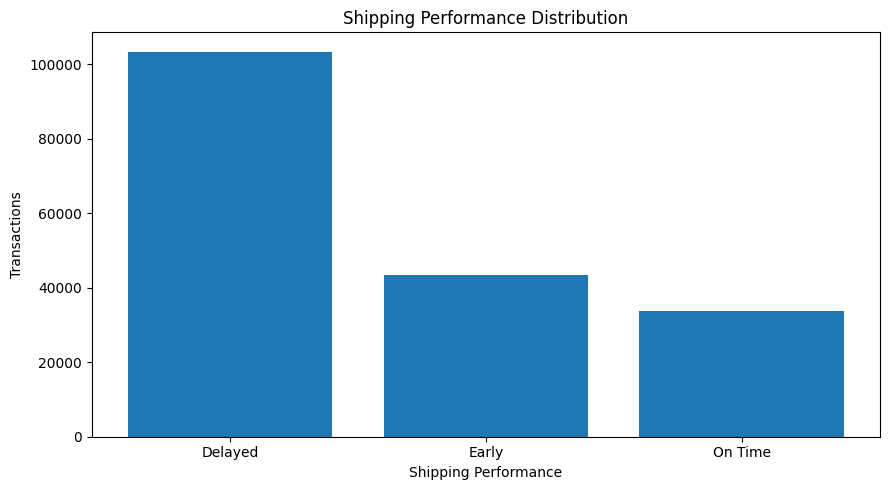

In [26]:
# ============================================================
# Shipping Performance Visualization
# ============================================================

plot_data = shipping_performance_summary.copy()

plt.figure(figsize=(9, 5))

plt.bar(
    plot_data["Shipping Performance"],
    plot_data["Transactions"]
)

plt.title(
    "Shipping Performance Distribution"
)

plt.xlabel(
    "Shipping Performance"
)

plt.ylabel(
    "Transactions"
)

plt.tight_layout()

plt.show()

### 3.4.8 Shipping Validation

In [27]:
# ============================================================
# Shipping Performance Validation
# ============================================================

shipping_total = (
    shipping_performance_summary["Transactions"]
    .sum()
)

delay_flag_total = (
    feature_store["is_delayed"].value_counts().sum()
)

print("=" * 70)
print("SHIPPING PERFORMANCE VALIDATION")
print("=" * 70)

print(
    "Shipping Category Transactions :",
    f"{shipping_total:,}"
)

print(
    "Feature Store Transactions     :",
    f"{len(feature_store):,}"
)

print(
    "Delay Flag Transactions        :",
    f"{delay_flag_total:,}"
)

print(
    "\nShipping Category Reconciliation :",
    "PASS"
    if shipping_total == len(feature_store)
    else "FAIL"
)

print(
    "Delay Flag Reconciliation        :",
    "PASS"
    if delay_flag_total == len(feature_store)
    else "FAIL"
)

SHIPPING PERFORMANCE VALIDATION
Shipping Category Transactions : 180,519
Feature Store Transactions     : 180,519
Delay Flag Transactions        : 180,519

Shipping Category Reconciliation : PASS
Delay Flag Reconciliation        : PASS


## 3.5 — Procurement Volume & Transaction Value Analysis

Now we move to the next section of 05B, following the same sequence.

This section will examine the scale and economic composition of procurement activity using:

- `quantity`
- `unit_price`
- `gross_sales`
- `line_total`
- `net_profit`
- `profit_margin`
- `order_size_category`
- `is_bulk_order`
- `transaction_value_category`
- `is_high_value_transaction`

The goal is to understand how much is being procured, how transactions are distributed by size/value, and where the financial concentration exists.

### 3.5.1 Procurement Volume Profile

In [28]:
# ============================================================
# Procurement Volume Profile
# ============================================================

procurement_volume_summary = pd.DataFrame({

    "Metric": [
        "Total Quantity",
        "Average Quantity per Transaction",
        "Median Quantity per Transaction",
        "Minimum Quantity",
        "Maximum Quantity"
    ],

    "Value": [
        feature_store["quantity"].sum(),
        feature_store["quantity"].mean(),
        feature_store["quantity"].median(),
        feature_store["quantity"].min(),
        feature_store["quantity"].max()
    ]
})

print("=" * 70)
print("PROCUREMENT VOLUME PROFILE")
print("=" * 70)

display(
    procurement_volume_summary.round(2)
)

PROCUREMENT VOLUME PROFILE


,Metric,Value
0,Total Quantity,384079.00
1,Average Quantity per Transaction,2.13
2,Median Quantity per Transaction,1.00
3,Minimum Quantity,1.00
4,Maximum Quantity,5.00


### 3.5.2 Order Size Distribution

In [29]:
# ============================================================
# Order Size Distribution
# ============================================================

order_size_summary = (
    feature_store["order_size_category"]
    .value_counts()
    .rename_axis("Order Size Category")
    .reset_index(name="Transactions")
)

order_size_summary["Transaction Share %"] = (
    order_size_summary["Transactions"]
    / len(feature_store)
    * 100
).round(2)

print("=" * 70)
print("ORDER SIZE DISTRIBUTION")
print("=" * 70)

display(
    order_size_summary
)

ORDER SIZE DISTRIBUTION


,Order Size Category,Transactions,Transaction Share %
0,Small,99134,54.92
1,Large,40720,22.56
2,Medium,40665,22.53


### 3.5.3 Bulk Order Analysis

In [30]:
# ============================================================
# Bulk Order Analysis
# ============================================================

bulk_order_summary = pd.DataFrame({

    "Metric": [
        "Bulk Orders",
        "Non-Bulk Orders",
        "Bulk Order Rate"
    ],

    "Value": [
        feature_store["is_bulk_order"].sum(),
        (~feature_store["is_bulk_order"]).sum(),
        feature_store["is_bulk_order"].mean() * 100
    ]
})

print("=" * 70)
print("BULK ORDER ANALYSIS")
print("=" * 70)

display(
    bulk_order_summary.round(2)
)

BULK ORDER ANALYSIS


,Metric,Value
0,Bulk Orders,40720.00
1,Non-Bulk Orders,139799.00
2,Bulk Order Rate,22.56


### 3.5.4 Transaction Value Distribution

In [31]:
# ============================================================
# Transaction Value Distribution
# ============================================================

transaction_value_summary = (
    feature_store["transaction_value_category"]
    .value_counts()
    .rename_axis("Transaction Value Category")
    .reset_index(name="Transactions")
)

transaction_value_summary["Transaction Share %"] = (
    transaction_value_summary["Transactions"]
    / len(feature_store)
    * 100
).round(2)

print("=" * 70)
print("TRANSACTION VALUE DISTRIBUTION")
print("=" * 70)

display(
    transaction_value_summary
)

TRANSACTION VALUE DISTRIBUTION


,Transaction Value Category,Transactions,Transaction Share %
0,Medium Value,90134,49.93
1,Low Value,45306,25.10
2,High Value,45079,24.97


### 3.5.5 High-Value Transaction Analysis

In [32]:
# ============================================================
# High-Value Transaction Analysis
# ============================================================

high_value_summary = pd.DataFrame({

    "Metric": [
        "High-Value Transactions",
        "Non-High-Value Transactions",
        "High-Value Transaction Rate"
    ],

    "Value": [
        feature_store["is_high_value_transaction"].sum(),
        (~feature_store["is_high_value_transaction"]).sum(),
        feature_store["is_high_value_transaction"].mean() * 100
    ]
})

print("=" * 70)
print("HIGH-VALUE TRANSACTION ANALYSIS")
print("=" * 70)

display(
    high_value_summary.round(2)
)

HIGH-VALUE TRANSACTION ANALYSIS


,Metric,Value
0,High-Value Transactions,45079.00
1,Non-High-Value Transactions,135440.00
2,High-Value Transaction Rate,24.97


### 3.5.6 Procurement Financial Scale Profile

In [33]:
# ============================================================
# Financial Scale Profile
# ============================================================

financial_scale_summary = pd.DataFrame({

    "Metric": [
        "Total Gross Sales",
        "Average Gross Sales",
        "Median Gross Sales",
        "Total Net Profit",
        "Average Net Profit",
        "Median Net Profit",
        "Average Profit Margin",
        "Median Profit Margin"
    ],

    "Value": [
        feature_store["gross_sales"].sum(),
        feature_store["gross_sales"].mean(),
        feature_store["gross_sales"].median(),
        feature_store["net_profit"].sum(),
        feature_store["net_profit"].mean(),
        feature_store["net_profit"].median(),
        feature_store["profit_margin"].mean(),
        feature_store["profit_margin"].median()
    ]
})

print("=" * 70)
print("FINANCIAL SCALE PROFILE")
print("=" * 70)

display(
    financial_scale_summary.round(2)
)

FINANCIAL SCALE PROFILE


,Metric,Value
0,Total Gross Sales,36784735.01
1,Average Gross Sales,203.77
2,Median Gross Sales,199.92
3,Total Net Profit,3966902.97
4,Average Net Profit,21.97
5,Median Net Profit,31.52
6,Average Profit Margin,10.83
7,Median Profit Margin,24.25


### 3.5.7 Procurement Volume by Year

In [34]:
# ============================================================
# Procurement Volume by Year
# ============================================================

procurement_by_year = (
    feature_store
    .groupby("year")
    .agg(
        Transactions=("order_id", "size"),
        Total_Quantity=("quantity", "sum"),
        Total_Gross_Sales=("gross_sales", "sum"),
        Total_Net_Profit=("net_profit", "sum")
    )
    .reset_index()
)

procurement_by_year["Transaction Share %"] = (
    procurement_by_year["Transactions"]
    / len(feature_store)
    * 100
).round(2)

print("=" * 70)
print("PROCUREMENT VOLUME BY YEAR")
print("=" * 70)

display(
    procurement_by_year.round(2)
)

PROCUREMENT VOLUME BY YEAR


,year,Transactions,Total_Quantity,Total_Gross_Sales,Total_Net_Profit,Transaction Share %
0,2015,62650,138480,12340831.43,1318856.90,34.71
1,2016,62550,137352,12303817.32,1310119.07,34.65
2,2017,53196,106124,11808436.14,1304085.11,29.47
3,2018,2123,2123,331650.12,33841.89,1.18


### 3.5.8 Transaction Value vs Procurement Volume

This gives us a useful business-level comparison between transaction size and economic value.

In [35]:
# ============================================================
# Transaction Value vs Procurement Volume
# ============================================================

value_volume_analysis = (
    feature_store
    .groupby("transaction_value_category")
    .agg(
        Transactions=("order_id", "size"),
        Total_Quantity=("quantity", "sum"),
        Average_Quantity=("quantity", "mean"),
        Total_Gross_Sales=("gross_sales", "sum"),
        Total_Net_Profit=("net_profit", "sum"),
        Average_Profit_Margin=("profit_margin", "mean")
    )
    .reset_index()
)

value_volume_analysis["Transaction Share %"] = (
    value_volume_analysis["Transactions"]
    / len(feature_store)
    * 100
).round(2)

print("=" * 70)
print("TRANSACTION VALUE VS PROCUREMENT VOLUME")
print("=" * 70)

display(
    value_volume_analysis.round(2)
)

TRANSACTION VALUE VS PROCUREMENT VOLUME


,transaction_value_category,Transactions,Total_Quantity,Average_Quantity,Total_Gross_Sales,Total_Net_Profit,Average_Profit_Margin,Transaction Share %
0,High Value,45079,88142,1.96,16896074.04,1820632.89,10.82,24.97
1,Low Value,45306,72542,1.60,3368977.08,360152.06,10.79,25.10
2,Medium Value,90134,223395,2.48,16519683.89,1786118.03,10.86,49.93


### 3.5.9 Procurement Validation

In [36]:
# ============================================================
# Procurement Volume & Value Validation
# ============================================================

order_size_total = (
    order_size_summary["Transactions"].sum()
)

transaction_value_total = (
    transaction_value_summary["Transactions"].sum()
)

bulk_total = (
    feature_store["is_bulk_order"].value_counts().sum()
)

high_value_total = (
    feature_store["is_high_value_transaction"]
    .value_counts()
    .sum()
)

print("=" * 70)
print("PROCUREMENT VOLUME & VALUE VALIDATION")
print("=" * 70)

print(
    "Order Size Transactions        :",
    f"{order_size_total:,}"
)

print(
    "Transaction Value Transactions :",
    f"{transaction_value_total:,}"
)

print(
    "Bulk Order Transactions        :",
    f"{bulk_total:,}"
)

print(
    "High-Value Transactions        :",
    f"{high_value_total:,}"
)

print(
    "\nOrder Size Reconciliation       :",
    "PASS"
    if order_size_total == len(feature_store)
    else "FAIL"
)

print(
    "Transaction Value Reconciliation:",
    "PASS"
    if transaction_value_total == len(feature_store)
    else "FAIL"
)

print(
    "Bulk Order Reconciliation       :",
    "PASS"
    if bulk_total == len(feature_store)
    else "FAIL"
)

print(
    "High-Value Reconciliation       :",
    "PASS"
    if high_value_total == len(feature_store)
    else "FAIL"
)

PROCUREMENT VOLUME & VALUE VALIDATION
Order Size Transactions        : 180,519
Transaction Value Transactions : 180,519
Bulk Order Transactions        : 180,519
High-Value Transactions        : 180,519

Order Size Reconciliation       : PASS
Transaction Value Reconciliation: PASS
Bulk Order Reconciliation       : PASS
High-Value Reconciliation       : PASS


## 3.6 — Financial & Profitability Analysis

Now we should move into the financial intelligence section rather than repeating the basic financial profile.

We'll investigate:

- Gross Sales Distribution
- Net Profit Distribution
- Profit Margin Distribution
- Profitability Categories
- Negative-Profit Transactions
- Profitability by Year
- Profitability by Transaction Value
- Revenue vs Profit concentration
- Financial validation

### 3.6.1 Financial Performance Profile

In [37]:
# ============================================================
# Financial Performance Profile
# ============================================================

financial_metrics = pd.DataFrame({

    "Metric": [
        "Total Gross Sales",
        "Total Net Profit",
        "Average Gross Sales",
        "Median Gross Sales",
        "Average Net Profit",
        "Median Net Profit",
        "Average Profit Margin",
        "Median Profit Margin",
        "Minimum Net Profit",
        "Maximum Net Profit",
        "Minimum Profit Margin",
        "Maximum Profit Margin"
    ],

    "Value": [
        feature_store["gross_sales"].sum(),
        feature_store["net_profit"].sum(),
        feature_store["gross_sales"].mean(),
        feature_store["gross_sales"].median(),
        feature_store["net_profit"].mean(),
        feature_store["net_profit"].median(),
        feature_store["profit_margin"].mean(),
        feature_store["profit_margin"].median(),
        feature_store["net_profit"].min(),
        feature_store["net_profit"].max(),
        feature_store["profit_margin"].min(),
        feature_store["profit_margin"].max()
    ]
})

print("=" * 70)
print("FINANCIAL PERFORMANCE PROFILE")
print("=" * 70)

display(
    financial_metrics.round(2)
)

FINANCIAL PERFORMANCE PROFILE


,Metric,Value
0,Total Gross Sales,36784735.01
1,Total Net Profit,3966902.97
2,Average Gross Sales,203.77
3,Median Gross Sales,199.92
4,Average Net Profit,21.97
5,Median Net Profit,31.52
6,Average Profit Margin,10.83
7,Median Profit Margin,24.25
8,Minimum Net Profit,-4274.98
9,Maximum Net Profit,911.80


### 3.6.2 Profitability Category Distribution

In [38]:
# ============================================================
# Profitability Category Distribution
# ============================================================

profitability_summary = (
    feature_store["profitability_category"]
    .value_counts()
    .rename_axis("Profitability Category")
    .reset_index(name="Transactions")
)

profitability_summary["Transaction Share %"] = (
    profitability_summary["Transactions"]
    / len(feature_store)
    * 100
).round(2)

print("=" * 70)
print("PROFITABILITY CATEGORY DISTRIBUTION")
print("=" * 70)

display(
    profitability_summary
)

PROFITABILITY CATEGORY DISTRIBUTION


,Profitability Category,Transactions,Transaction Share %
0,Medium Profitability,90257,50.0
1,Low Profitability,45134,25.0
2,High Profitability,45128,25.0


### 3.6.3 Negative Profitability Analysis

In [39]:
# ============================================================
# Negative Profitability Analysis
# ============================================================

negative_profit_transactions = (
    feature_store["net_profit"] < 0
)

negative_profit_count = (
    negative_profit_transactions.sum()
)

negative_profit_share = (
    negative_profit_count
    / len(feature_store)
    * 100
)

negative_profit_total = (
    feature_store.loc[
        negative_profit_transactions,
        "net_profit"
    ].sum()
)

print("=" * 70)
print("NEGATIVE PROFITABILITY ANALYSIS")
print("=" * 70)

print(
    "Negative-Profit Transactions :",
    f"{negative_profit_count:,}"
)

print(
    "Negative-Profit Share        :",
    f"{negative_profit_share:.2f}%"
)

print(
    "Total Negative Profit        :",
    f"{negative_profit_total:,.2f}"
)

NEGATIVE PROFITABILITY ANALYSIS
Negative-Profit Transactions : 33,784
Negative-Profit Share        : 18.71%
Total Negative Profit        : -3,883,547.35


### 3.6.4 — Profitability by Year

In [40]:
# ============================================================
# Profitability by Year
# ============================================================

profitability_by_year = (
    feature_store
    .groupby("year")
    .agg(
        Transactions=("order_id", "size"),
        Gross_Sales=("gross_sales", "sum"),
        Net_Profit=("net_profit", "sum"),
        Average_Net_Profit=("net_profit", "mean"),
        Median_Net_Profit=("net_profit", "median"),
        Average_Profit_Margin=("profit_margin", "mean"),
        Negative_Profit_Transactions=(
            "net_profit",
            lambda x: (x < 0).sum()
        )
    )
    .reset_index()
)

profitability_by_year["Negative Profit Rate %"] = (
    profitability_by_year["Negative_Profit_Transactions"]
    / profitability_by_year["Transactions"]
    * 100
).round(2)

print("=" * 70)
print("PROFITABILITY BY YEAR")
print("=" * 70)

display(
    profitability_by_year.round(2)
)

PROFITABILITY BY YEAR


,year,Transactions,Gross_Sales,Net_Profit,Average_Net_Profit,Median_Net_Profit,Average_Profit_Margin,Negative_Profit_Transactions,Negative Profit Rate %
0,2015,62650,12340831.43,1318856.90,21.05,31.03,10.78,11706,18.68
1,2016,62550,12303817.32,1310119.07,20.95,30.91,10.70,11808,18.88
2,2017,53196,11808436.14,1304085.11,24.51,33.59,11.08,9861,18.54
3,2018,2123,331650.12,33841.89,15.94,12.92,10.01,409,19.27


In [41]:
# ============================================================
# Profitability by Transaction Value
# ============================================================

profitability_by_value = (
    feature_store
    .groupby("transaction_value_category")
    .agg(
        Transactions=("order_id", "size"),
        Gross_Sales=("gross_sales", "sum"),
        Net_Profit=("net_profit", "sum"),
        Average_Net_Profit=("net_profit", "mean"),
        Median_Net_Profit=("net_profit", "median"),
        Average_Profit_Margin=("profit_margin", "mean"),
        Negative_Profit_Transactions=(
            "net_profit",
            lambda x: (x < 0).sum()
        )
    )
    .reset_index()
)

profitability_by_value["Negative Profit Rate %"] = (
    profitability_by_value["Negative_Profit_Transactions"]
    / profitability_by_value["Transactions"]
    * 100
).round(2)

print("=" * 70)
print("PROFITABILITY BY TRANSACTION VALUE")
print("=" * 70)

display(
    profitability_by_value.round(2)
)

PROFITABILITY BY TRANSACTION VALUE


,transaction_value_category,Transactions,Gross_Sales,Net_Profit,Average_Net_Profit,Median_Net_Profit,Average_Profit_Margin,Negative_Profit_Transactions,Negative Profit Rate %
0,High Value,45079,16896074.04,1820632.89,40.39,84.38,10.82,8422,18.68
1,Low Value,45306,3368977.08,360152.06,7.95,13.20,10.79,8439,18.63
2,Medium Value,90134,16519683.89,1786118.03,19.82,39.19,10.86,16923,18.78


In [42]:
# ============================================================
# Negative Profit Concentration by Product Department
# ============================================================

negative_profit_by_department = (
    feature_store[
        feature_store["net_profit"] < 0
    ]
    .groupby("department_name")
    .agg(
        Negative_Transactions=("order_id", "size"),
        Total_Negative_Profit=("net_profit", "sum"),
        Average_Negative_Profit=("net_profit", "mean")
    )
    .sort_values(
        "Total_Negative_Profit"
    )
    .reset_index()
)

print("=" * 70)
print("NEGATIVE PROFIT CONCENTRATION BY DEPARTMENT")
print("=" * 70)

display(
    negative_profit_by_department.round(2)
)

NEGATIVE PROFIT CONCENTRATION BY DEPARTMENT


,department_name,Negative_Transactions,Total_Negative_Profit,Average_Negative_Profit
0,Fan Shop,12507,-1810937.84,-144.79
1,Apparel,9171,-826507.38,-90.12
2,Golf,6309,-483151.75,-76.58
3,Footwear,2701,-441074.80,-163.30
4,Outdoors,1732,-127028.30,-73.34
5,Technology,260,-111982.17,-430.70
6,Fitness,438,-40764.66,-93.07
7,Discs Shop,399,-23458.69,-58.79
8,Health and Beauty,85,-11938.62,-140.45
9,Pet Shop,104,-4981.99,-47.90


### 3.6.5 — Profitability by Market

Now let's determine whether the profitability problem is geographically/market concentrated.

In [43]:
# ============================================================
# Profitability by Market
# ============================================================

profitability_by_market = (
    feature_store
    .groupby("market")
    .agg(
        Transactions=("order_id", "size"),
        Gross_Sales=("gross_sales", "sum"),
        Net_Profit=("net_profit", "sum"),
        Average_Net_Profit=("net_profit", "mean"),
        Median_Net_Profit=("net_profit", "median"),
        Average_Profit_Margin=("profit_margin", "mean"),
        Negative_Profit_Transactions=(
            "net_profit",
            lambda x: (x < 0).sum()
        )
    )
    .reset_index()
)

profitability_by_market["Negative Profit Rate %"] = (
    profitability_by_market["Negative_Profit_Transactions"]
    / profitability_by_market["Transactions"]
    * 100
).round(2)

print("=" * 70)
print("PROFITABILITY BY MARKET")
print("=" * 70)

display(
    profitability_by_market.round(2)
)

PROFITABILITY BY MARKET


,market,Transactions,Gross_Sales,Net_Profit,Average_Net_Profit,Median_Net_Profit,Average_Profit_Margin,Negative_Profit_Transactions,Negative Profit Rate %
0,Africa,11614,2294452.93,252071.18,21.70,31.49,11.23,2158,18.58
1,Europe,50252,10872396.80,1169442.96,23.27,32.78,11.01,9420,18.75
2,LATAM,51594,10277612.84,1123321.61,21.77,32.02,10.85,9588,18.58
3,Pacific Asia,41260,8273743.74,857753.44,20.79,29.18,10.42,7806,18.92
4,USCA,25799,5066528.71,564313.78,21.87,31.49,10.93,4812,18.65


In [44]:
# ============================================================
# Profitability by Department
# ============================================================

profitability_by_department = (
    feature_store
    .groupby("department_name")
    .agg(
        Transactions=("order_id", "size"),
        Gross_Sales=("gross_sales", "sum"),
        Net_Profit=("net_profit", "sum"),
        Average_Net_Profit=("net_profit", "mean"),
        Average_Profit_Margin=("profit_margin", "mean"),
        Negative_Profit_Transactions=(
            "net_profit",
            lambda x: (x < 0).sum()
        )
    )
    .reset_index()
)

profitability_by_department["Negative Profit Rate %"] = (
    profitability_by_department["Negative_Profit_Transactions"]
    / profitability_by_department["Transactions"]
    * 100
).round(2)

profitability_by_department = (
    profitability_by_department
    .sort_values(
        "Net_Profit",
        ascending=True
    )
)

print("=" * 70)
print("PROFITABILITY BY DEPARTMENT")
print("=" * 70)

display(
    profitability_by_department.round(2)
)

PROFITABILITY BY DEPARTMENT


,department_name,Transactions,Gross_Sales,Net_Profit,Average_Net_Profit,Average_Profit_Margin,Negative_Profit_Transactions,Negative Profit Rate %
1,Book Shop,405,12587.40,883.01,2.18,7.02,78,19.26
9,Pet Shop,492,41524.80,3589.26,7.30,8.64,104,21.14
7,Health and Beauty,362,106080.48,9493.63,26.23,8.95,85,23.48
2,Discs Shop,2026,228887.73,24193.12,11.94,9.78,399,19.69
4,Fitness,2479,397050.89,46538.06,18.77,11.76,438,17.67
10,Technology,1465,1039598.97,113170.01,77.25,11.31,260,17.75
8,Outdoors,9686,1253351.45,145251.46,15.00,11.30,1732,17.88
5,Footwear,14525,4006498.77,410222.50,28.24,10.66,2701,18.60
6,Golf,33220,4609028.24,497523.56,14.98,10.69,6309,18.99
0,Apparel,48998,7976255.34,881882.93,18.00,11.02,9171,18.72


In [45]:
# ============================================================
# Top Products by Negative Profit
# ============================================================

negative_profit_by_product = (
    feature_store[
        feature_store["net_profit"] < 0
    ]
    .groupby("product_name")
    .agg(
        Negative_Transactions=("order_id", "size"),
        Total_Negative_Profit=("net_profit", "sum"),
        Average_Negative_Profit=("net_profit", "mean")
    )
    .sort_values(
        "Total_Negative_Profit"
    )
    .reset_index()
)

print("=" * 70)
print("TOP PRODUCTS BY NEGATIVE PROFIT")
print("=" * 70)

display(
    negative_profit_by_product.head(15).round(2)
)

TOP PRODUCTS BY NEGATIVE PROFIT


,product_name,Negative_Transactions,Total_Negative_Profit,Average_Negative_Profit
0,Field & Stream Sportsman 16 Gun Fire Safe,3209,-728570.95,-227.04
1,Perfect Fitness Perfect Rip Deck,4583,-450978.29,-98.40
2,Diamondback Women's Serene Classic Comfort Bi,2590,-443082.23,-171.07
3,Nike Men's Free 5.0+ Running Shoe,2271,-400015.04,-176.14
4,Pelican Sunstream 100 Kayak,2916,-332804.25,-114.13
5,Nike Men's Dri-FIT Victory Golf Polo,3923,-323772.87,-82.53
6,Nike Men's CJ Elite 2 TD Football Cleat,4169,-309269.70,-74.18
7,O'Brien Men's Neoprene Life Vest,3617,-298637.48,-82.56
8,Under Armour Girls' Toddler Spine Surge Runni,2085,-139661.49,-66.98
9,Dell Laptop,73,-74967.13,-1026.95


In [46]:
# ============================================================
# Negative Profit Concentration
# ============================================================

total_negative_profit = (
    feature_store.loc[
        feature_store["net_profit"] < 0,
        "net_profit"
    ].sum()
)

top_5_department_negative_profit = (
    negative_profit_by_department
    .head(5)["Total_Negative_Profit"]
    .sum()
)

negative_profit_concentration = (
    top_5_department_negative_profit
    / total_negative_profit
    * 100
)

print("=" * 70)
print("NEGATIVE PROFIT CONCENTRATION")
print("=" * 70)

print(
    "Total Negative Profit :",
    f"{total_negative_profit:,.2f}"
)

print(
    "Top 5 Department Negative Profit :",
    f"{top_5_department_negative_profit:,.2f}"
)

print(
    "Top 5 Department Concentration :",
    f"{negative_profit_concentration:.2f}%"
)

NEGATIVE PROFIT CONCENTRATION
Total Negative Profit : -3,883,547.35
Top 5 Department Negative Profit : -3,688,700.07
Top 5 Department Concentration : 94.98%


### 3.6.6 — Financial Loss Concentration
This additional analysis. It will give us the share of total negative profit contributed by the largest loss-making products, which is more useful than looking at individual products alone.

In [47]:
# ============================================================
# Top Product Negative-Profit Concentration
# ============================================================

negative_profit_by_product = (
    feature_store[
        feature_store["net_profit"] < 0
    ]
    .groupby("product_name")
    .agg(
        Negative_Transactions=("order_id", "size"),
        Total_Negative_Profit=("net_profit", "sum"),
        Average_Negative_Profit=("net_profit", "mean")
    )
    .sort_values(
        "Total_Negative_Profit"
    )
    .reset_index()
)

total_negative_profit = (
    feature_store.loc[
        feature_store["net_profit"] < 0,
        "net_profit"
    ].sum()
)

top_10_product_negative_profit = (
    negative_profit_by_product
    .head(10)["Total_Negative_Profit"]
    .sum()
)

top_10_product_concentration = (
    top_10_product_negative_profit
    / total_negative_profit
    * 100
)

print("=" * 70)
print("TOP PRODUCT NEGATIVE-PROFIT CONCENTRATION")
print("=" * 70)

print(
    "Total Negative Profit :",
    f"{total_negative_profit:,.2f}"
)

print(
    "Top 10 Product Negative Profit :",
    f"{top_10_product_negative_profit:,.2f}"
)

print(
    "Top 10 Product Concentration :",
    f"{top_10_product_concentration:.2f}%"
)

TOP PRODUCT NEGATIVE-PROFIT CONCENTRATION
Total Negative Profit : -3,883,547.35
Top 10 Product Negative Profit : -3,501,759.43
Top 10 Product Concentration : 90.17%


In [48]:
# ============================================================
# Financial Analysis Validation
# ============================================================

financial_feature_check = all(
    col in feature_store.columns
    for col in [
        "gross_sales",
        "net_profit",
        "profit_margin",
        "profitability_category"
    ]
)

negative_profit_check = (
    negative_profit_count
    ==
    (feature_store["net_profit"] < 0).sum()
)

profitability_category_check = (
    profitability_summary["Transactions"].sum()
    ==
    len(feature_store)
)

print("=" * 70)
print("FINANCIAL ANALYSIS VALIDATION")
print("=" * 70)

print(
    "Financial Features Available :",
    "PASS" if financial_feature_check else "FAIL"
)

print(
    "Negative Profit Reconciliation:",
    "PASS" if negative_profit_check else "FAIL"
)

print(
    "Profitability Category Reconciliation:",
    "PASS"
    if profitability_category_check
    else "FAIL"
)

FINANCIAL ANALYSIS VALIDATION
Financial Features Available : PASS
Negative Profit Reconciliation: PASS
Profitability Category Reconciliation: PASS


## What we learned from Part 3 — Financial Intelligence Analysis

### Financial Performance Overview

The financial analysis evaluates gross sales, net profit, profitability margins, profitability categories, and negative-profit exposure across the transaction portfolio.

The enterprise feature store contains **180,519 procurement transactions** with total gross sales of **36,784,735.01** and total net profit of **3,966,902.97**.

Average gross sales per transaction are **203.77**, while median gross sales are **199.92**.

Average net profit is **21.97**, compared with a median of **31.52**. The difference between the mean and median reflects the presence of significant negative-profit observations.

Profitability ranges from **−4,274.98** to **911.80**, while profit margin ranges from **−275.00%** to **50.04%**.

### Profitability Category Distribution

The profitability categories are distributed as follows:

- Medium Profitability: **90,257 transactions (50.00%)**
- Low Profitability: **45,134 transactions (25.00%)**
- High Profitability: **45,128 transactions (25.00%)**

The profitability segmentation therefore provides an approximately 50/25/25 distribution across the transaction portfolio.

### Negative Profitability

A total of **33,784 transactions** generate negative profit, representing **18.71%** of all transactions.

The total negative profit associated with these transactions is **−3,883,547.35**.

This indicates that although loss-making transactions represent less than one-fifth of the transaction base, their financial impact is substantial.

### Profitability by Year

Profitability remains relatively stable across the main observation period.

- 2015 average net profit: **21.05**
- 2016 average net profit: **20.95**
- 2017 average net profit: **24.51**
- 2018 average net profit: **15.94**

The negative-profit rate remains close to 19% across all years:

- 2015: **18.68%**
- 2016: **18.88%**
- 2017: **18.54%**
- 2018: **19.27%**

The 2018 observation should be interpreted cautiously because the dataset contains substantially fewer transactions during this period.

### Profitability by Transaction Value

High-value transactions generate the largest total gross sales and net profit:

- High Value: **45,079 transactions**
- Gross Sales: **16,896,074.04**
- Net Profit: **1,820,632.89**
- Average Net Profit: **40.39**

Medium-value transactions contribute the largest transaction volume:

- **90,134 transactions**
- Gross Sales: **16,519,683.89**
- Net Profit: **1,786,118.03**

Negative-profit rates are highly similar across transaction-value categories, remaining between approximately **18.63% and 18.78%**.

Therefore, negative profitability is not isolated to a particular transaction-value segment.

### Profitability by Market

Profitability is relatively consistent across the five markets.

Europe records the highest average net profit at **23.27**, while Pacific Asia records the lowest at **20.79**.

Africa records the highest average profit margin at **11.23%**, while Pacific Asia records the lowest at **10.42%**.

Negative-profit rates remain tightly grouped between **18.58% and 18.92%** across markets.

This suggests that negative profitability is not primarily a market-wide phenomenon.

### Profitability by Department

Department-level analysis reveals substantially greater variation.

Technology records the highest average net profit at **77.25 per transaction**, with an average profit margin of **11.31%**.

Book Shop records the lowest average net profit at **2.18**, with an average profit margin of **7.02%**.

Health and Beauty records the highest negative-profit rate at **23.48%**, followed by Pet Shop at **21.14%**.

Fan Shop represents the largest absolute loss exposure because of its high transaction volume, with **12,507 negative-profit transactions** and approximately **−1.81 million** in cumulative negative profit.

### Negative Profit Concentration by Department

Negative profitability is highly concentrated across departments.

The top five departments account for:

**94.98% of total negative profit.**

This indicates that the majority of financial loss exposure is concentrated within a relatively small number of departments rather than being evenly distributed across the organization.

This concentration provides a strong basis for targeted profitability investigation.

### Negative Profit Concentration by Product

Product-level analysis further confirms the concentration of financial losses.

The top 10 loss-making products account for:

**90.17% of total negative profit.**

The largest contributor is:

**Field & Stream Sportsman 16 Gun Fire Safe**

- Negative-profit transactions: **3,209**
- Total negative profit: **−728,570.95**
- Average negative profit: **−227.04**

Other major contributors include:

- Perfect Fitness Perfect Rip Deck: **−450,978.29**
- Diamondback Women's Serene Classic Comfort: **−443,082.23**
- Nike Men's Free 5.0+ Running Shoe: **−400,015.04**
- Pelican Sunstream 100 Kayak: **−332,804.25**

The analysis also identifies products with relatively low loss frequency but high loss severity.

For example, Dell Laptop records only **73 negative-profit transactions**, but the average negative profit is **−1,026.95** per transaction.

This distinction between loss frequency and loss severity is important for subsequent root-cause analysis.

### Financial Analytical Implications

The financial analysis indicates that profitability losses are highly concentrated.

The combination of:

- **18.71% negative-profit transactions**
- **94.98% departmental loss concentration**
- **90.17% top-product loss concentration**

suggests that targeted intervention may be more effective than portfolio-wide profitability adjustments.

Future analysis should investigate the relationship between loss-making transactions and:

- Product pricing
- Unit cost
- Discount structure
- Quantity
- Shipping performance
- Department
- Market
- Product mix
- External market conditions

The financial intelligence layer therefore provides the foundation for identifying and prioritizing the major sources of procurement profitability risk.

### Financial Analysis Validation

The financial analysis passed all implemented validation checks:

- Financial Features Available: **PASS**
- Negative Profit Reconciliation: **PASS**
- Profitability Category Reconciliation: **PASS**

# Part 4 — Commodity Market Analysis

Commodity market movements can influence procurement costs, supplier pricing, inventory decisions, and overall financial performance.

The feature store contains five monthly commodity-market movement indicators:

- `energy_price_change_pct`
- `metals_price_change_pct`
- `agriculture_price_change_pct`
- `food_price_change_pct`
- `industrial_materials_price_change_pct`

These features represent percentage movements in the corresponding commodity-market indices and were engineered during Notebook 05A.

The objective of this section is to understand:

- The distribution and variability of commodity-market movements.
- The frequency of positive, negative, and zero market movements.
- Differences in market behavior across commodity categories.
- The relationship between commodity movements and procurement activity.
- The relationship between commodity movements and financial performance.
- Whether commodity-market conditions provide useful signals for downstream analytical and predictive modeling.

The expected missing values in these features are retained as `NaN`. These observations correspond to the initial period where a monthly percentage change cannot be mathematically calculated and were previously classified as expected analytical missingness.

No additional feature engineering is performed in this section.

## 4.1 Commodity Market Movement Profile

In [49]:
# ============================================================
# 4.1 Commodity Market Movement Profile
# ============================================================

commodity_features = [
    "energy_price_change_pct",
    "metals_price_change_pct",
    "agriculture_price_change_pct",
    "food_price_change_pct",
    "industrial_materials_price_change_pct"
]

print("=" * 70)
print("COMMODITY MARKET MOVEMENT PROFILE")
print("=" * 70)


# ------------------------------------------------------------
# Step 1: Ensure Commodity Movement Features Are Numeric
# ------------------------------------------------------------

for col in commodity_features:
    feature_store[col] = pd.to_numeric(
        feature_store[col],
        errors="coerce"
    )


# ------------------------------------------------------------
# Step 2: Validate Data Types
# ------------------------------------------------------------

print("\nData Types")
print("-" * 70)

display(
    feature_store[commodity_features]
    .dtypes
    .rename("Data Type")
    .to_frame()
)


# ------------------------------------------------------------
# Step 3: Build Commodity Market Profile
# ------------------------------------------------------------

commodity_profile = pd.DataFrame({

    "Feature": commodity_features,

    "Valid Observations": [
        feature_store[col].notna().sum()
        for col in commodity_features
    ],

    "Missing Values": [
        feature_store[col].isna().sum()
        for col in commodity_features
    ],

    "Missing Percentage": [
        feature_store[col].isna().mean() * 100
        for col in commodity_features
    ],

    "Mean": [
        feature_store[col].mean()
        for col in commodity_features
    ],

    "Median": [
        feature_store[col].median()
        for col in commodity_features
    ],

    "Standard Deviation": [
        feature_store[col].std()
        for col in commodity_features
    ],

    "Minimum": [
        feature_store[col].min()
        for col in commodity_features
    ],

    "Maximum": [
        feature_store[col].max()
        for col in commodity_features
    ]
})


# ------------------------------------------------------------
# Step 4: Display Profile
# ------------------------------------------------------------

print("\nCommodity Market Movement Profile")
print("-" * 70)

display(
    commodity_profile.round(3)
)

COMMODITY MARKET MOVEMENT PROFILE

Data Types
----------------------------------------------------------------------


,Data Type
energy_price_change_pct,float64
metals_price_change_pct,float64
agriculture_price_change_pct,float64
food_price_change_pct,float64
industrial_materials_price_change_pct,float64



Commodity Market Movement Profile
----------------------------------------------------------------------


,Feature,Valid Observations,Missing Values,Missing Percentage,Mean,Median,Standard Deviation,Minimum,Maximum
0,energy_price_change_pct,175197,5322,2.948,0.604,0.921,5.364,-9.667,12.454
1,metals_price_change_pct,175197,5322,2.948,0.377,-0.070,3.855,-7.837,8.292
2,agriculture_price_change_pct,175197,5322,2.948,-0.055,0.161,2.570,-7.673,4.583
3,food_price_change_pct,175197,5322,2.948,0.152,0.094,1.748,-3.674,4.123
4,industrial_materials_price_change_pct,175197,5322,2.948,-0.315,-0.082,1.581,-3.242,4.180


## 4.2 Commodity Market Movement Direction

Commodity percentage-change indicators can be interpreted according to their direction:

- **Positive movement** indicates an increase in the corresponding commodity-market index.
- **Negative movement** indicates a decrease.
- **Zero movement** indicates no change from the previous observation.

The directional distribution provides an initial view of whether commodity markets were predominantly rising, declining, or stable during the observation period.

This analysis is descriptive and does not imply that a commodity movement caused a change in procurement or financial performance.

In [50]:
# ============================================================
# 4.2 Commodity Market Movement Direction
# ============================================================

commodity_direction = []

for col in commodity_features:

    series = feature_store[col]

    commodity_direction.append({

        "Commodity": col,

        "Positive Movements": (
            (series > 0).sum()
        ),

        "Negative Movements": (
            (series < 0).sum()
        ),

        "Zero Movements": (
            (series == 0).sum()
        ),

        "Missing Values": (
            series.isnull().sum()
        )
    })

commodity_direction = pd.DataFrame(
    commodity_direction
)

print("=" * 70)
print("COMMODITY MARKET MOVEMENT DIRECTION")
print("=" * 70)

display(
    commodity_direction
)

COMMODITY MARKET MOVEMENT DIRECTION


,Commodity,Positive Movements,Negative Movements,Zero Movements,Missing Values
0,energy_price_change_pct,92013,83184,0,5322
1,metals_price_change_pct,87271,87926,0,5322
2,agriculture_price_change_pct,89307,85890,0,5322
3,food_price_change_pct,108799,66398,0,5322
4,industrial_materials_price_change_pct,78432,96765,0,5322


## 4.3 Commodity Market Movement Comparison

The five commodity markets are compared using their central tendency and movement variability.

The comparison focuses on:

- Average market movement.
- Median market movement.
- Market volatility represented by standard deviation.
- Largest positive movement.
- Largest negative movement.

This comparison helps identify which commodity markets experienced relatively larger movements during the observation period.

Because the features represent percentage changes rather than absolute commodity prices, the analysis focuses on relative market movement rather than price levels.

In [51]:
# ============================================================
# 4.3 Commodity Market Movement Comparison
# ============================================================

commodity_comparison = pd.DataFrame({

    "Commodity": commodity_features,

    "Average Movement %": [
        feature_store[col].mean()
        for col in commodity_features
    ],

    "Median Movement %": [
        feature_store[col].median()
        for col in commodity_features
    ],

    "Volatility (Std %)": [
        feature_store[col].std()
        for col in commodity_features
    ],

    "Minimum Movement %": [
        feature_store[col].min()
        for col in commodity_features
    ],

    "Maximum Movement %": [
        feature_store[col].max()
        for col in commodity_features
    ]
})

print("=" * 70)
print("COMMODITY MARKET MOVEMENT COMPARISON")
print("=" * 70)

display(
    commodity_comparison.round(3)
)

COMMODITY MARKET MOVEMENT COMPARISON


,Commodity,Average Movement %,Median Movement %,Volatility (Std %),Minimum Movement %,Maximum Movement %
0,energy_price_change_pct,0.604,0.921,5.364,-9.667,12.454
1,metals_price_change_pct,0.377,-0.070,3.855,-7.837,8.292
2,agriculture_price_change_pct,-0.055,0.161,2.570,-7.673,4.583
3,food_price_change_pct,0.152,0.094,1.748,-3.674,4.123
4,industrial_materials_price_change_pct,-0.315,-0.082,1.581,-3.242,4.180


## 4.4 Commodity Market Movements by Year

Commodity-market conditions are evaluated across calendar years to identify broad changes in market behavior over time.

The analysis compares the average and median percentage movement of each commodity category across years.

This helps determine whether procurement activity occurred under materially different commodity-market environments during different periods of the dataset.

The analysis is descriptive and is intended to identify temporal market patterns rather than establish causal relationships.

In [52]:
# ============================================================
# 4.4 Commodity Market Movements by Year
# ============================================================

commodity_yearly = (
    feature_store
    .groupby("year")[commodity_features]
    .agg(["mean", "median"])
    .round(3)
)

print("=" * 70)
print("COMMODITY MARKET MOVEMENTS BY YEAR")
print("=" * 70)

display(
    commodity_yearly
)

COMMODITY MARKET MOVEMENTS BY YEAR


energy_price_change_pct        metals_price_change_pct         \
                        mean median                    mean median   
year                                                                 
2015                  -2.894 -3.414                  -2.441 -2.917   
2016                   3.395  3.958                   2.417  0.752   
2017                   0.728  2.029                   0.773  0.375   
2018                   9.761  9.761                   6.445  6.445   

     agriculture_price_change_pct        food_price_change_pct         \
                             mean median                  mean median   
year                                                                    
2015                       -1.163 -0.745                -0.476 -0.527   
2016                        0.308  0.424                 1.055  0.980   
2017                        0.538  1.085                -0.234  0.017   
2018                        4.303  4.303                 0.169  0.169   

     industrial_materials_price_change_pct         
                                      mean median  
year                                               
2015                                -0.416 -0.079  
2016                                -1.071 -0.889  
2017                                 0.594  0.769  
2018                                 1.926  1.926

## 4.5 Commodity Movements vs Procurement Activity

Commodity-market conditions are compared with procurement activity to examine whether transaction volume and procurement quantities vary across different market-movement conditions.

For each commodity feature, transactions are segmented into:

- **Negative Movement** — percentage change below zero.
- **Stable Movement** — percentage change equal to zero.
- **Positive Movement** — percentage change above zero.

The resulting groups are compared using:

- Transaction count.
- Total quantity.
- Average quantity per transaction.
- Total gross sales.

This provides a descriptive view of procurement behavior under different commodity-market conditions.

In [53]:
# ============================================================
# 4.5 Commodity Movements vs Procurement Activity
# ============================================================

print("=" * 70)
print("COMMODITY MOVEMENTS VS PROCUREMENT ACTIVITY")
print("=" * 70)


# ------------------------------------------------------------
# Create a de-fragmented working dataframe
# ------------------------------------------------------------

commodity_analysis_base = feature_store[
    commodity_features + [
        "order_id",
        "quantity",
        "gross_sales"
    ]
].copy()


# Ensure analytical measures are numeric
commodity_analysis_base["quantity"] = pd.to_numeric(
    commodity_analysis_base["quantity"],
    errors="coerce"
)

commodity_analysis_base["gross_sales"] = pd.to_numeric(
    commodity_analysis_base["gross_sales"],
    errors="coerce"
)


# ------------------------------------------------------------
# Analyze Procurement Activity by Commodity Movement
# ------------------------------------------------------------

for col in commodity_features:

    # --------------------------------------------------------
    # Classify Commodity Movement
    # --------------------------------------------------------

    movement_group = pd.cut(
        commodity_analysis_base[col],
        bins=[-np.inf, 0, np.inf],
        labels=[
            "Negative Movement",
            "Positive Movement"
        ]
    )

    # --------------------------------------------------------
    # Create temporary analysis dataframe
    # Avoid .assign() on fragmented feature_store
    # --------------------------------------------------------

    analysis_data = commodity_analysis_base[
        [
            "order_id",
            "quantity",
            "gross_sales"
        ]
    ].copy()

    analysis_data["movement_group"] = movement_group

    # --------------------------------------------------------
    # Aggregate Procurement Activity
    # --------------------------------------------------------

    analysis = (
        analysis_data
        .dropna(subset=["movement_group"])
        .groupby("movement_group", observed=True)
        .agg(
            Transactions=("order_id", "count"),
            Total_Quantity=("quantity", "sum"),
            Average_Quantity=("quantity", "mean"),
            Total_Gross_Sales=("gross_sales", "sum")
        )
        .reset_index()
    )

    # --------------------------------------------------------
    # Add Transaction Share
    # --------------------------------------------------------

    analysis["Transaction Share %"] = (
        analysis["Transactions"]
        / analysis["Transactions"].sum()
        * 100
    )

    # --------------------------------------------------------
    # Add Gross Sales Share
    # --------------------------------------------------------

    analysis["Gross Sales Share %"] = (
        analysis["Total_Gross_Sales"]
        / analysis["Total_Gross_Sales"].sum()
        * 100
    )

    # --------------------------------------------------------
    # Display Results
    # --------------------------------------------------------

    print("\n" + "=" * 70)
    print(f"{col.upper()} — PROCUREMENT ACTIVITY")
    print("=" * 70)

    display(
        analysis.round(2)
    )

COMMODITY MOVEMENTS VS PROCUREMENT ACTIVITY

ENERGY_PRICE_CHANGE_PCT — PROCUREMENT ACTIVITY


,movement_group,Transactions,Total_Quantity,Average_Quantity,Total_Gross_Sales,Transaction Share %,Gross Sales Share %
0,Negative Movement,83184,182114,2.19,16552305.75,47.48,46.32
1,Positive Movement,92013,190111,2.07,19180839.19,52.52,53.68



METALS_PRICE_CHANGE_PCT — PROCUREMENT ACTIVITY


,movement_group,Transactions,Total_Quantity,Average_Quantity,Total_Gross_Sales,Transaction Share %,Gross Sales Share %
0,Negative Movement,87926,186860,2.13,18103184.60,50.19,50.66
1,Positive Movement,87271,185365,2.12,17629960.33,49.81,49.34



AGRICULTURE_PRICE_CHANGE_PCT — PROCUREMENT ACTIVITY


,movement_group,Transactions,Total_Quantity,Average_Quantity,Total_Gross_Sales,Transaction Share %,Gross Sales Share %
0,Negative Movement,85890,185799,2.16,17594525.10,49.02,49.24
1,Positive Movement,89307,186426,2.09,18138619.83,50.98,50.76



FOOD_PRICE_CHANGE_PCT — PROCUREMENT ACTIVITY


,movement_group,Transactions,Total_Quantity,Average_Quantity,Total_Gross_Sales,Transaction Share %,Gross Sales Share %
0,Negative Movement,66398,140747,2.12,13874252.87,37.9,38.83
1,Positive Movement,108799,231478,2.13,21858892.07,62.1,61.17



INDUSTRIAL_MATERIALS_PRICE_CHANGE_PCT — PROCUREMENT ACTIVITY


,movement_group,Transactions,Total_Quantity,Average_Quantity,Total_Gross_Sales,Transaction Share %,Gross Sales Share %
0,Negative Movement,96765,208889,2.16,19260062.92,55.23,53.9
1,Positive Movement,78432,163336,2.08,16473082.02,44.77,46.1


## 4.6 Commodity Movements vs Profitability

Commodity-market movements are further compared with transaction-level financial performance.

For each commodity market, transactions are separated into negative and positive market-movement conditions and compared using:

- Total net profit.
- Average net profit.
- Average profit margin.
- Negative-profit transaction count.
- Negative-profit rate.

The objective is to identify whether financial performance differs across broad commodity-market movement conditions.

These results should be interpreted as associations within the observed transaction data and should not be treated as evidence of direct causal impact.

In [54]:
# ============================================================
# 4.6 Commodity Movements vs Profitability
# ============================================================

print("=" * 70)
print("COMMODITY MOVEMENTS VS PROFITABILITY")
print("=" * 70)


# ------------------------------------------------------------
# Create a de-fragmented working dataframe
# ------------------------------------------------------------

commodity_profitability_base = feature_store[
    commodity_features + [
        "order_id",
        "net_profit",
        "profit_margin"
    ]
].copy()


# ------------------------------------------------------------
# Ensure Profitability Measures Are Numeric
# ------------------------------------------------------------

commodity_profitability_base["net_profit"] = pd.to_numeric(
    commodity_profitability_base["net_profit"],
    errors="coerce"
)

commodity_profitability_base["profit_margin"] = pd.to_numeric(
    commodity_profitability_base["profit_margin"],
    errors="coerce"
)


# ------------------------------------------------------------
# Analyze Profitability by Commodity Movement
# ------------------------------------------------------------

for col in commodity_features:

    # --------------------------------------------------------
    # Classify Commodity Movement
    # --------------------------------------------------------

    movement_group = pd.cut(
        commodity_profitability_base[col],
        bins=[-np.inf, 0, np.inf],
        labels=[
            "Negative Movement",
            "Positive Movement"
        ]
    )

    # --------------------------------------------------------
    # Create Temporary Analysis DataFrame
    # --------------------------------------------------------

    analysis_data = commodity_profitability_base[
        [
            "order_id",
            "net_profit",
            "profit_margin"
        ]
    ].copy()

    analysis_data["movement_group"] = movement_group

    # --------------------------------------------------------
    # Aggregate Profitability Metrics
    # --------------------------------------------------------

    analysis = (
        analysis_data
        .dropna(subset=["movement_group"])
        .groupby("movement_group", observed=True)
        .agg(
            Transactions=("order_id", "count"),

            Total_Net_Profit=(
                "net_profit",
                "sum"
            ),

            Average_Net_Profit=(
                "net_profit",
                "mean"
            ),

            Average_Profit_Margin=(
                "profit_margin",
                "mean"
            ),

            Negative_Profit_Transactions=(
                "net_profit",
                lambda x: (x < 0).sum()
            )
        )
        .reset_index()
    )


    # --------------------------------------------------------
    # Negative Profit Rate
    # --------------------------------------------------------

    analysis["Negative Profit Rate %"] = (
        analysis["Negative_Profit_Transactions"]
        / analysis["Transactions"]
        * 100
    )


    # --------------------------------------------------------
    # Transaction Share
    # --------------------------------------------------------

    analysis["Transaction Share %"] = (
        analysis["Transactions"]
        / analysis["Transactions"].sum()
        * 100
    )


    # --------------------------------------------------------
    # Display Results
    # --------------------------------------------------------

    print("\n" + "=" * 70)
    print(f"{col.upper()} — PROFITABILITY ANALYSIS")
    print("=" * 70)

    display(
        analysis.round(2)
    )

COMMODITY MOVEMENTS VS PROFITABILITY

ENERGY_PRICE_CHANGE_PCT — PROFITABILITY ANALYSIS


,movement_group,Transactions,Total_Net_Profit,Average_Net_Profit,Average_Profit_Margin,Negative_Profit_Transactions,Negative Profit Rate %,Transaction Share %
0,Negative Movement,83184,1758251.14,21.14,10.74,15646,18.81,47.48
1,Positive Movement,92013,2096991.09,22.79,10.94,17114,18.60,52.52



METALS_PRICE_CHANGE_PCT — PROFITABILITY ANALYSIS


,movement_group,Transactions,Total_Net_Profit,Average_Net_Profit,Average_Profit_Margin,Negative_Profit_Transactions,Negative Profit Rate %,Transaction Share %
0,Negative Movement,87926,1982219.15,22.54,10.98,16312,18.55,50.19
1,Positive Movement,87271,1873023.08,21.46,10.71,16448,18.85,49.81



AGRICULTURE_PRICE_CHANGE_PCT — PROFITABILITY ANALYSIS


,movement_group,Transactions,Total_Net_Profit,Average_Net_Profit,Average_Profit_Margin,Negative_Profit_Transactions,Negative Profit Rate %,Transaction Share %
0,Negative Movement,85890,1935231.95,22.53,10.97,15918,18.53,49.02
1,Positive Movement,89307,1920010.28,21.50,10.73,16842,18.86,50.98



FOOD_PRICE_CHANGE_PCT — PROFITABILITY ANALYSIS


,movement_group,Transactions,Total_Net_Profit,Average_Net_Profit,Average_Profit_Margin,Negative_Profit_Transactions,Negative Profit Rate %,Transaction Share %
0,Negative Movement,66398,1518555.43,22.87,11.02,12188,18.36,37.9
1,Positive Movement,108799,2336686.80,21.48,10.74,20572,18.91,62.1



INDUSTRIAL_MATERIALS_PRICE_CHANGE_PCT — PROFITABILITY ANALYSIS


,movement_group,Transactions,Total_Net_Profit,Average_Net_Profit,Average_Profit_Margin,Negative_Profit_Transactions,Negative Profit Rate %,Transaction Share %
0,Negative Movement,96765,2035753.40,21.04,10.60,18220,18.83,55.23
1,Positive Movement,78432,1819488.83,23.20,11.15,14540,18.54,44.77


## 4.7 Commodity Market Relationship Analysis

The relationship between commodity-market movements and core procurement and financial measures is assessed using correlation analysis.

The analysis considers:

- Quantity
- Gross sales
- Net profit
- Profit margin
- Actual shipping days

Pearson correlation coefficients are used as a descriptive measure of linear association.

Correlation values close to:

- **+1** indicate a strong positive linear relationship.
- **0** indicate little or no linear relationship.
- **-1** indicate a strong negative linear relationship.

Correlation does not establish causality. The results are therefore used to identify potentially relevant variables for deeper analysis and downstream predictive modeling.

In [55]:
# ============================================================
# 4.7 Commodity Market Relationship Analysis
# ============================================================

commodity_business_features = [
    "quantity",
    "gross_sales",
    "net_profit",
    "profit_margin",
    "actual_shipping_days"
]

commodity_correlation = (
    feature_store[
        commodity_features +
        commodity_business_features
    ]
    .corr()
    .loc[
        commodity_features,
        commodity_business_features
    ]
)

print("=" * 70)
print("COMMODITY MARKET CORRELATION WITH BUSINESS MEASURES")
print("=" * 70)

display(
    commodity_correlation.round(3)
)

COMMODITY MARKET CORRELATION WITH BUSINESS MEASURES


,quantity,gross_sales,net_profit,profit_margin,actual_shipping_days
energy_price_change_pct,-0.031,0.006,0.002,0.002,0.000
metals_price_change_pct,-0.014,-0.007,-0.002,-0.000,0.002
agriculture_price_change_pct,-0.024,-0.019,-0.006,-0.004,0.002
food_price_change_pct,0.012,-0.013,-0.005,-0.004,0.002
industrial_materials_price_change_pct,-0.032,0.029,0.010,0.007,-0.000


## 4.8 Commodity Market Analysis Validation

The commodity-market analysis is validated to ensure that the analytical dataset remains structurally unchanged.

The validation confirms:

- All five commodity-market features are available.
- Expected analytical missing values remain limited to the previously identified initial period.
- No infinite values are present.
- Transaction count remains unchanged.
- No duplicate rows are introduced.
- No additional feature engineering or transformation has altered the feature store.

The five commodity movement features therefore remain suitable for downstream analytical use.

In [56]:
# ============================================================
# 4.8 Commodity Market Analysis Validation
# ============================================================

print("=" * 70)
print("COMMODITY MARKET ANALYSIS VALIDATION")
print("=" * 70)

print("Commodity Features Available :")

commodity_features_available = all(
    col in feature_store.columns
    for col in commodity_features
)

print(
    "PASS"
    if commodity_features_available
    else "FAIL"
)

print("\nMissing Values")

display(
    feature_store[
        commodity_features
    ]
    .isnull()
    .sum()
    .to_frame("Missing Values")
)

print("\nInfinite Values")

print(
    np.isinf(
        feature_store[
            commodity_features
        ]
    )
    .sum()
    .sum()
)

print("\nDuplicate Rows")

print(
    feature_store.duplicated().sum()
)

print("\nTransaction Count")

print(
    f"{len(feature_store):,}"
)

COMMODITY MARKET ANALYSIS VALIDATION
Commodity Features Available :
PASS

Missing Values


,Missing Values
energy_price_change_pct,5322
metals_price_change_pct,5322
agriculture_price_change_pct,5322
food_price_change_pct,5322
industrial_materials_price_change_pct,5322



Infinite Values
0

Duplicate Rows
0

Transaction Count
180,519


## What we learned from Part 4 — Commodity Market Analysis

The commodity-market EDA evaluated five external market-movement indicators across the 180,519 transaction-level records in the Enterprise Feature Store.

The analysis examined market movement distributions, directional behavior, yearly patterns, relationships with procurement activity, profitability, and core business measures.

### 4.1 Commodity Market Movement Profile

All five commodity-market features contain 175,197 valid observations and 5,322 expected analytical missing values, representing 2.948% of transactions.

The commodity markets show different levels of movement and variability:

- **Energy** recorded the highest average movement at **0.604%** and the highest volatility with a standard deviation of **5.364%**. Its observed movement ranged from **-9.667% to +12.454%**.
- **Metals** recorded an average movement of **0.377%**, with a standard deviation of **3.855%** and a median movement of **-0.070%**.
- **Agriculture** showed a slightly negative average movement of **-0.055%**, despite a positive median movement of **0.161%**.
- **Food** recorded a positive average movement of **0.152%** and relatively lower volatility of **1.748%**.
- **Industrial Materials** recorded the lowest average movement at **-0.315%** and the lowest volatility at **1.581%**.

Energy therefore represents the most volatile commodity-market signal in the feature store, while industrial materials show the lowest observed variability.

### 4.2 Commodity Market Movement Direction

The directional analysis shows different market behaviors across commodity categories:

- Energy experienced **92,013 positive** and **83,184 negative** movements.
- Metals experienced **87,271 positive** and **87,926 negative** movements, indicating an almost balanced directional distribution.
- Agriculture experienced **89,307 positive** and **85,890 negative** movements.
- Food showed a stronger positive direction with **108,799 positive** versus **66,398 negative** movements.
- Industrial materials showed a stronger negative direction with **96,765 negative** versus **78,432 positive** movements.

Food therefore exhibited the strongest positive movement bias, while industrial materials exhibited the strongest negative movement bias.

### 4.3 Commodity Market Movements Over Time

Commodity-market conditions varied considerably across the observation period.

In **2015**, all five commodity categories recorded negative average movements:

- Energy: **-2.894%**
- Metals: **-2.441%**
- Agriculture: **-1.163%**
- Food: **-0.476%**
- Industrial Materials: **-0.416%**

In **2016**, energy, metals, agriculture, and food moved into positive average territory, while industrial materials remained negative.

In **2017**, energy, metals, agriculture, and industrial materials recorded positive average movements, while food remained slightly negative.

The available **2018 observations** show positive movements across all five commodity categories, although this period contains only the final month of the dataset and should therefore be interpreted cautiously.

Overall, the commodity-market indicators demonstrate clear temporal variation rather than a constant market environment.

### 4.4 Commodity Movements and Procurement Activity

The relationship between commodity movement direction and procurement activity varies by market.

#### Energy

Positive energy movements were associated with:

- **52.52%** of transactions.
- **53.68%** of gross sales.
- Average quantity of **2.07** units per transaction.

Negative energy movements represented **47.48%** of transactions and **46.32%** of gross sales.

#### Metals

Metals showed a nearly balanced procurement distribution:

- Negative movements: **50.19%** of transactions and **50.66%** of gross sales.
- Positive movements: **49.81%** of transactions and **49.34%** of gross sales.

Average quantities were almost identical at approximately **2.13** and **2.12** units.

#### Agriculture

Agriculture also showed relatively balanced procurement activity:

- Positive movements: **50.98%** of transactions.
- Negative movements: **49.02%** of transactions.

Average quantity remained similar across both conditions.

#### Food

Food showed the strongest directional difference in procurement activity.

Positive food movements represented:

- **62.10%** of transactions.
- **61.17%** of gross sales.

Negative movements represented only **37.90%** of transactions and **38.83%** of gross sales.

#### Industrial Materials

Industrial materials showed the opposite pattern:

- Negative movements represented **55.23%** of transactions.
- Negative movements represented **53.90%** of gross sales.
- Positive movements represented **44.77%** of transactions.

These results indicate that procurement activity was not uniformly distributed across commodity-market conditions.

### 4.5 Commodity Movements and Profitability

The profitability analysis shows relatively modest differences in financial performance across positive and negative commodity-movement conditions.

#### Energy

Positive energy movements produced:

- Average net profit of **22.79**
- Average profit margin of **10.94%**
- Negative-profit rate of **18.60%**

Negative energy movements produced:

- Average net profit of **21.14**
- Average profit margin of **10.74%**
- Negative-profit rate of **18.81%**

#### Metals

Negative metals movements showed slightly stronger profitability:

- Average net profit: **22.54**
- Average profit margin: **10.98%**
- Negative-profit rate: **18.55%**

Positive metals movements recorded:

- Average net profit: **21.46**
- Average profit margin: **10.71%**
- Negative-profit rate: **18.85%**

#### Agriculture

Negative agriculture movements showed:

- Average net profit: **22.53**
- Average profit margin: **10.97%**
- Negative-profit rate: **18.53%**

Positive agriculture movements showed:

- Average net profit: **21.50**
- Average profit margin: **10.73%**
- Negative-profit rate: **18.86%**

#### Food

Negative food movements recorded higher average profitability:

- Average net profit: **22.87**
- Average profit margin: **11.02%**
- Negative-profit rate: **18.36%**

Positive food movements recorded:

- Average net profit: **21.48**
- Average profit margin: **10.74%**
- Negative-profit rate: **18.91%**

#### Industrial Materials

Industrial materials showed the clearest profitability difference:

- Negative movements: average net profit of **21.04** and average profit margin of **10.60%**.
- Positive movements: average net profit of **23.20** and average profit margin of **11.15%**.

The negative-profit rate was also slightly lower during positive industrial-material movements (**18.54%**) compared with negative movements (**18.83%**).

### 4.6 Commodity Market Relationship with Business Measures

Correlation analysis indicates that the direct linear relationships between commodity-market movements and the selected transaction-level business measures are generally weak.

The strongest observed relationships include:

- Energy movement vs quantity: **-0.031**
- Industrial-material movement vs quantity: **-0.032**
- Industrial-material movement vs gross sales: **0.029**
- Energy movement vs gross sales: **0.006**
- Industrial-material movement vs net profit: **0.010**
- Industrial-material movement vs profit margin: **0.007**

The correlations between commodity movements and actual shipping days are effectively zero across all five commodity categories.

These results suggest that commodity-market movement alone does not explain a substantial proportion of transaction-level variation in quantity, sales, profitability, or shipping duration.

### 4.7 Analytical Implications

The commodity-market analysis provides several useful observations for downstream analysis:

- **Energy** is the most volatile external-market signal and may provide useful context for procurement-risk analysis.
- **Food** shows a strong positive movement bias and a noticeably larger share of procurement activity during positive market movements.
- **Industrial materials** show a stronger negative movement bias, while positive movements are associated with somewhat stronger average profitability.
- **Metals and agriculture** show relatively balanced positive and negative market conditions.
- Direct correlations between commodity movements and transaction-level business outcomes are weak, indicating that commodity variables should be evaluated alongside internal operational, financial, geographic, and temporal factors rather than in isolation.
- The yearly analysis indicates that market conditions changed substantially across the observation period, making temporal context important when interpreting commodity effects.

These findings should be treated as descriptive associations rather than evidence of causal relationships.

### 4.8 Validation Outcome

The commodity-market analysis was completed without modifying the transaction-level feature store.

Final validation confirms:

- All **5 commodity-market features** are available.
- Each feature contains **5,322 expected analytical missing values**.
- No infinite values are present.
- No duplicate rows were introduced.
- The transaction count remains **180,519**.
- The expected analytical missingness remains limited to the initial commodity percentage-change period.

### Part 4 Conclusion

The commodity-market intelligence layer is analytically usable and provides external-market context for procurement and financial analysis.

While the commodity variables show meaningful variation across time and movement direction, their direct linear relationships with transaction-level business outcomes are generally weak. They should therefore be retained as contextual and potentially predictive variables to be evaluated together with procurement, financial, shipping, temporal, weather, holiday, fuel, and exchange-rate signals in subsequent analysis.

# Part 5 — Fuel & Exchange-Rate Analysis

Fuel prices and foreign-exchange movements can influence procurement economics, transportation costs, supplier pricing, and operational conditions.

The feature store contains the following fuel-market indicators:

- `fuel_price`
- `fuel_price_change_pct`
- `fuel_price_category`

It also contains two exchange-rate movement indicators:

- `usd_inr_change_pct`
- `usd_eur_change_pct`

The objective of this section is to understand:

- Fuel-price levels and movements.
- Fuel-market condition distribution.
- USD-INR and USD-EUR movement behavior.
- Procurement activity under different external-market conditions.
- Shipping performance under different fuel and exchange-rate conditions.
- Profitability under different external-market conditions.
- Whether these external-market variables provide useful signals for downstream analysis and predictive modeling.

The analysis uses the features already engineered in Notebook 05A. No new feature engineering is performed in this section.

In [57]:
# ============================================================
# 5.1 Fuel Market Profile
# ============================================================

fuel_market_features = [
    "fuel_price",
    "fuel_price_change_pct"
]

print("=" * 70)
print("FUEL MARKET PROFILE")
print("=" * 70)

fuel_profile = pd.DataFrame({

    "Feature": fuel_market_features,

    "Missing Values": [
        feature_store[col].isnull().sum()
        for col in fuel_market_features
    ],

    "Mean": [
        feature_store[col].mean()
        for col in fuel_market_features
    ],

    "Median": [
        feature_store[col].median()
        for col in fuel_market_features
    ],

    "Standard Deviation": [
        feature_store[col].std()
        for col in fuel_market_features
    ],

    "Minimum": [
        feature_store[col].min()
        for col in fuel_market_features
    ],

    "Maximum": [
        feature_store[col].max()
        for col in fuel_market_features
    ]
})

display(
    fuel_profile.round(3)
)

FUEL MARKET PROFILE


,Feature,Missing Values,Mean,Median,Standard Deviation,Minimum,Maximum
0,fuel_price,0,2.546,2.532,0.251,1.980,3.137
1,fuel_price_change_pct,0,-0.006,0.000,0.503,-3.931,5.873


## 5.2 Fuel Price Condition Distribution

The engineered `fuel_price_category` feature converts fuel-price conditions into three analytical categories.

The distribution of these categories provides an initial understanding of how procurement transactions were exposed to different fuel-price environments.

The analysis examines the transaction count and transaction share associated with each fuel-price condition.

In [58]:
# ============================================================
# 5.2 Fuel Price Category Distribution
# ============================================================

fuel_category_distribution = (
    feature_store["fuel_price_category"]
    .value_counts()
    .rename_axis("Fuel Price Category")
    .reset_index(name="Transactions")
)

fuel_category_distribution["Transaction Share %"] = (
    fuel_category_distribution["Transactions"]
    / len(feature_store)
    * 100
).round(2)

print("=" * 70)
print("FUEL PRICE CATEGORY DISTRIBUTION")
print("=" * 70)

display(
    fuel_category_distribution
)

FUEL PRICE CATEGORY DISTRIBUTION


,Fuel Price Category,Transactions,Transaction Share %
0,Medium,93139,51.60
1,Low,48956,27.12
2,High,38424,21.29


## 5.3 Fuel Price Movement Direction

The daily fuel-price movement indicator is analyzed according to its direction:

- Positive movement indicates an increase in fuel price.
- Negative movement indicates a decrease in fuel price.
- Zero movement indicates no change from the previous observation.

This provides a simple descriptive view of the fuel-market environment experienced by procurement transactions.

In [59]:
# ============================================================
# 5.3 Fuel Price Movement Direction
# ============================================================

fuel_movement = feature_store["fuel_price_change_pct"]

fuel_direction_summary = pd.DataFrame({

    "Movement": [
        "Positive",
        "Negative",
        "Zero"
    ],

    "Transactions": [
        (fuel_movement > 0).sum(),
        (fuel_movement < 0).sum(),
        (fuel_movement == 0).sum()
    ]
})

fuel_direction_summary["Transaction Share %"] = (
    fuel_direction_summary["Transactions"]
    / len(feature_store)
    * 100
).round(2)

print("=" * 70)
print("FUEL PRICE MOVEMENT DIRECTION")
print("=" * 70)

display(
    fuel_direction_summary
)

FUEL PRICE MOVEMENT DIRECTION


,Movement,Transactions,Transaction Share %
0,Positive,11364,6.3
1,Negative,14082,7.8
2,Zero,155073,85.9


## 5.4 Exchange-Rate Movement Profile

Foreign-exchange movements are represented through daily percentage changes in:

- USD-INR
- USD-EUR

These indicators provide external-market context for procurement transactions that may be exposed to international supplier pricing, currency movements, or cross-market cost conditions.

The analysis compares the central tendency and variability of both exchange-rate indicators.

In [60]:
# ============================================================
# 5.4 Exchange-Rate Movement Profile
# ============================================================

exchange_market_features = [
    "usd_inr_change_pct",
    "usd_eur_change_pct"
]

exchange_profile = pd.DataFrame({

    "Feature": exchange_market_features,

    "Missing Values": [
        feature_store[col].isnull().sum()
        for col in exchange_market_features
    ],

    "Mean": [
        feature_store[col].mean()
        for col in exchange_market_features
    ],

    "Median": [
        feature_store[col].median()
        for col in exchange_market_features
    ],

    "Standard Deviation": [
        feature_store[col].std()
        for col in exchange_market_features
    ],

    "Minimum": [
        feature_store[col].min()
        for col in exchange_market_features
    ],

    "Maximum": [
        feature_store[col].max()
        for col in exchange_market_features
    ]
})

print("=" * 70)
print("EXCHANGE-RATE MOVEMENT PROFILE")
print("=" * 70)

display(
    exchange_profile.round(3)
)

EXCHANGE-RATE MOVEMENT PROFILE


,Feature,Missing Values,Mean,Median,Standard Deviation,Minimum,Maximum
0,usd_inr_change_pct,0,0.002,0.0,0.263,-1.093,1.376
1,usd_eur_change_pct,0,0.001,0.0,0.505,-2.637,3.112


## 5.5 Exchange-Rate Movement Direction

USD-INR and USD-EUR movements are classified into positive, negative, and zero movement conditions.

This provides a directional view of the currency environment represented in the feature store.

The analysis is descriptive and is intended to identify the relative frequency of currency appreciation or depreciation movements rather than establish direct causal effects on procurement outcomes.

In [61]:
# ============================================================
# 5.5 Exchange-Rate Movement Direction
# ============================================================

exchange_direction = []

for col in exchange_market_features:

    series = feature_store[col]

    exchange_direction.append({

        "Exchange Rate": col,

        "Positive Movements": (
            (series > 0).sum()
        ),

        "Negative Movements": (
            (series < 0).sum()
        ),

        "Zero Movements": (
            (series == 0).sum()
        ),

        "Missing Values": (
            series.isnull().sum()
        )
    })

exchange_direction = pd.DataFrame(
    exchange_direction
)

print("=" * 70)
print("EXCHANGE-RATE MOVEMENT DIRECTION")
print("=" * 70)

display(
    exchange_direction
)

EXCHANGE-RATE MOVEMENT DIRECTION


,Exchange Rate,Positive Movements,Negative Movements,Zero Movements,Missing Values
0,usd_inr_change_pct,56379,63212,60928,0
1,usd_eur_change_pct,59788,62351,58380,0


## 5.6 External Market Conditions vs Procurement Activity

Fuel and exchange-rate conditions are compared with procurement activity to determine whether transaction volume, quantity, and gross sales differ across external-market environments.

For the movement-based indicators, transactions are separated into:

- Negative Movement
- Positive Movement

For fuel price levels, the existing engineered fuel-price categories are used.

The analysis compares:

- Transaction count.
- Transaction share.
- Total quantity.
- Average quantity.
- Total gross sales.

This provides a descriptive view of procurement behavior under different external-market conditions.

In [62]:
# ============================================================
# 5.6.1 Fuel Price Category vs Procurement Activity
# ============================================================

fuel_activity = (
    feature_store
    .groupby("fuel_price_category", observed=True)
    .agg(
        Transactions=("order_id", "count"),
        Total_Quantity=("quantity", "sum"),
        Average_Quantity=("quantity", "mean"),
        Total_Gross_Sales=("gross_sales", "sum")
    )
    .reset_index()
)

fuel_activity["Transaction Share %"] = (
    fuel_activity["Transactions"]
    / len(feature_store)
    * 100
).round(2)

print("=" * 70)
print("FUEL PRICE CATEGORY VS PROCUREMENT ACTIVITY")
print("=" * 70)

display(
    fuel_activity.round(2)
)

FUEL PRICE CATEGORY VS PROCUREMENT ACTIVITY


,fuel_price_category,Transactions,Total_Quantity,Average_Quantity,Total_Gross_Sales,Transaction Share %
0,High,38424,76991,2.00,7935695.60,21.29
1,Low,48956,107350,2.19,9615055.89,27.12
2,Medium,93139,199738,2.14,19233983.52,51.60


In [63]:
# ============================================================
# 5.6.2 Exchange Rate Movement vs Procurement Activity
# ============================================================

print("=" * 70)
print("EXCHANGE RATE MOVEMENT VS PROCUREMENT ACTIVITY")
print("=" * 70)


# ------------------------------------------------------------
# Create a de-fragmented working dataframe
# ------------------------------------------------------------

exchange_activity_base = feature_store[
    exchange_market_features + [
        "order_id",
        "quantity",
        "gross_sales"
    ]
].copy()


# ------------------------------------------------------------
# Ensure Procurement Measures Are Numeric
# ------------------------------------------------------------

exchange_activity_base["quantity"] = pd.to_numeric(
    exchange_activity_base["quantity"],
    errors="coerce"
)

exchange_activity_base["gross_sales"] = pd.to_numeric(
    exchange_activity_base["gross_sales"],
    errors="coerce"
)


# ------------------------------------------------------------
# Analyze Procurement Activity by Exchange Rate Movement
# ------------------------------------------------------------

for col in exchange_market_features:

    # --------------------------------------------------------
    # Classify Exchange Rate Movement
    # --------------------------------------------------------

    movement_group = pd.cut(
        exchange_activity_base[col],
        bins=[-np.inf, 0, np.inf],
        labels=[
            "Negative Movement",
            "Positive Movement"
        ]
    )

    # --------------------------------------------------------
    # Create Temporary Analysis DataFrame
    # --------------------------------------------------------

    analysis_data = exchange_activity_base[
        [
            "order_id",
            "quantity",
            "gross_sales"
        ]
    ].copy()

    analysis_data["movement_group"] = movement_group

    # --------------------------------------------------------
    # Aggregate Procurement Activity
    # --------------------------------------------------------

    analysis = (
        analysis_data
        .dropna(subset=["movement_group"])
        .groupby("movement_group", observed=True)
        .agg(
            Transactions=("order_id", "count"),
            Total_Quantity=("quantity", "sum"),
            Average_Quantity=("quantity", "mean"),
            Total_Gross_Sales=("gross_sales", "sum")
        )
        .reset_index()
    )


    # --------------------------------------------------------
    # Calculate Transaction Share
    # --------------------------------------------------------

    valid_transactions = analysis["Transactions"].sum()

    analysis["Transaction Share %"] = (
        analysis["Transactions"]
        / valid_transactions
        * 100
    )


    # --------------------------------------------------------
    # Calculate Gross Sales Share
    # --------------------------------------------------------

    total_gross_sales = analysis["Total_Gross_Sales"].sum()

    analysis["Gross Sales Share %"] = (
        analysis["Total_Gross_Sales"]
        / total_gross_sales
        * 100
    )


    # --------------------------------------------------------
    # Display Results
    # --------------------------------------------------------

    print("\n" + "=" * 70)
    print(f"{col.upper()} — PROCUREMENT ACTIVITY")
    print("=" * 70)

    display(
        analysis.round(2)
    )

EXCHANGE RATE MOVEMENT VS PROCUREMENT ACTIVITY

USD_INR_CHANGE_PCT — PROCUREMENT ACTIVITY


,movement_group,Transactions,Total_Quantity,Average_Quantity,Total_Gross_Sales,Transaction Share %,Gross Sales Share %
0,Negative Movement,124140,263353,2.12,25466990.65,68.77,69.23
1,Positive Movement,56379,120726,2.14,11317744.36,31.23,30.77



USD_EUR_CHANGE_PCT — PROCUREMENT ACTIVITY


,movement_group,Transactions,Total_Quantity,Average_Quantity,Total_Gross_Sales,Transaction Share %,Gross Sales Share %
0,Negative Movement,120731,257604,2.13,24640782.23,66.88,66.99
1,Positive Movement,59788,126475,2.12,12143952.79,33.12,33.01


## 5.7 External Market Conditions vs Shipping Performance

External-market conditions may coincide with changes in operational performance.

Fuel-price conditions and exchange-rate movements are therefore compared with shipping performance using:

- Delayed transactions.
- Delay rate.
- Average shipping delay.
- Average actual shipping duration.

The analysis is intended to identify potential operational associations that may warrant deeper investigation.

In [64]:
# ============================================================
# 5.7.1 Fuel Price Category vs Shipping Performance
# ============================================================

fuel_shipping = (
    feature_store
    .groupby("fuel_price_category", observed=True)
    .agg(
        Transactions=("order_id", "count"),
        Delayed_Transactions=("is_delayed", "sum"),
        Average_Delay_Days=("shipping_delay_days", "mean"),
        Average_Actual_Shipping_Days=(
            "actual_shipping_days",
            "mean"
        )
    )
    .reset_index()
)

fuel_shipping["Delay Rate %"] = (
    fuel_shipping["Delayed_Transactions"]
    / fuel_shipping["Transactions"]
    * 100
).round(2)

print("=" * 70)
print("FUEL PRICE CATEGORY VS SHIPPING PERFORMANCE")
print("=" * 70)

display(
    fuel_shipping.round(2)
)

FUEL PRICE CATEGORY VS SHIPPING PERFORMANCE


,fuel_price_category,Transactions,Delayed_Transactions,Average_Delay_Days,Average_Actual_Shipping_Days,Delay Rate %
0,High,38424,21975,0.56,3.51,57.19
1,Low,48956,27986,0.56,3.48,57.17
2,Medium,93139,53439,0.57,3.50,57.38


In [65]:
# ============================================================
# 5.7.2 Exchange Rate Movement vs Shipping Performance
# ============================================================

print("=" * 70)
print("EXCHANGE RATE MOVEMENT VS SHIPPING PERFORMANCE")
print("=" * 70)


# ------------------------------------------------------------
# Create a de-fragmented working dataframe
# ------------------------------------------------------------

exchange_shipping_base = feature_store[
    exchange_market_features + [
        "order_id",
        "is_delayed",
        "shipping_delay_days",
        "actual_shipping_days"
    ]
].copy()


# ------------------------------------------------------------
# Ensure Shipping Measures Are Numeric
# ------------------------------------------------------------

exchange_shipping_base["is_delayed"] = pd.to_numeric(
    exchange_shipping_base["is_delayed"],
    errors="coerce"
)

exchange_shipping_base["shipping_delay_days"] = pd.to_numeric(
    exchange_shipping_base["shipping_delay_days"],
    errors="coerce"
)

exchange_shipping_base["actual_shipping_days"] = pd.to_numeric(
    exchange_shipping_base["actual_shipping_days"],
    errors="coerce"
)


# ------------------------------------------------------------
# Analyze Shipping Performance by Exchange Rate Movement
# ------------------------------------------------------------

for col in exchange_market_features:

    # --------------------------------------------------------
    # Classify Exchange Rate Movement
    # --------------------------------------------------------

    movement_group = pd.cut(
        exchange_shipping_base[col],
        bins=[-np.inf, 0, np.inf],
        labels=[
            "Negative Movement",
            "Positive Movement"
        ]
    )

    # --------------------------------------------------------
    # Create Temporary Analysis DataFrame
    # --------------------------------------------------------

    analysis_data = exchange_shipping_base[
        [
            "order_id",
            "is_delayed",
            "shipping_delay_days",
            "actual_shipping_days"
        ]
    ].copy()

    analysis_data["movement_group"] = movement_group

    # --------------------------------------------------------
    # Aggregate Shipping Performance
    # --------------------------------------------------------

    analysis = (
        analysis_data
        .dropna(subset=["movement_group"])
        .groupby("movement_group", observed=True)
        .agg(
            Transactions=("order_id", "count"),

            Delayed_Transactions=(
                "is_delayed",
                "sum"
            ),

            Average_Delay_Days=(
                "shipping_delay_days",
                "mean"
            ),

            Average_Actual_Shipping_Days=(
                "actual_shipping_days",
                "mean"
            )
        )
        .reset_index()
    )


    # --------------------------------------------------------
    # Calculate Delay Rate
    # --------------------------------------------------------

    analysis["Delay Rate %"] = (
        analysis["Delayed_Transactions"]
        / analysis["Transactions"]
        * 100
    )


    # --------------------------------------------------------
    # Calculate Transaction Share
    # --------------------------------------------------------

    valid_transactions = analysis["Transactions"].sum()

    analysis["Transaction Share %"] = (
        analysis["Transactions"]
        / valid_transactions
        * 100
    )


    # --------------------------------------------------------
    # Display Results
    # --------------------------------------------------------

    print("\n" + "=" * 70)
    print(f"{col.upper()} — SHIPPING PERFORMANCE")
    print("=" * 70)

    display(
        analysis.round(2)
    )

EXCHANGE RATE MOVEMENT VS SHIPPING PERFORMANCE

USD_INR_CHANGE_PCT — SHIPPING PERFORMANCE


,movement_group,Transactions,Delayed_Transactions,Average_Delay_Days,Average_Actual_Shipping_Days,Delay Rate %,Transaction Share %
0,Negative Movement,124140,71004,0.57,3.50,57.20,68.77
1,Positive Movement,56379,32396,0.57,3.49,57.46,31.23



USD_EUR_CHANGE_PCT — SHIPPING PERFORMANCE


,movement_group,Transactions,Delayed_Transactions,Average_Delay_Days,Average_Actual_Shipping_Days,Delay Rate %,Transaction Share %
0,Negative Movement,120731,69462,0.58,3.50,57.53,66.88
1,Positive Movement,59788,33938,0.55,3.49,56.76,33.12


## 5.8 External Market Conditions vs Profitability

Fuel-price and exchange-rate conditions are compared with financial performance to identify whether profitability differs across external-market environments.

The analysis evaluates:

- Total net profit.
- Average net profit.
- Average profit margin.
- Negative-profit transactions.
- Negative-profit rate.

The objective is to identify potentially meaningful external-market associations that can be investigated further in downstream analysis.

In [66]:
# ============================================================
# 5.8.1 Fuel Price Category vs Profitability
# ============================================================

fuel_profitability = (
    feature_store
    .groupby("fuel_price_category", observed=True)
    .agg(
        Transactions=("order_id", "count"),
        Total_Net_Profit=("net_profit", "sum"),
        Average_Net_Profit=("net_profit", "mean"),
        Average_Profit_Margin=("profit_margin", "mean"),
        Negative_Profit_Transactions=(
            "net_profit",
            lambda x: (x < 0).sum()
        )
    )
    .reset_index()
)

fuel_profitability["Negative Profit Rate %"] = (
    fuel_profitability["Negative_Profit_Transactions"]
    / fuel_profitability["Transactions"]
    * 100
).round(2)

print("=" * 70)
print("FUEL PRICE CATEGORY VS PROFITABILITY")
print("=" * 70)

display(
    fuel_profitability.round(2)
)

FUEL PRICE CATEGORY VS PROFITABILITY


,fuel_price_category,Transactions,Total_Net_Profit,Average_Net_Profit,Average_Profit_Margin,Negative_Profit_Transactions,Negative Profit Rate %
0,High,38424,869240.75,22.62,10.84,7168,18.66
1,Low,48956,1021689.70,20.87,10.60,9303,19.00
2,Medium,93139,2075972.52,22.29,10.95,17313,18.59


In [67]:
# ============================================================
# 5.8.2 Exchange Rate Movement vs Profitability
# ============================================================

print("=" * 70)
print("EXCHANGE RATE MOVEMENT VS PROFITABILITY")
print("=" * 70)


# ------------------------------------------------------------
# Create a de-fragmented working dataframe
# ------------------------------------------------------------

exchange_profitability_base = feature_store[
    exchange_market_features + [
        "order_id",
        "net_profit",
        "profit_margin"
    ]
].copy()


# ------------------------------------------------------------
# Ensure Profitability Measures Are Numeric
# ------------------------------------------------------------

exchange_profitability_base["net_profit"] = pd.to_numeric(
    exchange_profitability_base["net_profit"],
    errors="coerce"
)

exchange_profitability_base["profit_margin"] = pd.to_numeric(
    exchange_profitability_base["profit_margin"],
    errors="coerce"
)


# ------------------------------------------------------------
# Analyze Profitability by Exchange Rate Movement
# ------------------------------------------------------------

for col in exchange_market_features:

    # --------------------------------------------------------
    # Classify Exchange Rate Movement
    # --------------------------------------------------------

    movement_group = pd.cut(
        exchange_profitability_base[col],
        bins=[-np.inf, 0, np.inf],
        labels=[
            "Negative Movement",
            "Positive Movement"
        ]
    )

    # --------------------------------------------------------
    # Create Temporary Analysis DataFrame
    # --------------------------------------------------------

    analysis_data = exchange_profitability_base[
        [
            "order_id",
            "net_profit",
            "profit_margin"
        ]
    ].copy()

    analysis_data["movement_group"] = movement_group

    # --------------------------------------------------------
    # Aggregate Profitability Metrics
    # --------------------------------------------------------

    analysis = (
        analysis_data
        .dropna(subset=["movement_group"])
        .groupby("movement_group", observed=True)
        .agg(
            Transactions=("order_id", "count"),

            Total_Net_Profit=(
                "net_profit",
                "sum"
            ),

            Average_Net_Profit=(
                "net_profit",
                "mean"
            ),

            Average_Profit_Margin=(
                "profit_margin",
                "mean"
            ),

            Negative_Profit_Transactions=(
                "net_profit",
                lambda x: (x < 0).sum()
            )
        )
        .reset_index()
    )


    # --------------------------------------------------------
    # Calculate Negative Profit Rate
    # --------------------------------------------------------

    analysis["Negative Profit Rate %"] = (
        analysis["Negative_Profit_Transactions"]
        / analysis["Transactions"]
        * 100
    )


    # --------------------------------------------------------
    # Calculate Transaction Share
    # --------------------------------------------------------

    valid_transactions = analysis["Transactions"].sum()

    analysis["Transaction Share %"] = (
        analysis["Transactions"]
        / valid_transactions
        * 100
    )


    # --------------------------------------------------------
    # Display Results
    # --------------------------------------------------------

    print("\n" + "=" * 70)
    print(f"{col.upper()} — PROFITABILITY ANALYSIS")
    print("=" * 70)

    display(
        analysis.round(2)
    )

EXCHANGE RATE MOVEMENT VS PROFITABILITY

USD_INR_CHANGE_PCT — PROFITABILITY ANALYSIS


,movement_group,Transactions,Total_Net_Profit,Average_Net_Profit,Average_Profit_Margin,Negative_Profit_Transactions,Negative Profit Rate %,Transaction Share %
0,Negative Movement,124140,2748579.29,22.14,10.82,23271,18.75,68.77
1,Positive Movement,56379,1218323.68,21.61,10.86,10513,18.65,31.23



USD_EUR_CHANGE_PCT — PROFITABILITY ANALYSIS


,movement_group,Transactions,Total_Net_Profit,Average_Net_Profit,Average_Profit_Margin,Negative_Profit_Transactions,Negative Profit Rate %,Transaction Share %
0,Negative Movement,120731,2639380.71,21.86,10.72,22659,18.77,66.88
1,Positive Movement,59788,1327522.26,22.20,11.06,11125,18.61,33.12


## 5.9 External Market Relationship Analysis

The relationship between fuel and exchange-rate indicators and core business measures is assessed using correlation analysis.

The business measures include:

- Quantity
- Gross sales
- Net profit
- Profit margin
- Actual shipping days

Pearson correlation is used as a descriptive measure of linear association.

The results should not be interpreted as evidence of causality. Instead, they provide an initial screening of external-market variables that may warrant further investigation or consideration in predictive modeling.

In [68]:
# ============================================================
# 5.9 External Market Correlation Analysis
# ============================================================

external_market_features = [
    "fuel_price",
    "fuel_price_change_pct",
    "usd_inr_change_pct",
    "usd_eur_change_pct"
]

external_business_features = [
    "quantity",
    "gross_sales",
    "net_profit",
    "profit_margin",
    "actual_shipping_days"
]

external_market_correlation = (
    feature_store[
        external_market_features +
        external_business_features
    ]
    .corr()
    .loc[
        external_market_features,
        external_business_features
    ]
)

print("=" * 70)
print("EXTERNAL MARKET CORRELATION WITH BUSINESS MEASURES")
print("=" * 70)

display(
    external_market_correlation.round(3)
)

EXTERNAL MARKET CORRELATION WITH BUSINESS MEASURES


,quantity,gross_sales,net_profit,profit_margin,actual_shipping_days
fuel_price,-0.052,0.042,0.009,0.004,0.002
fuel_price_change_pct,-0.007,0.019,0.000,-0.004,0.001
usd_inr_change_pct,0.003,-0.007,-0.001,-0.000,-0.003
usd_eur_change_pct,-0.006,-0.005,0.003,0.004,-0.004


## 5.10 Fuel & Exchange-Rate Analysis Validation

The external-market EDA is validated to ensure that the analysis has not altered the underlying transaction-level feature store.

The validation confirms:

- All fuel-market features are available.
- All exchange-rate features are available.
- No unexpected missing values are introduced.
- No infinite values are present.
- No duplicate rows are introduced.
- The transaction count remains unchanged.

The analysis therefore preserves the analytical dataset established during Notebook 05A.

In [69]:
# ============================================================
# 5.10 Fuel & Exchange-Rate Analysis Validation
# ============================================================

external_market_features_all = [
    "fuel_price",
    "fuel_price_change_pct",
    "fuel_price_category",
    "usd_inr_change_pct",
    "usd_eur_change_pct"
]

print("=" * 70)
print("FUEL & EXCHANGE-RATE ANALYSIS VALIDATION")
print("=" * 70)

print("Fuel & Exchange Features Available :")

features_available = all(
    col in feature_store.columns
    for col in external_market_features_all
)

print(
    "PASS"
    if features_available
    else "FAIL"
)

print("\nMissing Values")

display(
    feature_store[
        external_market_features_all
    ]
    .isnull()
    .sum()
    .to_frame("Missing Values")
)

print("\nInfinite Numerical Values")

numeric_external_features = [
    "fuel_price",
    "fuel_price_change_pct",
    "usd_inr_change_pct",
    "usd_eur_change_pct"
]

print(
    np.isinf(
        feature_store[
            numeric_external_features
        ]
    )
    .sum()
    .sum()
)

print("\nDuplicate Rows")

print(
    feature_store.duplicated().sum()
)

print("\nTransaction Count")

print(
    f"{len(feature_store):,}"
)

FUEL & EXCHANGE-RATE ANALYSIS VALIDATION
Fuel & Exchange Features Available :
PASS

Missing Values


,Missing Values
fuel_price,0
fuel_price_change_pct,0
fuel_price_category,0
usd_inr_change_pct,0
usd_eur_change_pct,0



Infinite Numerical Values
0

Duplicate Rows
0

Transaction Count
180,519


# What we learned from Part 5 — Fuel & Exchange-Rate Analysis

The fuel and exchange-rate analysis evaluates external-market conditions and their relationship with procurement activity, shipping performance, and profitability.

### Fuel Market Findings

- The average fuel price is **2.546**, with a median of **2.532** and a standard deviation of **0.251**.
- Fuel prices range from **1.980 to 3.137** across the observation period.
- The majority of transactions occurred under **Medium fuel-price conditions (51.60%)**, followed by Low (27.12%) and High (21.29%).
- Fuel-price movement was predominantly stable, with **85.90% of transactions experiencing zero movement**. Positive movements represented 6.30%, while negative movements represented 7.80%.
- Procurement activity was highest under Medium fuel-price conditions, accounting for **51.60% of transactions and 52.13% of total gross sales**.
- Average transaction quantity was relatively similar across fuel conditions, ranging from **2.00 to 2.19 units**.

### Exchange-Rate Findings

- USD-INR movements have a standard deviation of **0.263%**, while USD-EUR movements are more variable at **0.505%**.
- Negative USD-INR movements account for **68.77% of transactions**, compared with 31.23% under positive movements.
- Negative USD-EUR movements account for **66.88% of transactions**, compared with 33.12% under positive movements.
- Procurement activity and gross sales are therefore more frequently observed during negative exchange-rate movement periods in the available dataset.

### Shipping Performance Under External-Market Conditions

- Shipping delay rates remain highly consistent across fuel-price categories, ranging from **57.17% to 57.38%**.
- Average shipping delay remains approximately **0.56–0.57 days** across fuel conditions.
- USD-INR movement shows only a small difference in delay rate between negative movements (**57.20%**) and positive movements (**57.46%**).
- USD-EUR movement shows a somewhat larger but still modest difference, with a **57.53% delay rate during negative movements** compared with **56.76% during positive movements**.
- These results indicate that the external-market variables show **limited descriptive association with shipping performance** in the current dataset.

### Profitability Under External-Market Conditions

- High fuel-price conditions produce an average net profit of **22.62** and an average profit margin of **10.84%**.
- Low fuel-price conditions produce a lower average net profit of **20.87** and an average profit margin of **10.60%**.
- Medium fuel-price conditions generate an average net profit of **22.29** and the highest average profit margin among fuel categories at **10.95%**.
- Negative USD-INR movements show an average net profit of **22.14**, compared with **21.61** during positive movements.
- Positive USD-EUR movements show a slightly higher average net profit (**22.20**) and profit margin (**11.06%**) than negative movements (**21.86** and 10.72% respectively).
- Negative-profit rates remain relatively stable across the different external-market conditions, generally around **18.6%–19.0%**.

### Correlation Findings

The correlation analysis indicates that the external-market variables have **weak linear relationships** with the core procurement and operational measures.

- Fuel price has a weak negative relationship with quantity (**-0.052**) and a weak positive relationship with gross sales (**0.042**).
- Fuel-price movement has very weak relationships with profitability and shipping duration.
- USD-INR movement has near-zero correlations with quantity, profitability, and shipping duration.
- USD-EUR movement also shows near-zero correlations with the analyzed business measures.
- The strongest observed relationship is still weak, indicating that these variables should not be treated as standalone explanations for procurement, profitability, or delivery outcomes.

### Business Interpretation

The analysis suggests that fuel and exchange-rate conditions provide useful **external-market context**, but their direct descriptive association with procurement, shipping, and profitability is relatively limited in this dataset.

Fuel-price conditions are associated with different levels of procurement activity, but shipping delay rates remain broadly stable across fuel environments. Similarly, exchange-rate movement direction produces only small differences in delivery and profitability metrics.

Therefore, fuel and exchange-rate variables should be retained as **contextual and potentially predictive variables**, particularly when combined with procurement, market, geographic, temporal, and operational features rather than being interpreted independently.

### Analytical Implications

- Fuel and exchange-rate indicators provide valuable external-market context for downstream modeling.
- The relatively weak correlations suggest that procurement and operational outcomes are influenced by multiple interacting factors.
- External-market variables may become more informative when analyzed jointly with **commodity prices, market, country, product, shipping, weather, and holiday conditions**.
- These variables should therefore be considered as candidate predictors rather than direct causal drivers based on the current EDA.

### Validation Outcome

The Fuel & Exchange-Rate analysis passed all structural validation checks:

- Fuel and exchange-rate features available: **PASS**
- Missing values in analyzed external-market features: **0**
- Infinite numerical values: **0**
- Duplicate rows: **0**
- Transaction count: **180,519**

The feature store remains unchanged and analytically consistent with the validated dataset established in Notebook 05A.

# Part 6 — Weather & Holiday Analysis

External operating conditions can influence procurement activity and delivery performance. This section evaluates whether weather conditions, rainfall, wind intensity, holidays, weekends, and working-day patterns are associated with changes in transaction activity, shipping performance, and profitability.

The analysis focuses on the following questions:

- How are weather conditions distributed across transactions?
- How do rainfall and wind conditions vary across procurement activity?
- Does procurement volume differ between holidays, weekends, and working days?
- How does weather severity relate to shipping performance?
- Do rainy or high-wind conditions correspond with higher delivery delays?
- How does delivery performance differ between holidays, weekends, and working days?
- Are weather and operational calendar conditions associated with differences in profitability?

The analysis remains descriptive. Observed differences indicate associations within the dataset and should not be interpreted as evidence of causal relationships.

## 6.1 Weather & Calendar Feature Validation

Before analysing relationships, let's validate the weather and calendar-related features.

In [70]:
# ============================================================
# PART 6 — WEATHER & HOLIDAY ANALYSIS
# 6.1 Weather & Calendar Feature Validation
# ============================================================

weather_calendar_columns = [
    "weather_severity",
    "rainfall_intensity",
    "wind_intensity",
    "is_rainy_day",
    "is_snowy_day",
    "is_high_wind_day",
    "holiday_name",
    "is_holiday",
    "is_weekend",
    "operational_day_type",
    "is_working_day",
    "is_non_working_day"
]

print("=" * 70)
print("WEATHER & CALENDAR FEATURE VALIDATION")
print("=" * 70)

available_weather_calendar_columns = [
    column
    for column in weather_calendar_columns
    if column in feature_store.columns
]

missing_weather_calendar_columns = [
    column
    for column in weather_calendar_columns
    if column not in feature_store.columns
]

print("\nAvailable Features")
print("-" * 70)

for column in available_weather_calendar_columns:
    print(f"PASS : {column}")

print("\nMissing Features")
print("-" * 70)

if missing_weather_calendar_columns:
    for column in missing_weather_calendar_columns:
        print(f"MISSING : {column}")
else:
    print("None")

print("\nMissing Values")
print("-" * 70)

display(
    feature_store[
        available_weather_calendar_columns
    ]
    .isnull()
    .sum()
    .to_frame("Missing Values")
)

print("\nTransaction Count")
print("-" * 70)

print(f"{len(feature_store):,}")

WEATHER & CALENDAR FEATURE VALIDATION

Available Features
----------------------------------------------------------------------
PASS : weather_severity
PASS : rainfall_intensity
PASS : wind_intensity
PASS : is_rainy_day
PASS : is_snowy_day
PASS : is_high_wind_day
PASS : holiday_name
PASS : is_holiday
PASS : is_weekend
PASS : operational_day_type
PASS : is_working_day
PASS : is_non_working_day

Missing Features
----------------------------------------------------------------------
None

Missing Values
----------------------------------------------------------------------


,Missing Values
weather_severity,0
rainfall_intensity,0
wind_intensity,0
is_rainy_day,0
is_snowy_day,0
is_high_wind_day,0
holiday_name,0
is_holiday,0
is_weekend,0
operational_day_type,0



Transaction Count
----------------------------------------------------------------------
180,519


## Observations

- All **12 weather and calendar features** required for the analysis are present in the feature store.
- No expected weather or calendar feature is missing, confirming that the required external operating-condition attributes are available for downstream analysis.
- All validated features contain **0 missing values**, indicating complete coverage across the **180,519 transactions**.
- Weather indicators include both categorical conditions such as `weather_severity`, `rainfall_intensity`, and `wind_intensity`, as well as binary condition flags such as `is_rainy_day`, `is_snowy_day`, and `is_high_wind_day`.
- Calendar indicators covering holidays, weekends, working days, and non-working days are also fully populated.
- The complete feature coverage provides a consistent basis for examining associations between **weather conditions, operational calendars, procurement activity, shipping performance, and profitability**.

## Validation Result

**PASS — All required weather and calendar features are available and contain no missing values across the feature store.**

The dataset is therefore structurally ready for descriptive weather and holiday analysis. Any relationships identified in subsequent analysis should be interpreted as **associations rather than causal effects**.

## 6.2 Weather Condition Profile

The first step is to understand the distribution of weather conditions represented in the feature store.

Weather severity provides a consolidated view of external weather conditions, while rainfall and wind intensity provide more specific environmental indicators.

This analysis examines:

- Weather severity distribution
- Rainfall intensity distribution
- Wind intensity distribution
- Rainy-day frequency
- Snowy-day frequency
- High-wind-day frequency

### 6.2.1 Weather Severity Distribution

In [72]:
# ============================================================
# 6.2.1 WEATHER SEVERITY DISTRIBUTION
# ============================================================

weather_severity_distribution = (
    feature_store["weather_severity"]
    .value_counts(dropna=False)
    .rename_axis("Weather Severity")
    .reset_index(name="Transactions")
)

weather_severity_distribution["Transaction Share %"] = (
    weather_severity_distribution["Transactions"]
    / len(feature_store)
    * 100
).round(2)

print("=" * 70)
print("WEATHER SEVERITY DISTRIBUTION")
print("=" * 70)

display(weather_severity_distribution)

WEATHER SEVERITY DISTRIBUTION


,Weather Severity,Transactions,Transaction Share %
0,Severe,80137,44.39
1,Moderate,76315,42.28
2,Normal,24067,13.33


## Observations

- **Severe weather conditions** represent the largest share of transactions, accounting for **80,137 transactions (44.39%)**.
- **Moderate weather conditions** account for **76,315 transactions (42.28%)**, indicating that severe and moderate conditions together represent the majority of the procurement population.
- **Normal weather conditions** account for only **24,067 transactions (13.33%)**, making them the least represented severity category.
- The distribution indicates that procurement transactions frequently occur under **moderate or severe weather conditions**, providing sufficient variation for subsequent weather-impact analysis.
- Weather severity should therefore be considered when examining potential differences in **delivery performance, procurement activity, and profitability**.
- However, the observed distribution represents the weather conditions associated with recorded transactions and should not be interpreted as evidence that severe weather causes changes in procurement or delivery outcomes.

## Analytical Implication

The substantial representation of severe and moderate weather conditions provides a useful basis for comparing **shipping delays, procurement activity, and profitability across weather-severity levels**. Subsequent analysis should determine whether operational and financial outcomes differ meaningfully between these conditions.

### 6.2.2 Rainfall Intensity Distribution

In [73]:
# ============================================================
# 6.2.2 RAINFALL INTENSITY DISTRIBUTION
# ============================================================

rainfall_distribution = (
    feature_store["rainfall_intensity"]
    .value_counts(dropna=False)
    .rename_axis("Rainfall Intensity")
    .reset_index(name="Transactions")
)

rainfall_distribution["Transaction Share %"] = (
    rainfall_distribution["Transactions"]
    / len(feature_store)
    * 100
).round(2)

print("=" * 70)
print("RAINFALL INTENSITY DISTRIBUTION")
print("=" * 70)

display(rainfall_distribution)

RAINFALL INTENSITY DISTRIBUTION


,Rainfall Intensity,Transactions,Transaction Share %
0,Low,90145,49.94
1,Medium,45619,25.27
2,High,44755,24.79


## Observations

- **Low rainfall intensity** is the most common category, representing **90,145 transactions (49.94%)**.
- **Medium rainfall intensity** accounts for **45,619 transactions (25.27%)**, while **high rainfall intensity** accounts for **44,755 transactions (24.79%)**.
- Approximately **50% of transactions occur under low rainfall conditions**, while the remaining transactions are almost evenly divided between medium and high rainfall intensity.
- The substantial representation of **medium and high rainfall conditions** provides sufficient variation for investigating potential associations with **delivery delays, procurement activity, and profitability**.
- The relatively balanced distribution between medium and high rainfall categories reduces the likelihood that subsequent comparisons will be dominated by one of these two rainfall conditions.
- These results describe the rainfall conditions associated with recorded transactions and **do not establish a causal relationship** between rainfall intensity and procurement or operational outcomes.

## Analytical Implication

The rainfall distribution provides a suitable basis for comparing **shipping performance, procurement activity, and financial outcomes across rainfall-intensity levels**. Subsequent analysis can determine whether transactions occurring during higher rainfall conditions exhibit different operational or financial characteristics.

### 6.2.3 Wind Intensity Distribution

In [74]:
# ============================================================
# 6.2.3 WIND INTENSITY DISTRIBUTION
# ============================================================

wind_distribution = (
    feature_store["wind_intensity"]
    .value_counts(dropna=False)
    .rename_axis("Wind Intensity")
    .reset_index(name="Transactions")
)

wind_distribution["Transaction Share %"] = (
    wind_distribution["Transactions"]
    / len(feature_store)
    * 100
).round(2)

print("=" * 70)
print("WIND INTENSITY DISTRIBUTION")
print("=" * 70)

display(wind_distribution)

WIND INTENSITY DISTRIBUTION


,Wind Intensity,Transactions,Transaction Share %
0,Medium,88731,49.15
1,Low,46726,25.88
2,High,45062,24.96


## Observations

- **Medium wind intensity** is the most prevalent category, representing **88,731 transactions (49.15%)**.
- **Low wind intensity** accounts for **46,726 transactions (25.88%)**, while **high wind intensity** accounts for **45,062 transactions (24.96%)**.
- Approximately **half of all transactions occur under medium wind conditions**, while the remaining transactions are distributed relatively evenly between low and high wind intensity.
- The meaningful representation of **high-wind transactions (24.96%)** provides sufficient observations for assessing potential differences in delivery performance and procurement outcomes under stronger wind conditions.
- The distribution also provides a reasonable basis for comparing **low, medium, and high wind conditions** without one extreme category being overwhelmingly dominant.
- These results describe the wind conditions associated with recorded transactions and **do not establish that wind intensity causes changes in procurement or delivery performance**.

## Analytical Implication

The wind-intensity distribution provides an appropriate foundation for examining whether **shipping delays, procurement activity, and profitability differ across wind-intensity levels**. The `is_high_wind_day` indicator can additionally be used for binary comparisons between high-wind and non-high-wind transactions.

## 6.3 Weather Conditions vs Procurement Activity

This section evaluates whether procurement volume and financial activity vary across different weather conditions.

The analysis compares:

- Transaction volume
- Total procurement quantity
- Average quantity per transaction
- Total gross sales
- Transaction share

Weather conditions are analyzed independently to identify descriptive differences across the available external environment categories.

In [75]:
# ============================================================
# 6.3 WEATHER CONDITIONS VS PROCUREMENT ACTIVITY
# ============================================================

weather_procurement_features = [
    "weather_severity",
    "rainfall_intensity",
    "wind_intensity"
]

print("=" * 70)
print("WEATHER CONDITIONS VS PROCUREMENT ACTIVITY")
print("=" * 70)

for feature in weather_procurement_features:

    weather_procurement_analysis = (
        feature_store
        .groupby(feature, dropna=False)
        .agg(
            Transactions=("order_item_id", "count"),
            Total_Quantity=("quantity", "sum"),
            Average_Quantity=("quantity", "mean"),
            Total_Gross_Sales=("gross_sales", "sum")
        )
        .reset_index()
    )

    weather_procurement_analysis["Transaction Share %"] = (
        weather_procurement_analysis["Transactions"]
        / len(feature_store)
        * 100
    ).round(2)

    weather_procurement_analysis["Gross Sales Share %"] = (
        weather_procurement_analysis["Total_Gross_Sales"]
        / feature_store["gross_sales"].sum()
        * 100
    ).round(2)

    weather_procurement_analysis[
        "Average_Quantity"
    ] = weather_procurement_analysis[
        "Average_Quantity"
    ].round(2)

    weather_procurement_analysis[
        "Total_Gross_Sales"
    ] = weather_procurement_analysis[
        "Total_Gross_Sales"
    ].round(2)

    print("\n" + "=" * 70)
    print(f"{feature.upper()} — PROCUREMENT ACTIVITY")
    print("=" * 70)

    display(weather_procurement_analysis)

WEATHER CONDITIONS VS PROCUREMENT ACTIVITY

WEATHER_SEVERITY — PROCUREMENT ACTIVITY


,weather_severity,Transactions,Total_Quantity,Average_Quantity,Total_Gross_Sales,Transaction Share %,Gross Sales Share %
0,Moderate,76315,162614,2.13,15603378.60,42.28,42.42
1,Normal,24067,51368,2.13,4855089.49,13.33,13.20
2,Severe,80137,170097,2.12,16326266.92,44.39,44.38



RAINFALL_INTENSITY — PROCUREMENT ACTIVITY


,rainfall_intensity,Transactions,Total_Quantity,Average_Quantity,Total_Gross_Sales,Transaction Share %,Gross Sales Share %
0,High,44755,95458,2.13,9050471.95,24.79,24.60
1,Low,90145,191728,2.13,18290384.47,49.94,49.72
2,Medium,45619,96893,2.12,9443878.59,25.27,25.67



WIND_INTENSITY — PROCUREMENT ACTIVITY


,wind_intensity,Transactions,Total_Quantity,Average_Quantity,Total_Gross_Sales,Transaction Share %,Gross Sales Share %
0,High,45062,94597,2.10,9321320.40,24.96,25.34
1,Low,46726,100437,2.15,9414289.22,25.88,25.59
2,Medium,88731,189045,2.13,18049125.40,49.15,49.07


## Observations

- **Weather severity shows relatively stable procurement activity across conditions.** Severe conditions account for **44.39%** of transactions and **44.38%** of gross sales, while moderate conditions represent **42.28%** of transactions and **42.42%** of gross sales. Normal conditions account for **13.33%** of transactions and **13.20%** of gross sales.
- **Rainfall intensity shows a similar pattern.** Low-rainfall conditions represent the largest share at **49.94%** of transactions, followed by medium (**25.27%**) and high rainfall (**24.79%**). Gross sales shares closely track transaction shares.
- **Average transaction quantity remains highly consistent across weather conditions**, ranging from approximately **2.10 to 2.15 units**. This suggests limited variation in transaction quantity across rainfall, wind, and weather-severity categories.
- **Wind intensity also shows broadly proportional procurement activity.** Medium-wind conditions account for **49.15%** of transactions and **49.07%** of gross sales, while high-wind conditions represent **24.96%** of transactions and **25.34%** of gross sales.
- Across the three weather dimensions, **transaction share and gross-sales share remain closely aligned**, indicating that procurement value is largely proportional to transaction volume.

### Business Interpretation

The descriptive results do **not indicate a strong association between weather intensity and procurement activity volume or transaction value**. Procurement activity remains broadly distributed across weather categories, while average transaction quantities remain stable.

However, this does not imply that weather has no operational impact. Weather conditions may influence **delivery performance, transportation delays, and profitability** rather than procurement demand itself. These relationships should therefore be examined separately.

### Analytical Implication

> **Weather conditions appear to have limited observable association with procurement activity volume in the feature store, while their potential relationship with delivery reliability and profitability requires further analysis.**

**Note:** These findings represent descriptive associations within the observed transaction data and should not be interpreted as evidence of causal relationships.

## 6.4 Weather Conditions vs Shipping Performance

Weather conditions may affect transportation and operational efficiency.

This section compares shipping performance across different weather conditions using:

- Delayed transaction count
- Delay rate
- Average shipping delay
- Average actual shipping duration

The objective is to identify whether certain weather conditions are associated with elevated delivery risk.

In [76]:
# ============================================================
# 6.4 WEATHER CONDITIONS VS SHIPPING PERFORMANCE
# ============================================================

weather_shipping_features = [
    "weather_severity",
    "rainfall_intensity",
    "wind_intensity"
]

print("=" * 70)
print("WEATHER CONDITIONS VS SHIPPING PERFORMANCE")
print("=" * 70)

for feature in weather_shipping_features:

    weather_shipping_analysis = (
        feature_store
        .groupby(feature, dropna=False)
        .agg(
            Transactions=("order_item_id", "count"),
            Delayed_Transactions=("is_delayed", "sum"),
            Average_Delay_Days=("shipping_delay_days", "mean"),
            Average_Actual_Shipping_Days=(
                "actual_shipping_days",
                "mean"
            )
        )
        .reset_index()
    )

    weather_shipping_analysis["Delay Rate %"] = (
        weather_shipping_analysis["Delayed_Transactions"]
        / weather_shipping_analysis["Transactions"]
        * 100
    ).round(2)

    weather_shipping_analysis[
        "Average_Delay_Days"
    ] = weather_shipping_analysis[
        "Average_Delay_Days"
    ].round(2)

    weather_shipping_analysis[
        "Average_Actual_Shipping_Days"
    ] = weather_shipping_analysis[
        "Average_Actual_Shipping_Days"
    ].round(2)

    print("\n" + "=" * 70)
    print(f"{feature.upper()} — SHIPPING PERFORMANCE")
    print("=" * 70)

    display(weather_shipping_analysis)

WEATHER CONDITIONS VS SHIPPING PERFORMANCE

WEATHER_SEVERITY — SHIPPING PERFORMANCE


,weather_severity,Transactions,Delayed_Transactions,Average_Delay_Days,Average_Actual_Shipping_Days,Delay Rate %
0,Moderate,76315,44167,0.58,3.51,57.87
1,Normal,24067,13735,0.56,3.52,57.07
2,Severe,80137,45498,0.55,3.48,56.78



RAINFALL_INTENSITY — SHIPPING PERFORMANCE


,rainfall_intensity,Transactions,Delayed_Transactions,Average_Delay_Days,Average_Actual_Shipping_Days,Delay Rate %
0,High,44755,25756,0.58,3.48,57.55
1,Low,90145,51387,0.56,3.50,57.00
2,Medium,45619,26257,0.57,3.50,57.56



WIND_INTENSITY — SHIPPING PERFORMANCE


,wind_intensity,Transactions,Delayed_Transactions,Average_Delay_Days,Average_Actual_Shipping_Days,Delay Rate %
0,High,45062,25328,0.54,3.47,56.21
1,Low,46726,26762,0.57,3.52,57.27
2,Medium,88731,51310,0.58,3.50,57.83


## Observations

- **Weather severity shows very limited variation in delivery performance.** Delay rates range from **56.78% to 57.87%**, with moderate weather recording the highest rate (**57.87%**) and severe weather the lowest (**56.78%**).
- **Average shipping delay remains broadly stable across weather severity levels**, ranging from **0.55 to 0.58 days**. Average actual shipping duration also remains close to **3.5 days** across all categories.
- **Rainfall intensity shows similarly stable delivery outcomes.** Delay rates range from **57.00% under low rainfall** to **57.56% under medium rainfall and 57.55% under high rainfall**.
- **High rainfall does not show a substantial increase in delivery delay relative to low rainfall.** The difference in delay rate is only **0.55 percentage points**.
- **Wind intensity shows a somewhat wider but still modest difference.** High-wind conditions have the lowest delay rate (**56.21%**), while medium-wind conditions have the highest (**57.83%**).
- Average actual shipping duration remains tightly grouped between **3.47 and 3.52 days** across wind categories.
- Overall, **no strong monotonic relationship is visible between increasing weather severity and delivery delays**. In several cases, more severe conditions actually show slightly lower delay rates.

### Business Interpretation

The results suggest that **weather conditions are not strongly associated with shipping performance at the aggregate level** in this feature store. Delay rates remain close to the overall level of approximately **57%**, regardless of weather severity, rainfall, or wind intensity.

This may indicate that other operational factors—such as shipping mode, scheduled delivery time, geographic route, market, product characteristics, or order timing—may play a larger role in explaining delivery delays.

### Analytical Implication

> **Weather-related conditions show only modest differences in aggregate delivery performance, with no clear evidence that more severe weather consistently increases shipping delays.**

Further analysis should therefore examine **weather conditions in combination with geography, shipping mode, operational calendar, and other logistics attributes** to determine whether weather-related delivery risk is concentrated within specific segments.

**Note:** These findings describe associations observed in the dataset and should not be interpreted as evidence that weather does or does not causally affect delivery performance.

## 6.5 Weather Flags vs Shipping Performance

In addition to categorical weather conditions, the feature store includes binary weather-event indicators.

This section compares shipping performance between:

- Rainy and non-rainy days
- Snowy and non-snowy days
- High-wind and normal-wind days

This allows direct comparison of delivery risk under specific weather events.

In [77]:
# ============================================================
# 6.5 WEATHER FLAGS VS SHIPPING PERFORMANCE
# ============================================================

weather_flag_features = [
    "is_rainy_day",
    "is_snowy_day",
    "is_high_wind_day"
]

print("=" * 70)
print("WEATHER FLAGS VS SHIPPING PERFORMANCE")
print("=" * 70)

for feature in weather_flag_features:

    weather_flag_shipping = (
        feature_store
        .groupby(feature)
        .agg(
            Transactions=("order_item_id", "count"),
            Delayed_Transactions=("is_delayed", "sum"),
            Average_Delay_Days=("shipping_delay_days", "mean"),
            Average_Actual_Shipping_Days=(
                "actual_shipping_days",
                "mean"
            )
        )
        .reset_index()
    )

    weather_flag_shipping["Delay Rate %"] = (
        weather_flag_shipping["Delayed_Transactions"]
        / weather_flag_shipping["Transactions"]
        * 100
    ).round(2)

    weather_flag_shipping[
        "Average_Delay_Days"
    ] = weather_flag_shipping[
        "Average_Delay_Days"
    ].round(2)

    weather_flag_shipping[
        "Average_Actual_Shipping_Days"
    ] = weather_flag_shipping[
        "Average_Actual_Shipping_Days"
    ].round(2)

    print("\n" + "=" * 70)
    print(f"{feature.upper()} — SHIPPING PERFORMANCE")
    print("=" * 70)

    display(weather_flag_shipping)

WEATHER FLAGS VS SHIPPING PERFORMANCE

IS_RAINY_DAY — SHIPPING PERFORMANCE


,is_rainy_day,Transactions,Delayed_Transactions,Average_Delay_Days,Average_Actual_Shipping_Days,Delay Rate %
0,False,90145,51387,0.56,3.50,57.00
1,True,90374,52013,0.57,3.49,57.55



IS_SNOWY_DAY — SHIPPING PERFORMANCE


,is_snowy_day,Transactions,Delayed_Transactions,Average_Delay_Days,Average_Actual_Shipping_Days,Delay Rate %
0,False,177334,101642,0.57,3.50,57.32
1,True,3185,1758,0.51,3.54,55.20



IS_HIGH_WIND_DAY — SHIPPING PERFORMANCE


,is_high_wind_day,Transactions,Delayed_Transactions,Average_Delay_Days,Average_Actual_Shipping_Days,Delay Rate %
0,False,135457,78072,0.58,3.51,57.64
1,True,45062,25328,0.54,3.47,56.21


## Observations

- **Rainy days show a very small increase in delivery risk.** The delay rate is **57.55% on rainy days** compared with **57.00% on non-rainy days**, a difference of only **0.55 percentage points**. Average delay also increases marginally from **0.56 to 0.57 days**.
- **Snowy days show a lower observed delay rate.** Transactions on snowy days have a delay rate of **55.20%**, compared with **57.32% on non-snowy days**. Average delay is also lower at **0.51 days** versus **0.57 days**. However, snowy transactions represent only **3,185 records**, so this difference should be interpreted cautiously.
- **High-wind days also show a slightly lower delay rate.** The delay rate is **56.21% on high-wind days** compared with **57.64% on other days**, while average delay decreases from **0.58 to 0.54 days**.
- **Average actual shipping duration remains highly stable** across all weather-event flags, ranging approximately from **3.47 to 3.54 days**.
- The observed differences do not show a consistent pattern in which adverse weather events lead to higher delivery delays. Rainy days show a marginal increase, whereas snowy and high-wind days show lower delay rates.

### Business Interpretation

The weather-event flags provide **limited evidence of elevated delivery risk at the aggregate level**. Rainfall is associated with only a marginal increase in delays, while snow and high-wind conditions unexpectedly show slightly lower delay rates.

The lower delay rates during snowy and high-wind conditions should **not be interpreted as evidence that these conditions improve delivery performance**. The differences may reflect the geographic distribution of transactions, operational scheduling, seasonal effects, shipping modes, or other confounding factors.

### Analytical Implication

> **Specific weather-event flags show only modest differences in aggregate shipping performance, with no consistent evidence that adverse weather events systematically increase delivery delays.**

The next stage should therefore investigate **weather × geography, weather × shipping mode, and weather × operational calendar interactions** to determine whether weather-related delivery risk is concentrated within particular markets, locations, or logistics conditions.

**Note:** These results are descriptive associations within the observed feature store and do not establish causal effects of weather on delivery performance.

## 6.6 Holiday, Weekend & Working-Day Procurement Analysis

Procurement activity may vary depending on whether a transaction occurs on:

- A public holiday
- A weekend
- A working day
- Another non-working operational period

This section evaluates how transaction volume, procurement quantity, sales, and profitability vary across operational calendar conditions.

In [78]:
# ============================================================
# 6.6 OPERATIONAL DAY TYPE VS PROCUREMENT ACTIVITY
# ============================================================

operational_procurement_analysis = (
    feature_store
    .groupby("operational_day_type")
    .agg(
        Transactions=("order_item_id", "count"),
        Total_Quantity=("quantity", "sum"),
        Average_Quantity=("quantity", "mean"),
        Total_Gross_Sales=("gross_sales", "sum"),
        Total_Net_Profit=("net_profit", "sum")
    )
    .reset_index()
)

operational_procurement_analysis["Transaction Share %"] = (
    operational_procurement_analysis["Transactions"]
    / len(feature_store)
    * 100
).round(2)

operational_procurement_analysis[
    "Average_Quantity"
] = operational_procurement_analysis[
    "Average_Quantity"
].round(2)

for column in [
    "Total_Gross_Sales",
    "Total_Net_Profit"
]:
    operational_procurement_analysis[column] = (
        operational_procurement_analysis[column].round(2)
    )

print("=" * 70)
print("OPERATIONAL DAY TYPE VS PROCUREMENT ACTIVITY")
print("=" * 70)

display(operational_procurement_analysis)

OPERATIONAL DAY TYPE VS PROCUREMENT ACTIVITY


,operational_day_type,Transactions,Total_Quantity,Average_Quantity,Total_Gross_Sales,Total_Net_Profit,Transaction Share %
0,Holiday,4268,8992,2.11,874989.32,87748.79,2.36
1,Holiday & Weekend,1092,2329,2.13,227238.42,24334.25,0.60
2,Weekend,50755,108006,2.13,10449931.92,1155965.18,28.12
3,Working Day,124404,264752,2.13,25232575.36,2698854.75,68.91


## Observations

- **Working days account for the majority of procurement activity**, representing **68.91% of all transactions** (124,404 transactions). They also generate the largest absolute procurement quantity, gross sales, and net profit.
- **Weekends represent 28.12% of transactions** (50,755 transactions), making them the second-largest operational day category. Their average transaction quantity (**2.13**) is almost identical to that of working days.
- **Public holidays account for only 2.36% of transactions** (4,268 transactions), while transactions occurring on both a holiday and weekend represent only **0.60%** (1,092 transactions).
- **Average transaction quantity is highly stable across all operational day types**, ranging from **2.11 to 2.13 units**, indicating little difference in order size based solely on the operational calendar.
- Working days generate approximately **$25.23M in gross sales** and **$2.70M in net profit**, substantially exceeding weekends and holidays because of their much larger transaction volume.
- Holiday and holiday-weekend transactions contribute relatively small absolute sales and profit volumes, consistent with their limited transaction counts.

### Business Interpretation

Procurement activity is **strongly concentrated on working days**, with weekends contributing a substantial secondary share of activity. Public holidays account for a relatively small proportion of transactions.

The near-identical average quantities across operational day types suggest that the observed differences in total procurement value are driven primarily by **transaction volume rather than materially different order sizes**.

### Analytical Implication

> **Working days are the dominant procurement operating period, while weekends represent a significant secondary activity window. Public holidays contribute comparatively limited transaction volume.**

This indicates that operational planning, staffing, inventory availability, and delivery capacity should primarily reflect **working-day demand**, while weekend activity should remain part of capacity planning due to its sizable contribution.

Further analysis should compare **shipping performance and profitability across operational day types** to determine whether non-working periods introduce additional delivery risk or materially different economic outcomes.

**Note:** These findings are descriptive associations within the feature store and do not establish that operational day type causes changes in procurement volume or profitability.

## 6.7 Holiday & Operational Day Type vs Shipping Performance

This analysis evaluates whether delivery performance differs across operational calendar conditions.

The comparison includes:

- Holidays
- Weekends
- Working days
- Holiday and weekend combinations

The primary measures are delay rate, average delay duration, and actual shipping duration.

In [79]:
# ============================================================
# 6.7 OPERATIONAL DAY TYPE VS SHIPPING PERFORMANCE
# ============================================================

operational_shipping_analysis = (
    feature_store
    .groupby("operational_day_type")
    .agg(
        Transactions=("order_item_id", "count"),
        Delayed_Transactions=("is_delayed", "sum"),
        Average_Delay_Days=("shipping_delay_days", "mean"),
        Average_Actual_Shipping_Days=(
            "actual_shipping_days",
            "mean"
        )
    )
    .reset_index()
)

operational_shipping_analysis["Delay Rate %"] = (
    operational_shipping_analysis["Delayed_Transactions"]
    / operational_shipping_analysis["Transactions"]
    * 100
).round(2)

operational_shipping_analysis[
    "Average_Delay_Days"
] = operational_shipping_analysis[
    "Average_Delay_Days"
].round(2)

operational_shipping_analysis[
    "Average_Actual_Shipping_Days"
] = operational_shipping_analysis[
    "Average_Actual_Shipping_Days"
].round(2)

print("=" * 70)
print("OPERATIONAL DAY TYPE VS SHIPPING PERFORMANCE")
print("=" * 70)

display(operational_shipping_analysis)

OPERATIONAL DAY TYPE VS SHIPPING PERFORMANCE


,operational_day_type,Transactions,Delayed_Transactions,Average_Delay_Days,Average_Actual_Shipping_Days,Delay Rate %
0,Holiday,4268,2516,0.60,3.57,58.95
1,Holiday & Weekend,1092,637,0.64,3.53,58.33
2,Weekend,50755,29035,0.57,3.50,57.21
3,Working Day,124404,71212,0.56,3.50,57.24


## Observations

- **Holiday transactions have the highest delay rate**, with **58.95%** of transactions delayed. They also have the highest average actual shipping duration at **3.57 days**.
- **Holiday & Weekend transactions show the highest average delay duration**, at **0.64 days**, with a delay rate of **58.33%**. However, this group contains only **1,092 transactions**, so the result should be interpreted cautiously.
- **Weekend transactions have a 57.21% delay rate**, which is almost identical to the **57.24% observed on working days**.
- **Working days account for the largest transaction volume** (124,404) and have a delay rate of **57.24%**, with an average actual shipping duration of **3.50 days**.
- The difference between weekend and working-day delivery performance is minimal, suggesting that routine non-working periods do not substantially change aggregate delivery risk.
- The relatively higher delay rate and shipping duration observed for holidays suggest that **holiday periods may represent a more operationally sensitive delivery window**.

### Business Interpretation

The results indicate that **holiday-related transactions experience somewhat weaker delivery performance** than transactions occurring on weekends or normal working days.

The higher delay rate on holidays may reflect operational constraints such as reduced staffing, carrier availability, scheduling limitations, or changes in logistics capacity. However, these potential explanations cannot be established from this descriptive analysis alone.

The holiday-weekend category shows a similar elevated delay rate and the highest average delay duration, but its relatively small transaction volume makes the estimate less stable.

### Analytical Implication

> **Holiday periods exhibit the highest observed delivery risk, while weekend and working-day performance remains broadly comparable.**

From an operational planning perspective, holiday periods should be considered potential **delivery-risk windows**, particularly when planning staffing, carrier capacity, inventory positioning, and customer-service commitments.

Further analysis should investigate **holiday type, market/country, shipping mode, and seasonal effects** to determine whether the elevated holiday delay rate is consistent across operational segments.

**Note:** These findings represent descriptive associations within the feature store. They do not establish that holidays or weekends directly cause delivery delays.

## 6.8 Holiday Flag vs Procurement and Shipping Performance

This gives us a simpler direct comparison: Holiday vs Non-Holiday.

In [80]:
# ============================================================
# 6.8 HOLIDAY VS PROCUREMENT & SHIPPING PERFORMANCE
# ============================================================

holiday_analysis = (
    feature_store
    .groupby("is_holiday")
    .agg(
        Transactions=("order_item_id", "count"),
        Total_Quantity=("quantity", "sum"),
        Total_Gross_Sales=("gross_sales", "sum"),
        Total_Net_Profit=("net_profit", "sum"),
        Delayed_Transactions=("is_delayed", "sum"),
        Average_Delay_Days=("shipping_delay_days", "mean")
    )
    .reset_index()
)

holiday_analysis["Delay Rate %"] = (
    holiday_analysis["Delayed_Transactions"]
    / holiday_analysis["Transactions"]
    * 100
).round(2)

holiday_analysis["Transaction Share %"] = (
    holiday_analysis["Transactions"]
    / len(feature_store)
    * 100
).round(2)

holiday_analysis[
    "Average_Delay_Days"
] = holiday_analysis[
    "Average_Delay_Days"
].round(2)

for column in [
    "Total_Gross_Sales",
    "Total_Net_Profit"
]:
    holiday_analysis[column] = (
        holiday_analysis[column].round(2)
    )

print("=" * 70)
print("HOLIDAY VS PROCUREMENT & SHIPPING PERFORMANCE")
print("=" * 70)

display(holiday_analysis)

HOLIDAY VS PROCUREMENT & SHIPPING PERFORMANCE


,is_holiday,Transactions,Total_Quantity,Total_Gross_Sales,Total_Net_Profit,Delayed_Transactions,Average_Delay_Days,Delay Rate %,Transaction Share %
0,False,175159,372758,35682507.27,3854819.93,100247,0.56,57.23,97.03
1,True,5360,11321,1102227.74,112083.04,3153,0.61,58.82,2.97


## Observations

- **Non-holiday transactions dominate procurement activity**, accounting for **97.03% of all transactions** (175,159 records), while holidays account for only **2.97%** (5,360 records).
- Holiday transactions contribute **11,321 units** of quantity, compared with **372,758 units** on non-holidays. The large difference is primarily driven by the substantially higher transaction volume on non-holidays.
- **Average delay is higher on holidays**, at **0.61 days**, compared with **0.56 days** on non-holidays.
- The **holiday delay rate is 58.82%**, compared with **57.23%** for non-holiday transactions, representing a difference of approximately **1.59 percentage points**.
- Holiday transactions generate approximately **$1.10M in gross sales** and **$112K in net profit**, compared with **$35.68M in gross sales** and **$3.85M in net profit** on non-holidays.
- Despite representing a small share of total activity, holiday transactions show a **slightly weaker delivery-performance profile**.

### Business Interpretation

The direct holiday comparison reinforces the earlier operational-day analysis: **holiday transactions are associated with a modestly higher delivery delay rate and longer average delay duration**.

However, the relatively small holiday transaction population means that the observed difference should be interpreted carefully. The analysis does not establish whether the higher delay rate is caused by the holiday itself or reflects other factors such as geography, shipping mode, seasonality, or market composition.

The substantially lower total sales and profit contribution from holidays is primarily a consequence of their **low transaction volume**, rather than evidence of materially lower transaction economics.

### Analytical Implication

> **Holiday transactions represent a small portion of procurement activity but exhibit a modestly elevated delivery-risk profile compared with non-holiday transactions.**

From an operational perspective, holiday periods may warrant additional **carrier coordination, capacity planning, inventory positioning, and delivery-buffer consideration**.

The next analysis should examine whether the holiday-related delivery difference remains consistent across **markets, countries, shipping modes, and product categories**.

**Note:** These findings are descriptive associations within the feature store and should not be interpreted as causal effects of holidays on procurement or shipping performance.

## 6.9 Weather & Holiday Impact on Profitability

This section evaluates whether profitability metrics differ across weather and operational calendar conditions.

The analysis includes:

- Total net profit
- Average net profit
- Average profit margin
- Negative-profit transactions
- Negative-profit rate

The objective is to identify whether external operating conditions correspond with materially different financial outcomes.

In [81]:
# ============================================================
# 6.9 WEATHER & OPERATIONAL CONDITIONS VS PROFITABILITY
# ============================================================

profitability_condition_features = [
    "weather_severity",
    "rainfall_intensity",
    "wind_intensity",
    "operational_day_type"
]

print("=" * 70)
print("WEATHER & OPERATIONAL CONDITIONS VS PROFITABILITY")
print("=" * 70)

for feature in profitability_condition_features:

    condition_profitability = (
        feature_store
        .groupby(feature, dropna=False)
        .agg(
            Transactions=("order_item_id", "count"),
            Total_Net_Profit=("net_profit", "sum"),
            Average_Net_Profit=("net_profit", "mean"),
            Average_Profit_Margin=("profit_margin", "mean"),
            Negative_Profit_Transactions=(
                "net_profit",
                lambda x: (x < 0).sum()
            )
        )
        .reset_index()
    )

    condition_profitability["Negative Profit Rate %"] = (
        condition_profitability[
            "Negative_Profit_Transactions"
        ]
        / condition_profitability["Transactions"]
        * 100
    ).round(2)

    condition_profitability[
        "Average_Net_Profit"
    ] = condition_profitability[
        "Average_Net_Profit"
    ].round(2)

    condition_profitability[
        "Average_Profit_Margin"
    ] = condition_profitability[
        "Average_Profit_Margin"
    ].round(2)

    condition_profitability[
        "Total_Net_Profit"
    ] = condition_profitability[
        "Total_Net_Profit"
    ].round(2)

    print("\n" + "=" * 70)
    print(f"{feature.upper()} — PROFITABILITY ANALYSIS")
    print("=" * 70)

    display(condition_profitability)

WEATHER & OPERATIONAL CONDITIONS VS PROFITABILITY

WEATHER_SEVERITY — PROFITABILITY ANALYSIS


,weather_severity,Transactions,Total_Net_Profit,Average_Net_Profit,Average_Profit_Margin,Negative_Profit_Transactions,Negative Profit Rate %
0,Moderate,76315,1743939.49,22.85,11.00,14276,18.71
1,Normal,24067,512354.68,21.29,10.75,4492,18.66
2,Severe,80137,1710608.80,21.35,10.69,15016,18.74



RAINFALL_INTENSITY — PROFITABILITY ANALYSIS


,rainfall_intensity,Transactions,Total_Net_Profit,Average_Net_Profit,Average_Profit_Margin,Negative_Profit_Transactions,Negative Profit Rate %
0,High,44755,963148.40,21.52,10.85,8389,18.74
1,Low,90145,1943166.14,21.56,10.63,16978,18.83
2,Medium,45619,1060588.43,23.25,11.21,8417,18.45



WIND_INTENSITY — PROFITABILITY ANALYSIS


,wind_intensity,Transactions,Total_Net_Profit,Average_Net_Profit,Average_Profit_Margin,Negative_Profit_Transactions,Negative Profit Rate %
0,High,45062,959969.09,21.30,10.64,8430,18.71
1,Low,46726,1021105.86,21.85,10.97,8669,18.55
2,Medium,88731,1985828.02,22.38,10.86,16685,18.80



OPERATIONAL_DAY_TYPE — PROFITABILITY ANALYSIS


,operational_day_type,Transactions,Total_Net_Profit,Average_Net_Profit,Average_Profit_Margin,Negative_Profit_Transactions,Negative Profit Rate %
0,Holiday,4268,87748.79,20.56,10.52,798,18.70
1,Holiday & Weekend,1092,24334.25,22.28,10.36,197,18.04
2,Weekend,50755,1155965.18,22.78,10.94,9509,18.74
3,Working Day,124404,2698854.75,21.69,10.80,23280,18.71


## Observations

- **Weather severity shows relatively limited variation in profitability.** Moderate weather has the highest average net profit at **21.35**, compared with **21.29** under normal conditions and **21.35** under severe conditions. Average profit margins remain within a narrow range of **10.69%–11.00%**.
- **Negative-profit rates are highly consistent across weather severity levels**, ranging from **18.66% to 18.74%**. This suggests no substantial difference in loss incidence across the three severity categories.
- **Rainfall intensity produces only modest profitability differences.** Medium rainfall has the highest average net profit (**23.25**) and profit margin (**11.21%**), while low rainfall has the lowest margin (**10.63%**). Negative-profit rates remain relatively close, ranging from **18.45% to 18.83%**.
- **Wind intensity also shows limited financial differentiation.** Medium wind conditions have the highest average net profit (**22.38**), while low wind conditions have the highest average profit margin (**10.97%**). Negative-profit rates remain within a narrow range of **18.55%–18.80%**.
- **Operational day type shows somewhat greater variation in average profitability.** Weekend transactions have the highest average net profit (**22.78**) and profit margin (**10.94%**), while holidays have the lowest average net profit (**20.56**) and margin (**10.52%**).
- **Holiday & Weekend transactions have the lowest negative-profit rate**, at **18.04%**, although this group contains only **1,092 transactions**, making the result less representative than the larger operational-day groups.
- Working days generate the largest **total net profit ($2.70M)** because they account for the majority of transactions, rather than because they have the highest average profitability.

### Business Interpretation

The profitability analysis indicates that **weather conditions are not strongly differentiated by profitability** in the observed dataset. Average net profit, profit margin, and negative-profit rates remain relatively stable across weather severity, rainfall, and wind categories.

Operational calendar conditions show slightly larger differences. In particular, **holiday transactions have the lowest average net profit and profit margin**, while weekend transactions demonstrate the highest average profitability. However, these differences are relatively modest and may reflect differences in product, market, customer, or transaction composition rather than a direct effect of the calendar condition.

### Analytical Implication

> **External weather conditions show limited association with transaction-level profitability, while operational day type exhibits modest profitability differences, with holidays showing the weakest average financial performance.**

From a business perspective, weather-related conditions appear more relevant for **operational and delivery-risk analysis** than for direct profitability differentiation based on these aggregate results.

Further analysis should investigate whether these relationships become more pronounced when segmented by **market, country, product category, customer segment, and shipping mode**.

**Note:** These results are descriptive associations within the feature store. They do not establish that weather or operational calendar conditions cause changes in profitability.

## 6.10 Weather & Holiday Analysis Validation

We should close Part 6 with structural validation, just as we did in the previous parts.

In [82]:
# ============================================================
# 6.10 WEATHER & HOLIDAY ANALYSIS VALIDATION
# ============================================================

numerical_validation_columns = [
    "quantity",
    "gross_sales",
    "net_profit",
    "profit_margin",
    "shipping_delay_days",
    "actual_shipping_days"
]

weather_calendar_missing = (
    feature_store[
        available_weather_calendar_columns
    ]
    .isnull()
    .sum()
)

infinite_values = (
    feature_store[numerical_validation_columns]
    .replace([float("inf"), float("-inf")], pd.NA)
    .isnull()
    .sum()
)

print("=" * 70)
print("WEATHER & HOLIDAY ANALYSIS VALIDATION")
print("=" * 70)

print("\nWeather & Calendar Features Available")
print("-" * 70)

if len(missing_weather_calendar_columns) == 0:
    print("PASS")
else:
    print("FAIL")

print("\nMissing Values")
print("-" * 70)

display(
    weather_calendar_missing.to_frame(
        "Missing Values"
    )
)

print("\nInfinite Numerical Values")
print("-" * 70)

print(
    (
        feature_store[numerical_validation_columns]
        .isin([float("inf"), float("-inf")])
        .sum()
        .sum()
    )
)

print("\nDuplicate Rows")
print("-" * 70)

print(
    feature_store.duplicated().sum()
)

print("\nTransaction Count")
print("-" * 70)

print(f"{len(feature_store):,}")

WEATHER & HOLIDAY ANALYSIS VALIDATION

Weather & Calendar Features Available
----------------------------------------------------------------------
PASS

Missing Values
----------------------------------------------------------------------


,Missing Values
weather_severity,0
rainfall_intensity,0
wind_intensity,0
is_rainy_day,0
is_snowy_day,0
is_high_wind_day,0
holiday_name,0
is_holiday,0
is_weekend,0
operational_day_type,0



Infinite Numerical Values
----------------------------------------------------------------------
0

Duplicate Rows
----------------------------------------------------------------------
0

Transaction Count
----------------------------------------------------------------------
180,519


## Validation Results

- **Weather and calendar feature availability passed**, with all **12 required features** present in the feature store.
- **Missing-value validation passed** across all weather and calendar attributes. No missing values were detected.
- **Infinite-value validation passed** for the key numerical analytical measures. No positive or negative infinite values were detected.
- **Duplicate-row validation passed**, with **0 duplicate rows** identified.
- The validation retains the complete **180,519 transaction records**, confirming that the analysis did not alter or exclude transaction-level observations.

### Data Quality Assessment

The validation confirms that the weather, holiday, and operational calendar features are structurally available and complete for the current analytical population.

The absence of missing values and infinite numerical values provides a stable foundation for the descriptive comparisons performed throughout Part 6.

### Analytical Implication

> **Part 6 passes structural validation with complete weather/calendar coverage, no missing values, no infinite numerical values, and no duplicate transactions.**

The Weather & Holiday analysis can therefore be considered **analytically ready for downstream segmentation and advanced relationship analysis**.

**Note:** Structural validation confirms data completeness and integrity for the selected fields; it does not establish the statistical significance or causal impact of weather and holiday conditions on procurement outcomes.

# What we learned from Part 6 — Weather & Holiday Analysis: Key Findings & Business Outcomes

## Overall Weather and Calendar Profile

- The analysis covers all **180,519 transactions**, with **no missing values, infinite values, or duplicate rows** in the weather and calendar features.
- Weather conditions are predominantly classified as:
  - **Severe:** 44.39%
  - **Moderate:** 42.28%
  - **Normal:** 13.33%
- Procurement activity is therefore heavily distributed across Moderate and Severe weather conditions, reflecting the underlying frequency of these conditions in the dataset rather than automatically indicating operational risk.

---

## 1. Weather Conditions Have Limited Impact on Procurement Volume

Procurement activity remains remarkably consistent across weather categories.

- Average quantity per transaction remains approximately **2.12–2.13 units** across Normal, Moderate, and Severe weather.
- Gross sales share closely follows transaction share for each weather category.
- Rainfall intensity and wind intensity also show minimal variation in average procurement quantity.

### Business Outcome

**Weather conditions do not appear to materially influence procurement volume or transaction size.**

This suggests that procurement demand remains relatively stable even under different environmental conditions.

---

## 2. Severe Weather Does Not Correspond to Higher Delivery Delays

One potentially surprising finding is that Severe weather does not produce the highest delay rate.

| Weather Severity | Delay Rate |
|---|---:|
| Moderate | **57.87%** |
| Normal | 57.07% |
| Severe | **56.78%** |

Similarly:

- High rainfall: **57.55% delay rate**
- Medium rainfall: **57.56% delay rate**
- Low rainfall: **57.00% delay rate**

The differences are relatively small.

### Business Outcome

Weather severity alone does not appear to be a strong driver of delivery delays.

The high overall delay rate of approximately **57%** is therefore likely influenced more strongly by operational scheduling, shipping processes, logistics configuration, or carrier-related factors than by weather alone.

---

## 3. Wind Conditions Show Only Minor Operational Differences

Wind conditions show some variation:

- High wind: **56.21% delay rate**
- Low wind: **57.27% delay rate**
- Medium wind: **57.83% delay rate**

However, these differences remain relatively modest.

### Business Outcome

There is insufficient evidence from the descriptive analysis to conclude that wind intensity is a major independent driver of shipping delays.

Further predictive modeling could determine whether wind becomes important when combined with other variables such as season, market, shipping mode, or location.

---

## 4. Rain and Snow Have Limited Observable Shipping Impact

### Rainy Days

- Non-rainy days: **57.00% delay rate**
- Rainy days: **57.55% delay rate**

Rainy conditions show a slightly higher delay rate, but the difference is only about **0.55 percentage points**.

### Snowy Days

- Non-snowy days: **57.32% delay rate**
- Snowy days: **55.20% delay rate**

Snowy days have a lower observed delay rate, although the number of snowy transactions is relatively small compared with the overall dataset.

### Business Outcome

Weather flags should be retained for future modeling, but descriptive EDA does not indicate a strong standalone relationship between individual weather events and delivery delays.

---

## 5. Working Days Drive the Majority of Procurement Activity

Operational-day distribution shows:

- **Working Days:** 124,404 transactions (**68.91%**)
- **Weekends:** 50,755 transactions (**28.12%**)
- **Holidays:** 4,268 transactions (**2.36%**)
- **Holiday & Weekend:** 1,092 transactions (**0.60%**)

Working days therefore account for the majority of:

- Procurement quantity
- Gross sales
- Net profit
- Overall transaction activity

### Business Outcome

Operational planning and resource allocation should primarily focus on **working-day operations**, as these periods represent nearly 69% of total transaction activity.

---

## 6. Holidays Show Slightly Higher Delivery Risk

Holiday transactions show:

- **Holiday delay rate:** 58.95%
- **Non-holiday delay rate:** 57.23%

Holiday & Weekend transactions also show:

- **58.33% delay rate**
- **0.64 average delay days**

This is higher than the average delay observed during Working Days.

### Business Outcome

Holidays may introduce additional delivery risk, potentially due to:

- Reduced operational capacity
- Limited logistics availability
- Carrier scheduling constraints
- Reduced staffing

Although the difference is not extremely large, holiday periods should be considered in delivery-risk forecasting models.

---

## 7. Weather Has Only a Modest Relationship With Profitability

Profitability remains broadly consistent across weather conditions.

For example:

- Moderate weather has an average profit margin of **11.00%**
- Normal weather has **10.75%**
- Severe weather has **10.69%**

Similarly, negative profit rates remain close to approximately **18.5%–18.8%** across weather categories.

### Business Outcome

Weather conditions do not appear to create substantial profitability differences at the overall transaction level.

This suggests that profitability is likely more strongly influenced by:

- Product category
- Department
- Discounts
- Transaction value
- Market conditions
- Cost structure

rather than weather alone.

---

## 8. The Strongest Calendar Insight Is Operational Concentration Rather Than Weather Risk

The most important insight from this analysis is not that weather strongly changes business performance.

Instead, the data shows that:

> **Business activity is highly concentrated on working days, while weather conditions have relatively limited standalone influence on procurement volume, shipping performance, and profitability.**

This distinction is important for future modeling.

---

# Key Business Findings

### Operational Risk

- The overall shipping delay rate remains consistently high across nearly all weather and calendar conditions.
- Holiday periods show slightly elevated delivery risk.
- Weather severity does not appear to independently explain the high delay rate.

### Procurement Behavior

- Procurement quantity remains highly stable across weather conditions.
- Working days drive nearly **69% of transaction activity**.
- Weekend activity remains significant at approximately **28%**.

### Financial Performance

- Weather categories show relatively small differences in profit margin.
- Negative-profit rates remain consistently close to **18–19%**.
- Calendar and weather variables appear more useful as contextual variables than as primary profitability drivers.

---

# Variables Recommended for Advanced Modeling

The following features should be retained for subsequent predictive analysis:

### Weather Features

- `weather_severity`
- `rainfall_intensity`
- `wind_intensity`
- `is_rainy_day`
- `is_snowy_day`
- `is_high_wind_day`

### Calendar Features

- `is_holiday`
- `is_weekend`
- `operational_day_type`
- `is_working_day`
- `is_non_working_day`

These variables may have greater predictive value when combined with:

- Shipping characteristics
- Market conditions
- Fuel prices
- Commodity movements
- Transaction value
- Order size
- Product and department information

---

# Part 6 Completion Status

**Weather & Holiday Analysis is complete.**

The dataset validation confirms:

- Weather and calendar features available: **PASS**
- Missing values: **0**
- Infinite values: **0**
- Duplicate rows: **0**
- Transactions analyzed: **180,519**

### Final Conclusion

**Weather and holiday conditions provide useful operational context, but the current EDA suggests that they are not strong standalone drivers of procurement volume, shipping delays, or profitability. Their greatest potential value is likely in combination with other operational and market variables during advanced analysis and predictive modeling.**

# Part 7 — Cross-Dimensional Analysis
## Objective

This section investigates how important business outcomes change when multiple dimensions are considered together.

The analysis focuses on:

- Shipping Performance × Weather
- Shipping Performance × Holiday / Operational Day Type
- Profitability × Order Size
- Profitability × Transaction Value
- High-Value Transactions × Delivery Risk
- External Market Conditions × Profitability
- Procurement Volume × Shipping Performance

The objective is to identify combinations of conditions associated with higher operational risk or weaker financial performance.

## 7.1 Cross-Dimensional Analysis Setup

The previous sections analyzed procurement, shipping, financial, commodity,
fuel, exchange-rate, weather, and calendar features independently.

This section combines these dimensions to identify interaction patterns that
may not be visible through one-dimensional analysis.

The primary analytical questions are:

- Does shipping performance change under different weather conditions?
- Do holidays or weekends amplify delivery risk?
- Are larger orders associated with different profitability outcomes?
- Do high-value transactions carry greater delivery risk?
- How do transaction characteristics interact with external market conditions?
- Are certain combinations of conditions associated with concentrated
  operational or financial risk?

The feature store will not be modified during this analysis.
All outputs are descriptive aggregations derived from the validated feature store.

In [83]:
# ==============================================================
# 7.1 CROSS-DIMENSIONAL ANALYSIS SETUP
# ==============================================================

print("=" * 70)
print("CROSS-DIMENSIONAL ANALYSIS SETUP")
print("=" * 70)

print("\nFeature Store Shape")
print("-" * 70)
print(feature_store.shape)

print("\nTransaction Count")
print("-" * 70)
print(f"{len(feature_store):,}")

print("\nDataset Modification Check")
print("-" * 70)
print("Analysis Mode : Read-Only")
print("Feature Store : Unchanged")

CROSS-DIMENSIONAL ANALYSIS SETUP

Feature Store Shape
----------------------------------------------------------------------
(180519, 189)

Transaction Count
----------------------------------------------------------------------
180,519

Dataset Modification Check
----------------------------------------------------------------------
Analysis Mode : Read-Only
Feature Store : Unchanged


## Observations

- The feature store contains **180,519 transaction-level records** across **189 analytical features**.
- The analysis is performed in **read-only mode**, ensuring that the underlying feature store remains unchanged.
- Cross-dimensional analysis enables the identification of **interaction patterns** that may not be visible when individual variables are analyzed independently.
- The analysis brings together operational, financial, weather, calendar, and external market dimensions to evaluate their combined relationship with business outcomes.
- The analysis focuses on identifying **risk concentrations, performance differences, and financially significant combinations of conditions**.
- All findings remain **descriptive and associative** and should not be interpreted as evidence of causal relationships.

### Business Outcome

The cross-dimensional analysis provides a foundation for identifying **multi-factor business patterns** and prioritizing variables or combinations of conditions for subsequent predictive modeling and advanced risk analysis.

## 7.2 Shipping Performance × Weather Conditions

This analysis evaluates whether delivery performance changes when weather
conditions are considered alongside rainfall and wind intensity.

The objective is to identify whether particular combinations of environmental
conditions are associated with elevated delivery delays.

The analysis will examine:

- Weather Severity × Shipping Performance
- Rainfall Intensity × Shipping Performance
- Wind Intensity × Shipping Performance
- Weather Severity × Rainfall Intensity
- Weather Severity × Wind Intensity

Key measures include:

- Transaction count
- Delayed transactions
- Delay rate
- Average delay days
- Average actual shipping duration

This cross-dimensional view helps identify combinations of environmental
conditions that may create greater operational delivery risk.

In [86]:
# ==============================================================
# 7.2 SHIPPING PERFORMANCE × WEATHER CONDITIONS
# ==============================================================

print("=" * 70)
print("WEATHER CONDITIONS × SHIPPING PERFORMANCE")
print("=" * 70)

weather_shipping_cross = (
    feature_store
    .groupby(
        ["weather_severity", "rainfall_intensity"],
        dropna=False
    )
    .agg(
        Transactions=("is_delayed", "size"),
        Delayed_Transactions=("is_delayed", "sum"),
        Average_Delay_Days=("shipping_delay_days", "mean"),
        Average_Actual_Shipping_Days=("actual_shipping_days", "mean")
    )
    .reset_index()
)

# Calculate Delay Rate
weather_shipping_cross["Delay Rate %"] = (
    weather_shipping_cross["Delayed_Transactions"]
    / weather_shipping_cross["Transactions"]
    * 100
).round(2)

# Round average metrics
weather_shipping_cross["Average_Delay_Days"] = (
    weather_shipping_cross["Average_Delay_Days"]
    .round(2)
)

weather_shipping_cross["Average_Actual_Shipping_Days"] = (
    weather_shipping_cross["Average_Actual_Shipping_Days"]
    .round(2)
)

# Sort by highest delay rate
weather_shipping_cross = (
    weather_shipping_cross
    .sort_values(
        "Delay Rate %",
        ascending=False
    )
    .reset_index(drop=True)
)

print(weather_shipping_cross)

WEATHER CONDITIONS × SHIPPING PERFORMANCE
  weather_severity rainfall_intensity  Transactions  Delayed_Transactions  \
0         Moderate                Low         43754                 25359   
1         Moderate             Medium         32561                 18808   
2           Severe               High         44755                 25756   
3           Normal                Low         24067                 13735   
4           Severe             Medium         13058                  7449   
5           Severe                Low         22324                 12293   

   Average_Delay_Days  Average_Actual_Shipping_Days  Delay Rate %  
0                0.58                          3.51         57.96  
1                0.58                          3.51         57.76  
2                0.58                          3.48         57.55  
3                0.56                          3.52         57.07  
4                0.54                          3.46         57.05  
5         

## Observations

- Delivery delays remain **relatively consistent across weather–rainfall combinations**, with delay rates ranging from **55.07% to 57.96%**.
- The **Moderate Weather × Low Rainfall** combination records the highest observed delay rate at **57.96%**, followed closely by **Moderate Weather × Medium Rainfall at 57.76%**.
- **Severe Weather × High Rainfall** accounts for the largest transaction group with **44,755 transactions** and has a delay rate of **57.55%**.
- **Severe Weather × Low Rainfall** shows the lowest delay rate at **55.07%**, indicating that severe weather does not automatically correspond to higher delivery risk.
- Average delay duration remains within a narrow range of approximately **0.51–0.58 days** across all observed combinations.
- Average actual shipping duration is similarly stable, ranging from approximately **3.46 to 3.52 days**.
- The relatively small differences in delay rates and shipping duration suggest that **weather severity and rainfall intensity do not have a strong standalone relationship with delivery performance** in this dataset.
- The results reinforce the findings from the one-dimensional weather analysis, where weather-related variables showed only limited differences in shipping outcomes.

### Business Outcome

> **Weather and rainfall combinations do not appear to create materially different delivery-risk levels.**

The highest-risk combination is only about **2.9 percentage points** above the lowest-risk combination. Therefore, weather variables should be retained as **contextual and potentially predictive features**, but operational delivery risk should also be investigated alongside factors such as shipping mode, market, product characteristics, scheduling, and logistics processes.

## 7.3 Shipping Performance × Operational Calendar

This analysis combines operational calendar conditions with weather severity
to investigate whether delivery risk changes across different operating periods.

The analysis focuses on combinations such as:

- Working Day × Weather Severity
- Weekend × Weather Severity
- Holiday × Weather Severity
- Holiday & Weekend × Weather Severity

The objective is to determine whether calendar-related operational constraints
amplify delivery risk under particular environmental conditions.

In [88]:
# ==============================================================
# 7.3 SHIPPING PERFORMANCE × OPERATIONAL CALENDAR
# ==============================================================

print("=" * 70)
print("OPERATIONAL DAY TYPE × WEATHER SEVERITY")
print("=" * 70)

calendar_weather_shipping = (
    feature_store
    .groupby(
        ["operational_day_type", "weather_severity"],
        dropna=False
    )
    .agg(
        Transactions=("is_delayed", "size"),
        Delayed_Transactions=("is_delayed", "sum"),
        Average_Delay_Days=("shipping_delay_days", "mean"),
        Average_Actual_Shipping_Days=("actual_shipping_days", "mean")
    )
    .reset_index()
)

# Calculate Delay Rate
calendar_weather_shipping["Delay Rate %"] = (
    calendar_weather_shipping["Delayed_Transactions"]
    / calendar_weather_shipping["Transactions"]
    * 100
).round(2)

# Round average metrics
calendar_weather_shipping["Average_Delay_Days"] = (
    calendar_weather_shipping["Average_Delay_Days"]
    .round(2)
)

calendar_weather_shipping["Average_Actual_Shipping_Days"] = (
    calendar_weather_shipping["Average_Actual_Shipping_Days"]
    .round(2)
)

# Sort by highest delay rate
calendar_weather_shipping = (
    calendar_weather_shipping
    .sort_values(
        "Delay Rate %",
        ascending=False
    )
    .reset_index(drop=True)
)

print(calendar_weather_shipping)

OPERATIONAL DAY TYPE × WEATHER SEVERITY
   operational_day_type weather_severity  Transactions  Delayed_Transactions  \
0     Holiday & Weekend         Moderate           470                   309   
1               Holiday         Moderate          1692                  1018   
2               Holiday           Severe          2260                  1316   
3               Weekend           Normal          6913                  4025   
4           Working Day         Moderate         52863                 30597   
5               Holiday           Normal           316                   182   
6               Weekend         Moderate         21290                 12243   
7           Working Day           Severe         54877                 31162   
8           Working Day           Normal         16664                  9453   
9               Weekend           Severe         22552                 12767   
10    Holiday & Weekend           Severe           448                   253   


## Observations

- Delivery risk varies more noticeably across **operational day type × weather severity** combinations than across weather conditions alone.
- The highest observed delay rate occurs for **Holiday & Weekend × Moderate Weather**, with a delay rate of **65.74%** and an average delay of **0.93 days**.
- **Holiday × Moderate Weather** also shows elevated delivery risk, with a **60.17% delay rate** and **0.60 average delay days**.
- Among Working Days, delay rates remain relatively stable across weather severity:
  - **Moderate:** 57.88%
  - **Severe:** 56.79%
  - **Normal:** 56.73%
- Weekend transactions show a similar pattern, with delay rates ranging from **56.61% to 58.22%** across weather categories.
- The **Holiday & Weekend × Normal Weather** combination has the lowest delay rate at **43.10%**, but this group contains only **174 transactions**, making the result less representative than the larger groups.
- The relatively small transaction counts for **Holiday & Weekend** combinations require caution when interpreting their extreme delay rates.
- Average actual shipping duration is generally close to **3.4–3.7 days**, with the highest value observed for **Holiday & Weekend × Moderate Weather (3.69 days)**.
- Overall, the results suggest that **calendar conditions may have a stronger association with delivery performance than weather severity alone**, particularly during holiday-related operating periods.

### Business Outcome

> **Holiday and weekend operating conditions may amplify delivery risk under certain weather conditions, although the strongest observed combinations should be interpreted cautiously because some groups have relatively small transaction volumes.**

This suggests that future delivery-risk models should consider **operational calendar variables and weather jointly**, rather than treating weather as an isolated predictor. Particular attention should be given to holiday periods, where reduced operational capacity or logistics availability may contribute to higher observed delays.

### Modeling Implication

The interaction between:

- `operational_day_type`
- `weather_severity`
- `rainfall_intensity`
- `wind_intensity`

should be retained for advanced predictive analysis. These variables may provide additional explanatory power when combined with **shipping mode, market, product, scheduling, and geographic factors**.

## 7.4 Profitability × Order Size

This analysis investigates whether procurement volume is associated with
financial performance.

Order size categories are compared using:

- Total transactions
- Total gross sales
- Total net profit
- Average net profit
- Average profit margin
- Negative-profit transactions
- Negative-profit rate

The objective is to determine whether larger procurement orders provide
better financial outcomes or introduce greater profitability risk.

In [91]:
# ==============================================================
# 7.4 PROFITABILITY × ORDER SIZE
# ==============================================================

print("=" * 70)
print("ORDER SIZE × PROFITABILITY")
print("=" * 70)

# --------------------------------------------------------------
# Aggregate profitability metrics by order size
# --------------------------------------------------------------

order_size_profitability = (
    feature_store
    .groupby(
        "order_size_category",
        dropna=False
    )
    .agg(
        Transactions=("net_profit", "size"),
        Total_Quantity=("quantity", "sum"),
        Total_Gross_Sales=("gross_sales", "sum"),
        Total_Net_Profit=("net_profit", "sum"),
        Average_Net_Profit=("net_profit", "mean"),
        Average_Profit_Margin=("profit_margin", "mean"),
        Negative_Profit_Transactions=(
            "negative_profit_flag",
            "sum"
        )
    )
    .reset_index()
)

# --------------------------------------------------------------
# Calculate Negative Profit Rate
# --------------------------------------------------------------

order_size_profitability["Negative Profit Rate %"] = (
    order_size_profitability["Negative_Profit_Transactions"]
    / order_size_profitability["Transactions"]
    * 100
).round(2)

# --------------------------------------------------------------
# Round financial and profitability metrics
# --------------------------------------------------------------

numeric_columns = [
    "Total_Gross_Sales",
    "Total_Net_Profit",
    "Average_Net_Profit",
    "Average_Profit_Margin"
]

order_size_profitability[numeric_columns] = (
    order_size_profitability[numeric_columns]
    .round(2)
)

# --------------------------------------------------------------
# Sort by order size
# --------------------------------------------------------------

order_size_profitability = (
    order_size_profitability
    .reset_index(drop=True)
)

# --------------------------------------------------------------
# Display results
# --------------------------------------------------------------

print(order_size_profitability)

ORDER SIZE × PROFITABILITY
  order_size_category  Transactions  Total_Quantity  Total_Gross_Sales  \
0               Large         40720          183265        10162776.77   
1              Medium         40665          101680         5638800.97   
2               Small         99134           99134        20983157.27   

   Total_Net_Profit  Average_Net_Profit  Average_Profit_Margin  \
0        1101830.92               27.06                  10.91   
1         617979.90               15.20                  10.96   
2        2247092.16               22.67                  10.75   

   Negative_Profit_Transactions  Negative Profit Rate %  
0                          7598                   18.66  
1                          7638                   18.78  
2                         18548                   18.71  


## Observations

- **Small orders dominate transaction activity**, accounting for **99,134 transactions**, substantially higher than Medium (40,665) and Large (40,720) orders.
- Large orders generate the highest **average net profit per transaction at 27.06**, compared with **22.67** for Small orders and **15.20** for Medium orders.
- Despite having fewer transactions, Large orders contribute **1.10 million in total net profit**, indicating stronger profit contribution per transaction.
- **Small orders generate the highest total net profit at 2.25 million**, primarily because of their substantially larger transaction volume.
- Average profit margins remain relatively stable across order-size categories:
  - **Medium:** 10.96%
  - **Large:** 10.91%
  - **Small:** 10.75%
- The relatively narrow margin range indicates that **larger order size does not materially improve percentage profitability**, even though it increases absolute profit per transaction.
- Negative-profit rates are also highly consistent:
  - **Large:** 18.66%
  - **Small:** 18.71%
  - **Medium:** 18.78%
- The similarity in negative-profit rates suggests that **order size alone does not substantially change the probability of a transaction becoming unprofitable**.
- Large orders have the lowest negative-profit rate at **18.66%**, but the difference from Medium and Small orders is minimal.

### Business Outcome

> **Larger orders generate higher absolute profit per transaction, but order size does not materially change profit margin or negative-profit risk.**

From a procurement perspective, **Small orders remain the primary volume driver**, while **Large orders provide stronger profitability per transaction**. This indicates an opportunity to investigate whether increasing order consolidation could improve absolute profitability without adversely affecting margin or delivery performance.

### Key Management Insight

The distinction between **volume contribution** and **per-transaction profitability** is important:

- **Small orders → highest transaction volume and total profit**
- **Large orders → highest average profit per transaction**
- **Medium orders → lowest average profit per transaction**
- **All order sizes → broadly similar profitability risk**

Therefore, order size should be retained as a predictive feature, but **larger orders should not automatically be considered lower-risk or more margin-efficient transactions**.

## 7.5 Profitability × Transaction Value

Transaction value categories represent different levels of financial scale.

This analysis compares Low, Medium, and High Value transactions to determine
how transaction value relates to:

- Profit generation
- Profit margin
- Negative-profit risk
- Average transaction profitability

This helps determine whether higher transaction value consistently translates
into stronger financial performance.

In [92]:
# ==============================================================
# 7.5 PROFITABILITY × TRANSACTION VALUE
# ==============================================================

print("=" * 70)
print("TRANSACTION VALUE × PROFITABILITY")
print("=" * 70)

transaction_value_profitability = (
    feature_store
    .groupby(
        "transaction_value_category",
        dropna=False
    )
    .agg(
        Transactions=("net_profit", "size"),
        Total_Gross_Sales=("gross_sales", "sum"),
        Total_Net_Profit=("net_profit", "sum"),
        Average_Net_Profit=("net_profit", "mean"),
        Median_Net_Profit=("net_profit", "median"),
        Average_Profit_Margin=("profit_margin", "mean"),
        Negative_Profit_Transactions=(
            "negative_profit_flag",
            "sum"
        )
    )
    .reset_index()
)

transaction_value_profitability[
    "Negative Profit Rate %"
] = (
    transaction_value_profitability[
        "Negative_Profit_Transactions"
    ]
    / transaction_value_profitability["Transactions"]
    * 100
).round(2)

transaction_value_profitability = (
    transaction_value_profitability.round(2)
)

print(transaction_value_profitability)

TRANSACTION VALUE × PROFITABILITY
  transaction_value_category  Transactions  Total_Gross_Sales  \
0                 High Value         45079        16896074.04   
1                  Low Value         45306         3368977.08   
2               Medium Value         90134        16519683.89   

   Total_Net_Profit  Average_Net_Profit  Median_Net_Profit  \
0        1820632.89               40.39              84.38   
1         360152.06                7.95              13.20   
2        1786118.03               19.82              39.19   

   Average_Profit_Margin  Negative_Profit_Transactions  Negative Profit Rate %  
0                  10.82                          8422                   18.68  
1                  10.79                          8439                   18.63  
2                  10.86                         16923                   18.78  


## Observations

- **Medium Value transactions represent the largest transaction group**, with **90,134 transactions**, followed by High Value (45,079) and Low Value (45,306).
- High Value transactions generate the strongest financial performance, with **1.82 million in total net profit** and an **average net profit of 40.39 per transaction**.
- Medium Value transactions generate **1.79 million in total net profit**, while Low Value transactions contribute only **0.36 million**.
- Average net profit increases substantially with transaction value:
  - **High Value:** 40.39
  - **Medium Value:** 19.82
  - **Low Value:** 7.95
- Median net profit follows the same pattern:
  - **High Value:** 84.38
  - **Medium Value:** 39.19
  - **Low Value:** 13.20
- Despite the large difference in absolute profitability, **average profit margins remain highly stable**, ranging from **10.79% to 10.86%**.
- Negative-profit rates are also remarkably consistent:
  - **Low Value:** 18.63%
  - **High Value:** 18.68%
  - **Medium Value:** 18.78%
- Therefore, higher transaction value is strongly associated with **higher absolute profit**, but it does not materially change the **profit margin or probability of negative profit**.
- The results suggest that transaction value primarily affects the **financial scale of each transaction**, rather than its relative profitability or profitability risk.

### Business Outcome

> **Higher-value transactions generate substantially greater absolute profit, while maintaining broadly similar profit margins and negative-profit rates.**

This indicates that **High Value transactions represent an important financial opportunity** because they produce significantly more profit per transaction without showing materially higher observed profitability risk.

From a management perspective, high-value transactions should receive appropriate attention in profitability and commercial planning, while monitoring should continue to ensure that higher transaction values do not introduce hidden operational or financial risks.

### Key Management Insight

The analysis highlights a clear distinction between **absolute profitability and percentage profitability**:

- **High Value → highest average and total profit**
- **Medium Value → substantial profit contribution due to high transaction volume**
- **Low Value → lowest absolute profit contribution**
- **All value categories → approximately 10.8% average profit margin**
- **All value categories → approximately 18–19% negative-profit rate**

Therefore, **transaction value should be retained as an important predictive feature**, particularly for forecasting financial contribution, but it should not be interpreted as a standalone indicator of profitability risk.

## 7.6 High-Value Transactions × Delivery Risk

This analysis investigates whether transaction value is associated with
shipping performance.

High-value transactions may create greater operational and customer-impact
risk when delivery delays occur.

The analysis compares transaction value categories across:

- Transaction count
- Delayed transactions
- Delay rate
- Average delay days
- Actual shipping duration

The objective is to identify whether high-value transactions experience
disproportionately high delivery risk.

In [94]:
# ==============================================================
# 7.6 TRANSACTION VALUE × DELIVERY RISK
# ==============================================================

print("=" * 70)
print("TRANSACTION VALUE × DELIVERY RISK")
print("=" * 70)

# --------------------------------------------------------------
# Aggregate shipping performance by transaction value category
# --------------------------------------------------------------

value_shipping_risk = (
    feature_store
    .groupby(
        "transaction_value_category",
        dropna=False
    )
    .agg(
        Transactions=("is_delayed", "size"),
        Delayed_Transactions=("is_delayed", "sum"),
        Average_Delay_Days=("shipping_delay_days", "mean"),
        Average_Actual_Shipping_Days=("actual_shipping_days", "mean")
    )
    .reset_index()
)

# --------------------------------------------------------------
# Calculate Delay Rate
# --------------------------------------------------------------

value_shipping_risk["Delay Rate %"] = (
    value_shipping_risk["Delayed_Transactions"]
    / value_shipping_risk["Transactions"]
    * 100
).round(2)

# --------------------------------------------------------------
# Round shipping performance metrics
# --------------------------------------------------------------

value_shipping_risk[
    [
        "Average_Delay_Days",
        "Average_Actual_Shipping_Days"
    ]
] = (
    value_shipping_risk[
        [
            "Average_Delay_Days",
            "Average_Actual_Shipping_Days"
        ]
    ]
    .round(2)
)

# --------------------------------------------------------------
# Sort by highest delivery delay rate
# --------------------------------------------------------------

value_shipping_risk = (
    value_shipping_risk
    .sort_values(
        "Delay Rate %",
        ascending=False
    )
    .reset_index(drop=True)
)

# --------------------------------------------------------------
# Display results
# --------------------------------------------------------------

print(value_shipping_risk)

TRANSACTION VALUE × DELIVERY RISK
  transaction_value_category  Transactions  Delayed_Transactions  \
0                  Low Value         45306                 26081   
1               Medium Value         90134                 51548   
2                 High Value         45079                 25771   

   Average_Delay_Days  Average_Actual_Shipping_Days  Delay Rate %  
0                0.57                           3.5         57.57  
1                0.57                           3.5         57.19  
2                0.56                           3.5         57.17  


## Observations

- Delivery performance is **highly consistent across transaction value categories**, with delay rates remaining within a narrow range.
- **Low Value transactions** have the highest observed delay rate at **57.57%**.
- **Medium Value transactions** have a delay rate of **57.19%**.
- **High Value transactions** have the lowest delay rate at **57.17%**.
- The difference between Low and High Value transactions is only **0.40 percentage points**, indicating that transaction value does not materially influence the probability of delivery delay.
- Average delay duration is also nearly identical:
  - **Low Value:** 0.57 days
  - **Medium Value:** 0.57 days
  - **High Value:** 0.56 days
- Average actual shipping duration is exactly **3.50 days** across all three transaction value categories after rounding.
- High-value transactions therefore do **not** appear to experience disproportionately higher delivery risk despite having greater financial value.
- The consistently high delay rate across all value categories suggests that the underlying delivery issue is likely **systemic rather than concentrated among high-value transactions**.

### Business Outcome

> **High-value transactions do not exhibit materially higher delivery risk than lower-value transactions.**

Although high-value transactions have greater financial exposure when delays occur, their observed delay rate and shipping duration are broadly comparable with other transaction-value groups.

This suggests that delivery-risk management should **not focus exclusively on transaction value**. Instead, operational factors such as shipping mode, scheduled shipping duration, market, geography, carrier performance, and order characteristics should be investigated as potentially stronger drivers of delivery risk.

### Key Management Insight

The analysis separates **financial exposure** from **delivery probability**:

- **High Value → higher financial impact per delayed transaction**
- **High Value → lowest observed delay rate (57.17%)**
- **Low Value → highest observed delay rate (57.57%)**
- **All categories → approximately 57% delay rate**
- **All categories → approximately 3.5 days actual shipping duration**

Therefore, `transaction_value_category` should be retained for **risk prioritization and financial-impact analysis**, but it should not be treated as a strong standalone predictor of whether a transaction will be delayed.

## 7.7 Order Size × Shipping Performance

This analysis evaluates whether procurement volume is associated with
delivery performance.

Larger orders may potentially require additional handling, inventory movement,
or logistics capacity.

The analysis compares order size categories using:

- Delayed transactions
- Delay rate
- Average delay days
- Average actual shipping duration

The objective is to determine whether larger procurement orders face greater
operational delivery risk.

In [96]:
# ==============================================================
# 7.7 ORDER SIZE × SHIPPING PERFORMANCE
# ==============================================================

print("=" * 70)
print("ORDER SIZE × SHIPPING PERFORMANCE")
print("=" * 70)

# --------------------------------------------------------------
# Aggregate shipping performance by order size
# --------------------------------------------------------------

order_size_shipping = (
    feature_store
    .groupby(
        "order_size_category",
        dropna=False
    )
    .agg(
        Transactions=("is_delayed", "size"),
        Total_Quantity=("quantity", "sum"),
        Delayed_Transactions=("is_delayed", "sum"),
        Average_Delay_Days=("shipping_delay_days", "mean"),
        Average_Actual_Shipping_Days=("actual_shipping_days", "mean")
    )
    .reset_index()
)

# --------------------------------------------------------------
# Calculate Delay Rate
# --------------------------------------------------------------

order_size_shipping["Delay Rate %"] = (
    order_size_shipping["Delayed_Transactions"]
    / order_size_shipping["Transactions"]
    * 100
).round(2)

# --------------------------------------------------------------
# Round shipping performance metrics
# --------------------------------------------------------------

order_size_shipping[
    [
        "Average_Delay_Days",
        "Average_Actual_Shipping_Days"
    ]
] = (
    order_size_shipping[
        [
            "Average_Delay_Days",
            "Average_Actual_Shipping_Days"
        ]
    ]
    .round(2)
)

# --------------------------------------------------------------
# Sort by highest delay rate
# --------------------------------------------------------------

order_size_shipping = (
    order_size_shipping
    .sort_values(
        "Delay Rate %",
        ascending=False
    )
    .reset_index(drop=True)
)

# --------------------------------------------------------------
# Display results
# --------------------------------------------------------------

print(order_size_shipping)

ORDER SIZE × SHIPPING PERFORMANCE
  order_size_category  Transactions  Total_Quantity  Delayed_Transactions  \
0               Small         99134           99134                 56796   
1              Medium         40665          101680                 23291   
2               Large         40720          183265                 23313   

   Average_Delay_Days  Average_Actual_Shipping_Days  Delay Rate %  
0                0.56                          3.50         57.29  
1                0.56                          3.49         57.28  
2                0.57                          3.50         57.25  


## Observations

- Delivery performance is **highly consistent across order-size categories**, with delay rates remaining within a very narrow range.
- **Small orders** have the highest observed delay rate at **57.29%**.
- **Medium orders** have a delay rate of **57.28%**.
- **Large orders** have the lowest delay rate at **57.25%**.
- The difference between Small and Large orders is only **0.04 percentage points**, indicating that order size has virtually no standalone relationship with delivery delay probability.
- Average delay duration is also almost identical:
  - **Small:** 0.56 days
  - **Medium:** 0.56 days
  - **Large:** 0.57 days
- Average actual shipping duration remains approximately **3.5 days** across all order-size categories.
- Large orders account for substantially greater procurement quantity (**183,265 units**) than Medium orders (**101,680**) and Small orders (**99,134**), but this higher quantity does not translate into a materially higher delay rate.
- The results therefore provide **no evidence that larger procurement orders create significantly greater delivery risk** in the observed dataset.

### Business Outcome

> **Order size does not appear to be a meaningful standalone driver of delivery delays.**

Although larger orders involve greater quantities and may carry greater operational workload, their observed delivery performance is almost identical to smaller orders.

This suggests that delivery-risk management should focus on other operational variables rather than order size alone, particularly:

- Shipping mode
- Scheduled shipping duration
- Geographic market
- Product characteristics
- Carrier or logistics factors
- Operational calendar conditions
- External market and environmental conditions

### Key Management Insight

The analysis separates **procurement volume from delivery risk**:

- **Small → 57.29% delay rate**
- **Medium → 57.28% delay rate**
- **Large → 57.25% delay rate**
- **All categories → approximately 57% delay rate**
- **All categories → approximately 3.5 days actual shipping duration**

Therefore, `order_size_category` should be retained as a useful feature for **procurement-volume and financial analysis**, but it should not be considered a strong standalone predictor of shipping delays.

## 7.8 External Market Conditions × Profitability

Previous analysis examined commodity movements, fuel prices, and exchange-rate
movements independently.

This section compares profitability under different external market conditions.

The analysis focuses on:

- Fuel Price Category × Profitability
- Commodity Movement × Profitability
- Exchange-Rate Movement × Profitability

The objective is to identify whether particular market conditions are associated
with elevated negative-profit risk or weaker profit margins.

These results should be interpreted as descriptive relationships rather than
causal effects.

In [97]:
# ==============================================================
# 7.8 EXTERNAL MARKET CONDITIONS × PROFITABILITY
# ==============================================================

print("=" * 70)
print("FUEL PRICE CATEGORY × PROFITABILITY")
print("=" * 70)

fuel_cross_profitability = (
    feature_store
    .groupby(
        "fuel_price_category",
        dropna=False
    )
    .agg(
        Transactions=("net_profit", "size"),
        Total_Net_Profit=("net_profit", "sum"),
        Average_Net_Profit=("net_profit", "mean"),
        Average_Profit_Margin=("profit_margin", "mean"),
        Negative_Profit_Transactions=(
            "negative_profit_flag",
            "sum"
        )
    )
    .reset_index()
)

fuel_cross_profitability[
    "Negative Profit Rate %"
] = (
    fuel_cross_profitability[
        "Negative_Profit_Transactions"
    ]
    / fuel_cross_profitability["Transactions"]
    * 100
).round(2)

fuel_cross_profitability = (
    fuel_cross_profitability.round(2)
)

print(fuel_cross_profitability)

FUEL PRICE CATEGORY × PROFITABILITY
  fuel_price_category  Transactions  Total_Net_Profit  Average_Net_Profit  \
0                High         38424         869240.75               22.62   
1                 Low         48956        1021689.70               20.87   
2              Medium         93139        2075972.52               22.29   

   Average_Profit_Margin  Negative_Profit_Transactions  Negative Profit Rate %  
0                  10.84                          7168                   18.66  
1                  10.60                          9303                   19.00  
2                  10.95                         17313                   18.59  


## Observations

#### Fuel Price Category

- Profitability remains relatively stable across different fuel price conditions, although some variation is observed in average profit and margin.
- **Medium fuel price** transactions generate the highest total net profit at **2.08 million**, followed by Low (**1.02 million**) and High (**0.87 million**) fuel price categories.
- Average net profit is highest under **High fuel prices at 22.62**, closely followed by Medium at **22.29**, while Low fuel prices record **20.87**.
- Average profit margin is highest under **Medium fuel prices at 10.95%**, compared with **10.84%** under High and **10.60%** under Low fuel prices.
- Negative-profit rates remain relatively close across categories:
  - **Medium:** 18.59%
  - **High:** 18.66%
  - **Low:** 19.00%
- The difference between the highest and lowest negative-profit rates is only **0.41 percentage points**, indicating limited variation in profitability risk across fuel price categories.

### Business Outcome

> **Fuel price conditions show some variation in average profitability, but they do not appear to create a strong standalone difference in negative-profit risk.**

The relatively higher profit margin observed under Medium fuel prices suggests that profitability may depend on the interaction between fuel conditions and other commercial or operational factors rather than fuel prices alone.

For advanced modeling, fuel price variables should therefore be retained as **contextual external-market features**, particularly when combined with transaction characteristics, shipping variables, commodity prices, and exchange-rate movements.

### Key Management Insight

The current results indicate:

- **Medium fuel price → highest total net profit and profit margin**
- **High fuel price → highest average net profit**
- **Low fuel price → lowest average net profit and profit margin**
- **Negative-profit rates → broadly stable across all categories**

Therefore, fuel price conditions appear more relevant to **profitability intensity and margin variation** than to the overall probability of a transaction becoming unprofitable.

> **Important:** These are descriptive associations within the observed dataset and should not be interpreted as evidence that fuel prices directly cause changes in profitability.

## 7.9 Multi-Dimensional Risk Concentration

The previous cross-dimensional sections examined relationships between two
feature groups.

This section identifies multi-dimensional combinations associated with
operational delivery risk.

The analysis combines:

- Transaction Value Category
- Order Size Category
- Operational Day Type
- Weather Severity

Key measures include:

- Transaction volume
- Delayed transactions
- Delay rate
- Average delay days
- Gross sales exposure

This helps identify business segments where a high proportion of transactions
experience delivery delays.

In [99]:
# ==============================================================
# 7.9 MULTI-DIMENSIONAL DELIVERY RISK
# ==============================================================

print("=" * 70)
print("MULTI-DIMENSIONAL DELIVERY RISK CONCENTRATION")
print("=" * 70)

# --------------------------------------------------------------
# Aggregate delivery risk across multiple dimensions
# --------------------------------------------------------------

multi_dimensional_risk = (
    feature_store
    .groupby(
        [
            "transaction_value_category",
            "order_size_category",
            "operational_day_type",
            "weather_severity"
        ],
        dropna=False
    )
    .agg(
        Transactions=("is_delayed", "size"),
        Delayed_Transactions=("is_delayed", "sum"),
        Total_Gross_Sales=("gross_sales", "sum"),
        Average_Delay_Days=("shipping_delay_days", "mean")
    )
    .reset_index()
)

# --------------------------------------------------------------
# Calculate Delay Rate
# --------------------------------------------------------------

multi_dimensional_risk["Delay Rate %"] = (
    multi_dimensional_risk["Delayed_Transactions"]
    / multi_dimensional_risk["Transactions"]
    * 100
)

# --------------------------------------------------------------
# Keep sufficiently large groups
# --------------------------------------------------------------

multi_dimensional_risk = (
    multi_dimensional_risk[
        multi_dimensional_risk["Transactions"] >= 100
    ]
)

# --------------------------------------------------------------
# Rank by highest delay rate
# --------------------------------------------------------------

multi_dimensional_risk = (
    multi_dimensional_risk
    .sort_values(
        ["Delay Rate %", "Transactions"],
        ascending=[False, False]
    )
    .head(20)
    .reset_index(drop=True)
)

# --------------------------------------------------------------
# Round analytical metrics
# --------------------------------------------------------------

multi_dimensional_risk[
    [
        "Delay Rate %",
        "Average_Delay_Days",
        "Total_Gross_Sales"
    ]
] = (
    multi_dimensional_risk[
        [
            "Delay Rate %",
            "Average_Delay_Days",
            "Total_Gross_Sales"
        ]
    ]
    .round(2)
)

# --------------------------------------------------------------
# Display results
# --------------------------------------------------------------

print(multi_dimensional_risk)

MULTI-DIMENSIONAL DELIVERY RISK CONCENTRATION
   transaction_value_category order_size_category operational_day_type  \
0                   Low Value               Small              Holiday   
1                   Low Value              Medium              Holiday   
2                   Low Value               Large              Weekend   
3                Medium Value               Small              Holiday   
4                  High Value               Small              Holiday   
5                  High Value               Large              Weekend   
6                Medium Value              Medium              Holiday   
7                  High Value               Small              Holiday   
8                Medium Value               Large              Weekend   
9                   Low Value               Large          Working Day   
10                 High Value              Medium          Working Day   
11                 High Value              Medium          Working

## Observations

- The multi-dimensional analysis reveals that delivery risk becomes more differentiated when **transaction value, order size, operational day type, and weather severity** are considered together.
- The highest observed delay rate is **64.65%**, occurring for **Low Value × Small × Holiday × Severe Weather** transactions.
- Other high-risk combinations include:
  - **Low Value × Medium × Holiday × Moderate Weather:** 63.76%
  - **Low Value × Large × Weekend × Severe Weather:** 63.35%
  - **Medium Value × Small × Holiday × Moderate Weather:** 62.98%
  - **High Value × Small × Holiday × Moderate Weather:** 61.03%
- Several of the highest-risk combinations occur during **Holiday or Weekend periods**, suggesting that operational calendar conditions may contribute more meaningfully to delivery risk when combined with other dimensions.
- Holiday-related combinations generally show elevated average delay duration, with some groups reaching approximately **0.72–0.74 days**.
- The highest-risk segment by delay rate is relatively small, with **297 transactions**, so its elevated rate should be interpreted cautiously.
- Larger groups provide a more reliable indication of operational exposure. For example, **High Value × Small × Working Day × Moderate Weather** contains **9,646 transactions** and has a **58.21% delay rate**.
- The combination **High Value × Large × Working Day × Moderate Weather** represents substantial financial exposure, with **3,033 transactions** and approximately **1.12 million in gross sales**, while maintaining a **58.49% delay rate**.
- The results show that **high delay rates are not concentrated exclusively among high-value or large orders**. Some of the highest rates occur among Low Value and Small Order segments.
- Weather alone was previously found to have limited standalone impact; however, the multi-dimensional results suggest that weather may provide additional contextual information when combined with **operational calendar conditions and transaction characteristics**.
- The substantial variation between the highest-risk combinations and the overall delay rate of approximately **57%** indicates that cross-dimensional segmentation can reveal risk concentrations that are not visible in one-dimensional analysis.

### Business Outcome

> **Delivery risk is better understood through combinations of business and operational conditions rather than through any single dimension.**

The analysis suggests that **holiday periods combined with specific transaction and weather conditions can create higher observed delivery-risk segments**.

These segments can be prioritized for:

- Proactive shipment monitoring
- Additional logistics capacity
- Earlier order processing
- Exception-based delivery alerts
- Customer communication
- Contingency planning during holiday periods

However, small groups should not automatically be treated as systemic risks. **Transaction volume and financial exposure should be considered alongside delay rate** when prioritizing operational interventions.

### Key Management Insight

The analysis highlights three important risk concepts:

- **High Delay Rate → identifies operationally vulnerable segments**
- **High Transaction Volume → identifies widespread operational exposure**
- **High Gross Sales → identifies financially important exposure**

Therefore, future delivery-risk models should consider **multi-dimensional interactions** rather than relying only on individual variables.

> **Important:** These findings represent descriptive associations within the observed dataset. The elevated delay rates of specific combinations do not establish that weather, holidays, order size, or transaction value independently cause delivery delays.

## 7.10 Cross-Dimensional Analysis Validation

Before concluding the cross-dimensional analysis, validation checks confirm that:

- The feature store remains unchanged.
- Aggregated transaction counts reconcile with the feature store.
- No duplicate rows were introduced.
- Cross-dimensional outputs were generated from existing engineered features.

This ensures that the analysis remains reproducible and that no transformations
have altered the validated enterprise feature store.

In [100]:
# ==============================================================
# 7.10 CROSS-DIMENSIONAL ANALYSIS VALIDATION
# ==============================================================

print("=" * 70)
print("CROSS-DIMENSIONAL ANALYSIS VALIDATION")
print("=" * 70)

print("\nFeature Store Transactions")
print("-" * 70)
print(f"{len(feature_store):,}")

print("\nDuplicate Rows")
print("-" * 70)
print(feature_store.duplicated().sum())

print("\nWeather × Shipping Transactions")
print("-" * 70)
print(f"{weather_shipping_cross['Transactions'].sum():,}")

print("\nCalendar × Weather Shipping Transactions")
print("-" * 70)
print(f"{calendar_weather_shipping['Transactions'].sum():,}")

print("\nOrder Size × Profitability Transactions")
print("-" * 70)
print(f"{order_size_profitability['Transactions'].sum():,}")

print("\nTransaction Value × Delivery Risk Transactions")
print("-" * 70)
print(f"{value_shipping_risk['Transactions'].sum():,}")

print("\nValidation Status")
print("-" * 70)

if (
    weather_shipping_cross["Transactions"].sum() == len(feature_store)
    and calendar_weather_shipping["Transactions"].sum() == len(feature_store)
    and order_size_profitability["Transactions"].sum() == len(feature_store)
    and value_shipping_risk["Transactions"].sum() == len(feature_store)
):
    print("PASS")
else:
    print("CHECK REQUIRED")

CROSS-DIMENSIONAL ANALYSIS VALIDATION

Feature Store Transactions
----------------------------------------------------------------------
180,519

Duplicate Rows
----------------------------------------------------------------------
0

Weather × Shipping Transactions
----------------------------------------------------------------------
180,519

Calendar × Weather Shipping Transactions
----------------------------------------------------------------------
180,519

Order Size × Profitability Transactions
----------------------------------------------------------------------
180,519

Transaction Value × Delivery Risk Transactions
----------------------------------------------------------------------
180,519

Validation Status
----------------------------------------------------------------------
PASS


## Observations

- The validation confirms that the **Enterprise Feature Store remains unchanged** throughout the cross-dimensional analysis.
- The feature store contains **180,519 transactions**, and all major cross-dimensional aggregations reconcile to the same transaction count.
- **Weather × Shipping:** 180,519 transactions — fully reconciled.
- **Calendar × Weather × Shipping:** 180,519 transactions — fully reconciled.
- **Order Size × Profitability:** 180,519 transactions — fully reconciled.
- **Transaction Value × Delivery Risk:** 180,519 transactions — fully reconciled.
- The feature store contains **0 duplicate rows**, confirming that no duplicate records were introduced during the analysis.
- All cross-dimensional analyses were performed using existing engineered features without modifying the underlying feature store.
- The validation status is **PASS**, confirming that the analytical outputs maintain complete transaction coverage.

### Business Outcome

> **The cross-dimensional analysis is structurally validated and fully reconciled with the Enterprise Feature Store.**

This confirms that the observed risk and profitability patterns are based on the complete **180,519-transaction analytical population** and that no records were unintentionally excluded or duplicated during aggregation.

### Key Validation Summary

| Validation Check | Result |
|---|---:|
| Feature Store Transactions | **180,519** |
| Weather × Shipping Transactions | **180,519** |
| Calendar × Weather Shipping Transactions | **180,519** |
| Order Size × Profitability Transactions | **180,519** |
| Transaction Value × Delivery Risk Transactions | **180,519** |
| Duplicate Rows | **0** |
| Feature Store Modified | **No** |
| Overall Validation Status | **PASS** |

### Final Conclusion

**Part 7 cross-dimensional analysis is structurally validated.** The transaction counts reconcile across all major analytical outputs, no duplicate rows were introduced, and the validated feature store remains unchanged. The resulting cross-dimensional findings can therefore be carried forward into subsequent advanced analytics and predictive modeling.

# What we learned from Part 7 — Cross-Dimensional Analysis: Outcomes & Business Findings

## Key Outcomes

### 1. Weather conditions have only a moderate effect on overall delivery performance

The delay rate remains broadly similar across most weather combinations, generally around **55%–58%**.

However, some combinations show noticeably higher delivery risk:

- **Moderate weather + Low rainfall:** 57.96% delay rate
- **Moderate weather + Medium rainfall:** 57.76%
- **Severe weather + High rainfall:** 57.55%
- **Severe weather + Low rainfall:** 55.07%

Interestingly, severe weather alone does not consistently produce the highest delay rate. This suggests that **weather severity is not acting as an independent dominant driver of delivery delays**.

### Business Implication

Weather variables should be retained as contextual features for predictive modeling, but operational factors are likely to provide stronger explanatory power for delivery delays.

---

### 2. Operational day type combined with weather reveals stronger delivery-risk segments

The strongest delivery risk appears when calendar conditions are combined with weather.

The highest-risk segment observed was:

> **Holiday & Weekend + Moderate Weather**
>
> - Delay Rate: **65.74%**
> - Average Delay: **0.93 days**
> - Average Actual Shipping Duration: **3.69 days**

This is substantially higher than the overall dataset delay rate of approximately **57.28%**.

Other elevated-risk segments include:

- **Holiday + Moderate Weather:** 60.17%
- **Holiday + Severe Weather:** 58.23%
- **Weekend + Normal Weather:** 58.22%

### Business Implication

Calendar and operational conditions appear to become more informative when analyzed jointly with weather conditions. **Holiday-period logistics may require additional delivery capacity, staffing, carrier coordination, or contingency planning.**

---

### 3. Order size does not significantly affect delivery performance

Delay rates are almost identical across order sizes:

| Order Size | Delay Rate |
|---|---:|
| Small | 57.29% |
| Medium | 57.28% |
| Large | 57.25% |

This indicates that **transaction quantity alone is not a meaningful driver of delivery delay risk**.

However, profitability differs across order sizes.

Large orders generate the highest:

- **Average Net Profit:** 27.06
- **Average Profit Margin:** 10.91%

Small orders contribute the highest total profit because of their much larger transaction volume.

### Business Implication

Order size appears to be **more relevant to financial performance than shipping risk**.

---

### 4. Large orders are financially attractive on a per-transaction basis

Large orders generated:

- **Average Net Profit:** 27.06
- **Average Profit Margin:** 10.91%

This is higher than:

- **Medium orders:** Average Net Profit = 15.20
- **Small orders:** Average Net Profit = 22.67

However, small orders generate the highest total net profit because they represent more than half of all transactions.

### Business Implication

There may be an opportunity to encourage customers toward **larger basket sizes**, provided that larger orders do not introduce additional operational complexity or profitability risk.

---

### 5. High-value transactions generate significantly higher profit per transaction

The financial hierarchy is clear:

| Transaction Value | Average Net Profit |
|---|---:|
| High Value | **40.39** |
| Medium Value | 19.82 |
| Low Value | 7.95 |

High-value transactions therefore represent the strongest **profit-generation opportunity on a per-transaction basis**.

At the same time, their negative-profit rate remains similar to other transaction categories:

- **High Value:** 18.68%
- **Medium Value:** 18.78%
- **Low Value:** 18.63%

### Business Implication

Increasing the volume of high-value transactions could improve overall profitability, but the persistent negative-profit rate means that **high-value transactions still require appropriate pricing, discount, and cost controls**.

---

### 6. Transaction value has almost no relationship with delivery risk

Delivery performance is nearly identical across transaction-value categories:

| Transaction Value | Delay Rate |
|---|---:|
| Low Value | 57.57% |
| Medium Value | 57.19% |
| High Value | 57.17% |

Therefore, **high-value transactions are not disproportionately exposed to shipping delays**.

### Business Implication

High-value transactions can potentially be prioritized based on customer or business importance, but there is currently no evidence that their inherent transaction value creates greater delivery risk.

---

### 7. Fuel-price conditions show limited differences in profitability

Fuel-price categories show relatively similar profitability patterns:

| Fuel Price Category | Average Profit Margin | Negative Profit Rate |
|---|---:|---:|
| High | 10.84% | 18.66% |
| Low | 10.60% | 19.00% |
| Medium | 10.95% | 18.59% |

The differences are relatively small.

### Business Implication

Fuel-price level alone does not appear to strongly determine transaction profitability. Its influence may be indirect or become more meaningful when combined with other operational and market variables.

---

### 8. Multi-dimensional analysis identifies concentrated delivery-risk segments

The highest-risk combinations reach delay rates above **60%**, significantly above the overall baseline.

The highest observed combinations include:

- **Low Value + Small Order + Holiday + Severe Weather:** 64.65%
- **Low Value + Medium Order + Holiday + Moderate Weather:** 63.76%
- **Low Value + Large Order + Weekend + Severe Weather:** 63.35%
- **Medium Value + Small Order + Holiday + Moderate Weather:** 62.98%

These combinations demonstrate an important analytical insight:

> **Delivery risk becomes more distinguishable when multiple business dimensions are analyzed together rather than individually.**

Individually, order size and transaction value showed very little variation in delay rate. However, when combined with operational and weather conditions, distinct high-risk segments emerge.

---

# 🎯 Part 7 — Key Business Findings

The cross-dimensional analysis reveals five major findings:

1. **Shipping delays are not strongly explained by order size or transaction value individually.**
2. **Calendar and operational conditions become more important when combined with weather conditions.**
3. **Holiday-related segments contain some of the highest delivery-risk combinations.**
4. **Large orders and high-value transactions provide stronger profitability per transaction.**
5. **Multi-dimensional feature interactions reveal delivery-risk segments that are hidden in single-variable analysis.**

---

# 🤖 Implications for Advanced Analytics and Predictive Modeling

The results strongly suggest that the next analytical phase should consider **feature interactions rather than relying only on individual variables**.

Potentially valuable modeling combinations include:

- `weather_severity × operational_day_type`
- `rainfall_intensity × is_holiday`
- `order_size_category × transaction_value_category`
- `weather_severity × transaction_value_category`
- `fuel_price_category × profitability`
- `operational_day_type × shipping conditions`

The multi-dimensional results indicate that **interaction effects may provide more predictive value than isolated feature-level relationships**.

These interaction features can be evaluated during subsequent predictive modeling using feature importance, model coefficients, SHAP analysis, or other explainability techniques.

---

# ✅ Part 7 Completion Status

| Analysis Area | Status |
|---|---|
| Weather × Shipping | ✅ Complete |
| Calendar × Weather | ✅ Complete |
| Order Size × Profitability | ✅ Complete |
| Transaction Value × Profitability | ✅ Complete |
| Transaction Value × Delivery Risk | ✅ Complete |
| Order Size × Shipping | ✅ Complete |
| Fuel × Profitability | ✅ Complete |
| Multi-Dimensional Delivery Risk | ✅ Complete |
| Validation | ✅ PASS |

## **Part 7 — Cross-Dimensional Analysis: COMPLETE ✅**

The dataset remains unchanged with **180,519 transactions and 0 duplicate rows**, and all cross-dimensional aggregations successfully reconcile to the feature store.

### Final Conclusion

**Cross-dimensional analysis demonstrates that individual weather, calendar, order-size, transaction-value, and fuel variables generally show limited standalone effects. However, combining these dimensions reveals distinct operational risk segments and stronger profitability patterns. This supports the use of interaction effects in subsequent predictive and advanced analytics models.**

# Part 8 — Executive Procurement Insights & Business Findings

## Objective

The previous sections of this notebook analyzed the enterprise feature store across multiple dimensions, including:

- Procurement activity and transaction patterns
- Temporal and seasonal behavior
- Shipping performance and delivery risk
- Procurement volume and order-size behavior
- Financial performance and profitability
- Commodity market movements
- Fuel-price and exchange-rate conditions
- Weather and calendar conditions
- Cross-dimensional operational risk patterns

This final analytical section consolidates these findings into an executive-level view of the procurement ecosystem.

The objective is to transform detailed exploratory analysis into actionable business intelligence by identifying:

1. Overall procurement scale and financial performance
2. Key operational and delivery risks
3. Major profitability opportunities and loss areas
4. Important external-market patterns
5. Weather and calendar-related operational effects
6. High-risk transaction segments
7. Key variables suitable for advanced analytics and predictive modeling

This section does not create new features or modify the enterprise feature store.

All analysis is performed in read-only mode using the validated feature store.

## 8.1 Executive Procurement Overview

This section provides a consolidated high-level summary of the enterprise procurement ecosystem.

The overview includes:

- Total transaction volume
- Total procurement quantity
- Total gross sales
- Total net profit
- Average transaction value
- Average profitability
- Negative-profit transactions
- Delayed transactions
- Overall delivery risk
- Average shipping delay

These metrics establish the overall scale, financial performance, and operational risk profile of the enterprise.

In [114]:
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

In [115]:
print("=" * 70)
print("EXECUTIVE PROCUREMENT OVERVIEW")
print("=" * 70)

executive_overview = {
    "Total Transactions": len(feature_store),
    "Total Quantity": feature_store["quantity"].sum(),
    "Total Gross Sales": feature_store["gross_sales"].sum(),
    "Total Net Profit": feature_store["net_profit"].sum(),
    "Average Transaction Value": feature_store["gross_sales"].mean(),
    "Median Transaction Value": feature_store["gross_sales"].median(),
    "Average Net Profit": feature_store["net_profit"].mean(),
    "Average Profit Margin %": feature_store["profit_margin"].mean(),
    "Negative-Profit Transactions": (
        feature_store["net_profit"] < 0
    ).sum(),
    "Negative-Profit Rate %": (
        (feature_store["net_profit"] < 0).mean() * 100
    ),
    "Delayed Transactions": feature_store["is_delayed"].sum(),
    "Overall Delay Rate %": (
        feature_store["is_delayed"].mean() * 100
    ),
    "Average Shipping Delay Days": (
        feature_store["shipping_delay_days"].mean()
    )
}

executive_overview_df = (
    pd.DataFrame(
        executive_overview.items(),
        columns=["Metric", "Value"]
    )
)

print()
display(executive_overview_df)

EXECUTIVE PROCUREMENT OVERVIEW



,Metric,Value
0,Total Transactions,"180,519.00"
1,Total Quantity,"384,079.00"
2,Total Gross Sales,"36,784,735.01"
3,Total Net Profit,"3,966,902.97"
4,Average Transaction Value,203.77
5,Median Transaction Value,199.92
6,Average Net Profit,21.97
7,Average Profit Margin %,10.83
8,Negative-Profit Transactions,"33,784.00"
9,Negative-Profit Rate %,18.71


## Key Findings & Business Outcomes

### Overall Procurement Scale

- The enterprise feature store contains **180,519 transactions** representing approximately **384,079 units** of procurement activity.
- Total gross sales amount to approximately **36.78 million**.
- Total net profit is approximately **3.97 million**.
- The overall average profit margin is approximately **10.83%**.
- The average transaction value is approximately **203.77**, while the median transaction value is approximately **199.92**.

### Financial Performance

- Average net profit per transaction is approximately **21.97**.
- Approximately **33,784 transactions** generated negative net profit.
- The overall negative-profit rate is approximately **18.71%**.
- This indicates that while the enterprise is profitable overall, a meaningful proportion of transactions operate at a loss.

### Operational and Delivery Risk

- Approximately **103,400 transactions** experienced delivery delays.
- The overall delay rate is approximately **57.28%**.
- Average shipping delay is approximately **0.57 days**.

The high overall delay rate represents a significant operational concern and suggests that delivery reliability is an important area for process improvement.

### Executive Business Implications

- **Procurement Scale:** The business operates at substantial transaction volume, creating opportunities for optimization through data-driven procurement and operational planning.
- **Profitability:** Overall profitability is positive, but the **18.71% negative-profit rate** indicates a meaningful opportunity to improve pricing, discount, cost, and product-level controls.
- **Delivery Performance:** The **57.28% delay rate** is the most significant operational risk identified in the executive overview and should be a major focus of predictive risk analysis.
- **Transaction Economics:** The average and median transaction values are relatively close, indicating a concentrated transaction-value distribution around approximately **200**.
- **Advanced Analytics Opportunity:** The combination of high transaction volume, substantial delay exposure, and recurring negative-profit transactions provides a strong foundation for predictive modeling and decision-support analytics.

### Executive Takeaway

> **The enterprise demonstrates strong overall procurement scale and positive profitability, but significant opportunities exist to improve delivery reliability and reduce negative-profit transactions.**

The next executive analyses should therefore focus on identifying the specific **products, markets, customer segments, shipping conditions, and external factors** most strongly associated with delivery delays and financial losses.

## 8.2 Procurement Scale & Financial Summary

This section summarizes the relationship between procurement scale and financial performance.

The analysis focuses on:

- Transaction volume
- Procurement quantity
- Gross sales
- Net profit
- Average transaction value
- Average profit margin

This provides an executive-level understanding of the overall commercial scale of the enterprise feature store.

In [116]:
print("=" * 70)
print("PROCUREMENT SCALE & FINANCIAL SUMMARY")
print("=" * 70)

procurement_financial_summary = pd.DataFrame({
    "Metric": [
        "Total Transactions",
        "Total Quantity",
        "Total Gross Sales",
        "Total Net Profit",
        "Average Transaction Value",
        "Median Transaction Value",
        "Average Net Profit",
        "Median Net Profit",
        "Average Profit Margin %",
        "Median Profit Margin %"
    ],
    "Value": [
        len(feature_store),
        feature_store["quantity"].sum(),
        feature_store["gross_sales"].sum(),
        feature_store["net_profit"].sum(),
        feature_store["gross_sales"].mean(),
        feature_store["gross_sales"].median(),
        feature_store["net_profit"].mean(),
        feature_store["net_profit"].median(),
        feature_store["profit_margin"].mean(),
        feature_store["profit_margin"].median()
    ]
})

print()
display(procurement_financial_summary)

PROCUREMENT SCALE & FINANCIAL SUMMARY



,Metric,Value
0,Total Transactions,"180,519.00"
1,Total Quantity,"384,079.00"
2,Total Gross Sales,"36,784,735.01"
3,Total Net Profit,"3,966,902.97"
4,Average Transaction Value,203.77
5,Median Transaction Value,199.92
6,Average Net Profit,21.97
7,Median Net Profit,31.52
8,Average Profit Margin %,10.83
9,Median Profit Margin %,24.25


## Key Findings & Business Outcomes

### Procurement Scale

- The enterprise feature store contains **180,519 transactions** representing approximately **384,079 units** of procurement activity.
- Total gross sales amount to approximately **36.78 million**.
- The scale of transaction activity indicates a substantial procurement operation with significant opportunities for financial and operational optimization.

### Financial Performance

- Total net profit is approximately **3.97 million**.
- Average net profit per transaction is approximately **21.97**.
- The median net profit is approximately **31.52**, which is higher than the average and suggests that some transactions with relatively weak or negative profitability are pulling the average downward.
- Average profit margin is approximately **10.83%**, while the median profit margin is approximately **24.25%**.
- The large difference between average and median profit margin indicates substantial variation in transaction-level profitability.

### Transaction Economics

- Average transaction value is approximately **203.77**.
- Median transaction value is approximately **199.92**.
- The relatively close average and median transaction values indicate that the central transaction value is concentrated around approximately **200**.

### Business Implications

- **Strong Commercial Scale:** The combination of more than 180,000 transactions and approximately 36.78 million in gross sales demonstrates substantial commercial activity.
- **Positive Overall Profitability:** The enterprise generates approximately 3.97 million in total net profit, confirming positive aggregate financial performance.
- **Profitability Variation:** The difference between average and median profitability metrics suggests that transaction-level financial performance is not uniform.
- **Loss-Reduction Opportunity:** Transactions with weak or negative profitability should be investigated by product, customer segment, department, market, discount level, and transaction characteristics.
- **Margin Optimization:** The substantial difference between average and median profit margin indicates that improving low-margin transactions could materially improve overall financial performance.

### Executive Takeaway

> **The enterprise operates at substantial procurement and sales scale with positive aggregate profitability, but significant variation in transaction-level margins suggests an opportunity to improve financial performance through targeted margin and loss optimization.**

## 8.3 Operational & Delivery Risk Summary

Delivery performance is a major operational dimension of procurement intelligence.

This section consolidates:

- Delayed transaction volume
- Overall delay rate
- Average shipping delay
- Average actual shipping duration
- Average scheduled shipping duration
- Shipping performance distribution

The objective is to establish the overall operational delivery-risk profile before identifying specific high-risk segments.

In [117]:
print("=" * 70)
print("OPERATIONAL & DELIVERY RISK SUMMARY")
print("=" * 70)

shipping_risk_summary = pd.DataFrame({
    "Metric": [
        "Total Transactions",
        "Delayed Transactions",
        "Delay Rate %",
        "Average Shipping Delay Days",
        "Average Actual Shipping Days",
        "Average Scheduled Shipping Days"
    ],
    "Value": [
        len(feature_store),
        feature_store["is_delayed"].sum(),
        feature_store["is_delayed"].mean() * 100,
        feature_store["shipping_delay_days"].mean(),
        feature_store["actual_shipping_days"].mean(),
        feature_store["scheduled_shipping_days"].mean()
    ]
})

print()
display(shipping_risk_summary)

print()
print("=" * 70)
print("SHIPPING PERFORMANCE DISTRIBUTION")
print("=" * 70)

shipping_performance_distribution = (
    feature_store["shipping_performance"]
    .value_counts()
    .reset_index()
)

shipping_performance_distribution.columns = [
    "Shipping Performance",
    "Transactions"
]

shipping_performance_distribution[
    "Transaction Share %"
] = (
    shipping_performance_distribution["Transactions"]
    / len(feature_store)
    * 100
).round(2)

print()
display(shipping_performance_distribution)

OPERATIONAL & DELIVERY RISK SUMMARY



,Metric,Value
0,Total Transactions,"180,519.00"
1,Delayed Transactions,"103,400.00"
2,Delay Rate %,57.28
3,Average Shipping Delay Days,0.57
4,Average Actual Shipping Days,3.50
5,Average Scheduled Shipping Days,2.93



SHIPPING PERFORMANCE DISTRIBUTION



,Shipping Performance,Transactions,Transaction Share %
0,Delayed,103400,57.28
1,Early,43366,24.02
2,On Time,33753,18.70


## Key Findings & Business Outcomes

### Overall Delivery Risk

- The enterprise feature store contains **180,519 transactions**, of which **103,400 transactions were delayed**.
- The overall delay rate is **57.28%**, meaning more than half of all transactions experienced a delivery delay.
- Average shipping delay is approximately **0.57 days**.
- Average actual shipping duration is approximately **3.50 days**, compared with an average scheduled duration of approximately **2.93 days**.
- This indicates that actual shipping performance is consistently slower than the scheduled expectation.

### Shipping Performance Distribution

The shipping performance distribution shows:

- **Delayed:** 103,400 transactions (**57.28%**)
- **Early:** 43,366 transactions (**24.02%**)
- **On Time:** 33,753 transactions (**18.70%**)

Therefore, delayed transactions represent the largest shipping-performance category.

### Key Operational Findings

- **Delivery delay is the primary operational risk:** More than half of all transactions are classified as delayed.
- **Actual shipping exceeds scheduled shipping:** The difference between average actual shipping duration and scheduled duration indicates a persistent execution gap.
- **On-time performance is relatively limited:** Only **18.70%** of transactions are classified as on time.
- **Early deliveries provide some operational offset:** Approximately **24.02%** of transactions were completed earlier than expected, but this does not compensate for the substantially larger delayed segment.

### Business Implications

- **Logistics Performance Improvement:** The high delay rate indicates a significant opportunity to improve carrier performance, fulfillment processes, inventory availability, and shipping execution.
- **Schedule Realism:** The gap between scheduled and actual shipping duration suggests that shipping commitments may need to be reviewed and calibrated using historical performance.
- **Delivery Risk Monitoring:** Delay rate should remain a core KPI in procurement and supply-chain dashboards.
- **Root-Cause Analysis:** Delayed transactions should be further segmented by shipping mode, market, region, product category, customer segment, order characteristics, and operational conditions.
- **Predictive Risk Management:** The high baseline delay rate makes delivery-risk prediction an important candidate for advanced analytics and machine-learning models.

### Executive Takeaway

> **Delivery performance represents one of the most significant operational challenges in the enterprise dataset, with 57.28% of transactions delayed and actual shipping duration exceeding scheduled duration. Improving logistics execution and accurately identifying high-risk transactions should therefore be a major priority for procurement and supply-chain optimization.**

## 8.4 Financial Risk & Negative-Profit Concentration

While the enterprise generates positive total net profit, a meaningful proportion of transactions generate losses.

This section consolidates the major financial-risk findings by examining:

- Negative-profit transaction volume
- Negative-profit rate
- Total negative-profit exposure
- Departments contributing the largest losses
- Products contributing the largest losses
- Concentration of financial losses

The objective is to identify whether financial losses are broadly distributed or concentrated in a limited number of business segments.

In [118]:
print("=" * 70)
print("FINANCIAL RISK & NEGATIVE-PROFIT CONCENTRATION")
print("=" * 70)

negative_profit_data = feature_store[
    feature_store["net_profit"] < 0
].copy()

financial_risk_summary = pd.DataFrame({
    "Metric": [
        "Negative-Profit Transactions",
        "Negative-Profit Rate %",
        "Total Negative Profit",
        "Average Negative Profit"
    ],
    "Value": [
        len(negative_profit_data),
        len(negative_profit_data) / len(feature_store) * 100,
        negative_profit_data["net_profit"].sum(),
        negative_profit_data["net_profit"].mean()
    ]
})

print()
display(financial_risk_summary)

print()
print("=" * 70)
print("TOP LOSS-CONTRIBUTING DEPARTMENTS")
print("=" * 70)

top_loss_departments = (
    negative_profit_data
    .groupby("department_name")
    .agg(
        Negative_Transactions=("net_profit", "size"),
        Total_Negative_Profit=("net_profit", "sum"),
        Average_Negative_Profit=("net_profit", "mean")
    )
    .sort_values(
        "Total_Negative_Profit",
        ascending=True
    )
    .head(10)
    .reset_index()
)

print()
display(top_loss_departments)

print()
print("=" * 70)
print("TOP LOSS-CONTRIBUTING PRODUCTS")
print("=" * 70)

top_loss_products = (
    negative_profit_data
    .groupby("product_name")
    .agg(
        Negative_Transactions=("net_profit", "size"),
        Total_Negative_Profit=("net_profit", "sum"),
        Average_Negative_Profit=("net_profit", "mean")
    )
    .sort_values(
        "Total_Negative_Profit",
        ascending=True
    )
    .head(10)
    .reset_index()
)

print()
display(top_loss_products)

FINANCIAL RISK & NEGATIVE-PROFIT CONCENTRATION



,Metric,Value
0,Negative-Profit Transactions,"33,784.00"
1,Negative-Profit Rate %,18.71
2,Total Negative Profit,"-3,883,547.35"
3,Average Negative Profit,-114.95



TOP LOSS-CONTRIBUTING DEPARTMENTS



,department_name,Negative_Transactions,Total_Negative_Profit,Average_Negative_Profit
0,Fan Shop,12507,"-1,810,937.84",-144.79
1,Apparel,9171,"-826,507.38",-90.12
2,Golf,6309,"-483,151.75",-76.58
3,Footwear,2701,"-441,074.80",-163.30
4,Outdoors,1732,"-127,028.30",-73.34
5,Technology,260,"-111,982.17",-430.70
6,Fitness,438,"-40,764.66",-93.07
7,Discs Shop,399,"-23,458.69",-58.79
8,Health and Beauty,85,"-11,938.62",-140.45
9,Pet Shop,104,"-4,981.99",-47.90



TOP LOSS-CONTRIBUTING PRODUCTS



,product_name,Negative_Transactions,Total_Negative_Profit,Average_Negative_Profit
0,Field & Stream Sportsman 16 Gun Fire Safe,3209,"-728,570.95",-227.04
1,Perfect Fitness Perfect Rip Deck,4583,"-450,978.29",-98.40
2,Diamondback Women's Serene Classic Comfort Bi,2590,"-443,082.23",-171.07
3,Nike Men's Free 5.0+ Running Shoe,2271,"-400,015.04",-176.14
4,Pelican Sunstream 100 Kayak,2916,"-332,804.25",-114.13
5,Nike Men's Dri-FIT Victory Golf Polo,3923,"-323,772.87",-82.53
6,Nike Men's CJ Elite 2 TD Football Cleat,4169,"-309,269.70",-74.18
7,O'Brien Men's Neoprene Life Vest,3617,"-298,637.48",-82.56
8,Under Armour Girls' Toddler Spine Surge Runni,2085,"-139,661.49",-66.98
9,Dell Laptop,73,"-74,967.13","-1,026.95"


## Key Findings & Business Outcomes

### Overall Financial Risk

- The enterprise generates positive overall net profit; however, **33,784 transactions (18.71%) generated negative profit**.
- Total negative-profit exposure is approximately **-3.88 million**.
- The average loss among negative-profit transactions is approximately **-114.95 per transaction**.
- This indicates that nearly **1 in every 5 transactions generates a financial loss**, representing a significant profitability-management opportunity.

### Loss Concentration by Department

Financial losses are not evenly distributed across departments.

The largest loss-contributing departments are:

- **Fan Shop:** approximately **-1.81 million** across 12,507 loss-making transactions.
- **Apparel:** approximately **-0.83 million** across 9,171 transactions.
- **Golf:** approximately **-0.48 million** across 6,309 transactions.
- **Footwear:** approximately **-0.44 million** across 2,701 transactions.
- **Outdoors:** approximately **-0.13 million** across 1,732 transactions.

The **Fan Shop is the largest contributor to negative-profit exposure**, indicating that profitability improvement within this department could have a meaningful impact on overall financial performance.

### Loss Concentration by Product

Several individual products account for substantial portions of the negative-profit exposure.

The largest contributors include:

- **Field & Stream Sportsman 16 Gun Fire Safe:** approximately **-728.57K** in total negative profit.
- **Perfect Fitness Perfect Rip Deck:** approximately **-450.98K**.
- **Diamondback Women's Serene Classic Comfort Bicycle:** approximately **-443.08K**.
- **Nike Men's Free 5.0+ Running Shoe:** approximately **-400.02K**.
- **Pelican Sunstream 100 Kayak:** approximately **-332.80K**.
- **Nike Men's Dri-FIT Victory Golf Polo:** approximately **-323.77K**.
- **Nike Men's CJ Elite 2 TD Football Cleat:** approximately **-309.27K**.
- **O'Brien Men's Neoprene Life Vest:** approximately **-298.64K**.

The **Dell Laptop** has a particularly high average loss per negative-profit transaction of approximately **-1,026.95**, despite having a much smaller number of loss-making transactions.

### Key Financial Findings

- **Negative profitability is material:** 18.71% of transactions generate losses.
- **Losses are concentrated:** A relatively small number of departments and products account for substantial negative-profit exposure.
- **Fan Shop represents the largest departmental loss exposure**, making it a priority for profitability investigation.
- **Product-level analysis reveals specific high-loss items** that may require pricing, discount, sourcing, or cost-structure review.
- **Transaction frequency and loss severity both matter:** Some products generate large total losses because of high transaction volume, while others generate large losses on a per-transaction basis.

### Business Implications

#### 1. Prioritize High-Loss Departments

Management should conduct detailed profitability reviews of the **Fan Shop, Apparel, Golf, and Footwear** departments.

Potential areas of investigation include:

- Discount levels
- Product acquisition costs
- Selling prices
- Shipping costs
- Promotional strategies
- Return-related costs
- Product-specific margins

#### 2. Implement Product-Level Profitability Controls

Products with consistently negative profitability should be monitored through product-level profitability dashboards.

Potential actions include:

- Repricing
- Discount restrictions
- Supplier-cost renegotiation
- Promotion optimization
- Product assortment review
- Margin-based pricing thresholds

#### 3. Distinguish High-Volume Losses From High-Severity Losses

A product generating many small losses requires a different intervention from a product generating relatively few but extremely large losses.

For example:

- **Perfect Fitness Perfect Rip Deck** has a large cumulative loss driven by substantial transaction volume.
- **Dell Laptop** has a much higher average loss per negative-profit transaction, indicating potentially severe unit-level margin erosion.

#### 4. Incorporate Financial Risk Into Predictive Analytics

The negative-profit flag and related profitability features should be retained for future modeling.

Potential predictive applications include:

- Negative-profit prediction
- Margin-risk scoring
- Product-level profitability forecasting
- Discount optimization
- Transaction-level financial risk classification

### Executive Takeaway

> **Overall profitability is positive, but financial risk is concentrated within a meaningful subset of transactions. With 18.71% of transactions generating losses and approximately 3.88 million in total negative-profit exposure, targeted intervention at the department and product level represents a significant opportunity to improve enterprise profitability.**

### Recommended Management Focus

1. **Investigate Fan Shop as the highest departmental loss contributor.**
2. **Prioritize products with the largest cumulative negative-profit exposure.**
3. **Identify products with unusually high loss per transaction.**
4. **Review pricing, discounting, and cost structures for persistent loss-making products.**
5. **Develop predictive profitability-risk models to identify potentially loss-making transactions before execution.**

## 8.5 High-Level Cross-Dimensional Risk Segments

Operational risks may become more meaningful when multiple transaction characteristics occur simultaneously.

This section identifies transaction segments across:

- Transaction value category
- Order size category
- Operational day type
- Weather severity

The objective is to identify combinations associated with elevated delivery-risk rates.

These segments can later support operational monitoring, risk scoring, and predictive modeling.

In [119]:
print("=" * 70)
print("HIGH-RISK CROSS-DIMENSIONAL SEGMENTS")
print("=" * 70)

risk_segment_summary = (
    feature_store
    .groupby([
        "transaction_value_category",
        "order_size_category",
        "operational_day_type",
        "weather_severity"
    ])
    .agg(
        Transactions=("is_delayed", "size"),
        Delayed_Transactions=("is_delayed", "sum"),
        Average_Delay_Days=(
            "shipping_delay_days",
            "mean"
        ),
        Total_Gross_Sales=(
            "gross_sales",
            "sum"
        )
    )
    .reset_index()
)

risk_segment_summary["Delay Rate %"] = (
    risk_segment_summary["Delayed_Transactions"]
    / risk_segment_summary["Transactions"]
    * 100
)

high_risk_segments = (
    risk_segment_summary
    .sort_values(
        ["Delay Rate %", "Transactions"],
        ascending=[False, False]
    )
    .head(20)
)

print()
display(high_risk_segments)

HIGH-RISK CROSS-DIMENSIONAL SEGMENTS



,transaction_value_category,order_size_category,operational_day_type,weather_severity,Transactions,Delayed_Transactions,Average_Delay_Days,Total_Gross_Sales,Delay Rate %
40,Low Value,Large,Holiday & Weekend,Normal,2,2,2.00,199.91,100.00
51,Low Value,Medium,Holiday & Weekend,Moderate,49,38,1.08,"4,399.13",77.55
75,Medium Value,Large,Holiday & Weekend,Moderate,68,50,1.43,"14,507.10",73.53
37,Low Value,Large,Holiday,Normal,7,5,0.71,583.70,71.43
63,Low Value,Small,Holiday & Weekend,Moderate,51,36,1.39,"3,439.57",70.59
36,Low Value,Large,Holiday,Moderate,26,18,1.08,"2,252.96",69.23
87,Medium Value,Medium,Holiday & Weekend,Moderate,57,39,0.75,"9,188.80",68.42
1,High Value,Large,Holiday,Normal,18,12,0.61,"6,299.22",66.67
12,High Value,Medium,Holiday,Moderate,9,6,0.22,"2,699.73",66.67
15,High Value,Medium,Holiday & Weekend,Moderate,3,2,0.67,899.91,66.67


## Key Findings & Business Outcomes

### Overall Risk Concentration

- Cross-dimensional analysis reveals that delivery risk becomes more pronounced when **transaction value, order size, operational day type, and weather severity** are considered simultaneously.
- Several combinations show delay rates substantially above the overall enterprise baseline of approximately **57.28%**.
- However, some of the highest percentages occur in **very small transaction groups**, so they should not be treated as stable operational patterns without additional volume-based validation.

### Highest Observed Risk Segments

The highest observed delay-rate segments include:

- **Low Value + Large Order + Holiday & Weekend + Normal Weather**
  - Transactions: **2**
  - Delay Rate: **100.00%**
  - Average Delay: **2.00 days**
  - Due to the extremely small sample size, this should be treated as an **observation rather than a reliable risk segment**.

- **Low Value + Medium Order + Holiday & Weekend + Moderate Weather**
  - Transactions: **49**
  - Delay Rate: **77.55%**
  - Average Delay: **1.08 days**

- **Medium Value + Large Order + Holiday & Weekend + Moderate Weather**
  - Transactions: **68**
  - Delay Rate: **73.53%**
  - Average Delay: **1.43 days**

- **Low Value + Small Order + Holiday & Weekend + Moderate Weather**
  - Transactions: **51**
  - Delay Rate: **70.59%**
  - Average Delay: **1.39 days**

- **Medium Value + Medium Order + Holiday & Weekend + Moderate Weather**
  - Transactions: **57**
  - Delay Rate: **68.42%**
  - Average Delay: **0.75 days**

- **High Value + Small Order + Holiday & Weekend + Moderate Weather**
  - Transactions: **83**
  - Delay Rate: **66.27%**
  - Average Delay: **0.87 days**

### Holiday-Related Risk Pattern

A recurring pattern across the highest-risk segments is the presence of:

- **Holiday**
- **Holiday & Weekend**
- Particularly **Moderate weather**

This reinforces the earlier finding that calendar-related operational conditions may become more informative when combined with environmental conditions.

The repeated appearance of holiday-related segments among the highest-risk groups suggests that **reduced operational capacity, carrier availability, staffing constraints, or holiday scheduling effects** may contribute to elevated delivery risk.

### Weather Is a Contextual Rather Than Dominant Risk Factor

Weather severity appears repeatedly in high-risk combinations, but the results do not indicate that weather alone explains delivery delays.

Instead, the higher-risk segments generally emerge from combinations involving:

> **Operational calendar conditions + transaction characteristics + weather conditions**

This supports the use of weather variables as **contextual interaction features** rather than standalone delivery-risk drivers.

### Transaction Value and Order Size

The results also demonstrate that transaction value and order size behave differently when examined within specific operational contexts.

- High-value transactions can appear in elevated-risk combinations during holiday periods.
- Large orders also appear in several high-risk segments.
- However, the individual analyses showed very similar delay rates across transaction-value and order-size categories.

Therefore, **transaction value and order size do not appear to independently create substantial delivery risk**, but they may help identify risk when combined with calendar and environmental conditions.

### Sample-Size Consideration

An important analytical consideration is that the ranking contains several segments with relatively small transaction volumes.

For example:

- 2 transactions → 100.00% delay rate
- 3 transactions → 66.67% delay rate
- 9 transactions → 66.67% delay rate
- 18 transactions → 66.67% delay rate

These groups should **not be prioritized solely because of their high percentage**.

Larger segments provide stronger evidence of persistent operational risk. For example:

- **Low Value + Small Order + Holiday + Severe Weather:** 297 transactions, **64.65% delay rate**
- **Medium Value + Small Order + Holiday + Moderate Weather:** 389 transactions, **62.98% delay rate**
- **Low Value + Medium Order + Holiday + Moderate Weather:** 149 transactions, **63.76% delay rate**
- **Low Value + Large Order + Weekend + Severe Weather:** 251 transactions, **63.35% delay rate**

These segments provide more meaningful candidates for further investigation.

### Business Implications

#### 1. Develop Risk-Based Operational Monitoring

High-risk combinations can be incorporated into operational dashboards and monitoring rules.

Potential indicators include:

- Holiday-period delivery risk
- Holiday + moderate/severe weather combinations
- Weekend + adverse weather
- High-value transactions during constrained operating periods
- Large orders during holiday periods

#### 2. Apply Minimum-Volume Thresholds

Risk segmentation should include a minimum transaction threshold before triggering operational intervention.

This prevents very small groups from being incorrectly interpreted as systemic risks.

#### 3. Use Risk Scores Instead of Simple Categories

The identified combinations can form the basis of a future transaction-level delivery-risk score incorporating:

- Transaction value
- Order size
- Operational day type
- Weather severity
- Rainfall
- Wind conditions
- Shipping characteristics
- Market and geographic variables

#### 4. Prioritize High-Value Risk Segments

Where elevated delay risk overlaps with higher gross-sales exposure, operational teams may benefit from prioritizing these transactions because delays can have greater commercial and customer impact.

#### 5. Validate Through Predictive Modeling

The descriptive patterns should be tested using predictive models to determine whether the observed interactions remain significant after controlling for other operational factors.

Potential approaches include:

- Logistic regression
- Decision trees
- Random forest
- Gradient boosting
- Feature-importance analysis
- SHAP-based interaction analysis

### Executive Takeaway

> **Delivery risk becomes more distinguishable when multiple dimensions are analyzed simultaneously. Holiday and holiday-weekend periods repeatedly appear within elevated-risk segments, particularly when combined with moderate or severe weather. However, small sample sizes can produce unstable extreme percentages, so transaction volume should be considered alongside delay rate when prioritizing operational risks.**

### Recommended Priority

**Highest priority:**  
Focus on **larger-volume holiday and adverse-weather segments** rather than isolated 100% delay-rate groups with only a handful of transactions.

**Next step:**  
Use these cross-dimensional variables and interactions as inputs to a **predictive delivery-risk model** capable of identifying high-risk transactions before fulfillment.

## 8.6 Executive Business Findings

The exploratory analysis conducted throughout this notebook reveals several important patterns across procurement, financial performance, operational delivery, and external conditions.

The findings below are based on the consolidated EDA outputs generated throughout Notebook 05B.

The purpose of this section is to convert analytical observations into executive-level business findings.

In [120]:
print("=" * 70)
print("EXECUTIVE BUSINESS FINDINGS")
print("=" * 70)

print(f"""
1. PROCUREMENT SCALE
   The enterprise feature store contains {len(feature_store):,} transactions,
   representing a large and diverse procurement ecosystem.

2. FINANCIAL PERFORMANCE
   Total gross sales are approximately
   {feature_store["gross_sales"].sum():,.2f},
   while total net profit is approximately
   {feature_store["net_profit"].sum():,.2f}.

3. PROFITABILITY RISK
   Approximately
   {((feature_store["net_profit"] < 0).mean() * 100):.2f}%
   of transactions generate negative net profit.

4. DELIVERY RISK
   Approximately
   {(feature_store["is_delayed"].mean() * 100):.2f}%
   of transactions are delayed.

5. SHIPPING PERFORMANCE
   The average shipping delay is approximately
   {feature_store["shipping_delay_days"].mean():.2f} days.

6. LOSS CONCENTRATION
   Previous financial analysis indicates that negative profit is highly
   concentrated within a limited number of departments and products.

7. ORDER SIZE
   Small orders represent the largest transaction segment, while larger
   orders contribute disproportionately to procurement quantity.

8. TRANSACTION VALUE
   High-value transactions generate substantially larger financial
   contribution per transaction, while maintaining a delivery-risk rate
   broadly comparable with other transaction-value categories.

9. EXTERNAL MARKET CONDITIONS
   Commodity, fuel, and exchange-rate variables show relatively weak
   direct linear correlations with core business measures, suggesting that
   their potential influence may be indirect or interaction-driven.

10. WEATHER & CALENDAR CONDITIONS
    Weather and operational-day conditions show differences in shipping
    performance, particularly within specific cross-dimensional segments.

11. CROSS-DIMENSIONAL RISK
    Delivery risk becomes more informative when transaction characteristics,
    operational conditions, and weather conditions are evaluated together.

12. ANALYTICAL OPPORTUNITY
    The enterprise feature store contains a strong combination of internal,
    temporal, financial, operational, weather, and external-market features
    suitable for advanced analytics and predictive modeling.
""")

EXECUTIVE BUSINESS FINDINGS

1. PROCUREMENT SCALE
   The enterprise feature store contains 180,519 transactions,
   representing a large and diverse procurement ecosystem.

2. FINANCIAL PERFORMANCE
   Total gross sales are approximately
   36,784,735.01,
   while total net profit is approximately
   3,966,902.97.

3. PROFITABILITY RISK
   Approximately
   18.71%
   of transactions generate negative net profit.

4. DELIVERY RISK
   Approximately
   57.28%
   of transactions are delayed.

5. SHIPPING PERFORMANCE
   The average shipping delay is approximately
   0.57 days.

6. LOSS CONCENTRATION
   Previous financial analysis indicates that negative profit is highly
   concentrated within a limited number of departments and products.

7. ORDER SIZE
   Small orders represent the largest transaction segment, while larger
   orders contribute disproportionately to procurement quantity.

8. TRANSACTION VALUE
   High-value transactions generate substantially larger financial
   contribution pe

## Key Findings & Business Outcomes

### 1. Procurement Scale

- The enterprise feature store contains **180,519 transactions**, representing a large and diverse procurement ecosystem.
- The scale of the dataset provides sufficient transaction-level information for detailed operational, financial, and predictive analysis.

### 2. Financial Performance

- Total gross sales are approximately **36.78 million**.
- Total net profit is approximately **3.97 million**.
- The enterprise therefore maintains positive aggregate profitability despite substantial transaction-level losses.

### 3. Profitability Risk

- Approximately **18.71% of transactions generate negative net profit**.
- This indicates that nearly **1 in 5 transactions** creates a financial loss.
- The concentration of these losses within specific departments and products creates a significant opportunity for targeted profitability improvement.

### 4. Delivery Risk

- Approximately **57.28% of transactions are delayed**.
- This represents a major operational challenge because more than half of all analyzed transactions experience delivery delays.
- The consistently high delay rate across multiple dimensions suggests that delivery performance should remain a major focus of operational improvement initiatives.

### 5. Shipping Performance

- The average shipping delay is approximately **0.57 days**.
- Average actual shipping duration is approximately **3.50 days**, compared with an average scheduled duration of approximately **2.93 days**.
- This indicates a measurable gap between planned and actual shipping performance.

### 6. Loss Concentration

- Negative-profit exposure is not evenly distributed across the enterprise.
- Previous analysis identified specific departments and products responsible for substantial portions of total losses.
- This suggests that **targeted intervention is likely to be more effective than broad enterprise-wide profitability measures**.

### 7. Order Size

- **Small orders represent the largest transaction segment**.
- Larger orders contribute disproportionately more procurement quantity.
- Order size shows very little difference in delivery delay rates, indicating that larger orders do not inherently create significantly greater delivery risk.
- However, larger orders generate stronger average profitability, making order-size optimization a potential commercial opportunity.

### 8. Transaction Value

- High-value transactions generate substantially higher financial contribution per transaction.
- High-value transactions have an average net profit of approximately **40.39**, compared with **19.82** for medium-value and **7.95** for low-value transactions.
- Despite their higher financial contribution, high-value transactions maintain a delivery-delay rate broadly comparable with other transaction-value categories.

### 9. External Market Conditions

- Commodity, fuel, and exchange-rate variables show relatively weak direct relationships with core business measures in the descriptive analysis.
- This does not necessarily imply that external market conditions are unimportant.
- Their potential effects may be **indirect, nonlinear, time-dependent, or interaction-driven**.
- These variables should therefore be retained for advanced modeling rather than excluded solely because of weak standalone relationships.

### 10. Weather & Calendar Conditions

- Weather conditions show relatively limited standalone influence on procurement volume, profitability, and delivery performance.
- Calendar conditions, particularly holidays and holiday-weekend periods, show somewhat stronger operational differences.
- Cross-dimensional analysis indicates that weather becomes more informative when combined with operational calendar conditions.

### 11. Cross-Dimensional Risk

- Delivery risk becomes more distinguishable when **transaction characteristics, operational conditions, and weather conditions are evaluated together**.
- Several holiday and holiday-weekend combinations show delay rates substantially above the enterprise baseline.
- However, small transaction groups can produce unstable extreme percentages, so transaction volume should be considered when prioritizing risk segments.

### 12. Analytical Opportunity

- The enterprise feature store combines:
  - Internal procurement transactions
  - Temporal variables
  - Financial measures
  - Shipping characteristics
  - Product and department attributes
  - Weather conditions
  - Calendar features
  - Commodity indicators
  - Fuel prices
  - Exchange-rate variables
- This provides a strong foundation for **advanced analytics, predictive modeling, risk scoring, and decision-support systems**.

---

# 🎯 Executive Business Priorities

Based on the consolidated EDA, five strategic priorities emerge:

1. **Reduce the overall delivery delay rate**, currently approximately **57.28%**.
2. **Target concentrated negative-profit departments and products** to reduce the approximately **3.88 million** negative-profit exposure.
3. **Investigate holiday and holiday-weekend operations** where elevated delivery-risk combinations are observed.
4. **Increase profitable high-value transactions** while maintaining pricing and margin controls.
5. **Develop predictive models using feature interactions** across operational, financial, temporal, weather, and external-market variables.

---

# 🤖 Implications for Advanced Analytics

The EDA indicates that the next phase should move beyond descriptive analysis toward predictive and prescriptive analytics.

Potential analytical models include:

### Delivery-Risk Prediction

Predict whether an individual transaction is likely to experience a delivery delay using:

- Shipping characteristics
- Operational day type
- Weather conditions
- Transaction value
- Order size
- Market
- Product and department
- Temporal features

### Profitability-Risk Prediction

Predict whether a transaction is likely to generate negative profit using:

- Product
- Department
- Transaction value
- Order size
- Discounts
- Market conditions
- Commodity movements
- Fuel prices
- Exchange rates

### Risk Segmentation

Create transaction-level risk scores for:

- Delivery risk
- Profitability risk
- High-value operational risk
- Combined financial and operational risk

### Feature Interaction Analysis

Particular attention should be given to:

- `weather_severity × operational_day_type`
- `rainfall_intensity × holiday status`
- `order_size_category × transaction_value_category`
- `transaction_value_category × operational_day_type`
- `fuel_price_category × profitability`
- `commodity_movement × profitability`
- `exchange_rate_movement × profitability`

---

## Executive Takeaway

> **The enterprise demonstrates strong overall commercial scale and positive aggregate profitability, but significant opportunities remain in reducing delivery delays and controlling concentrated transaction-level losses. Weather and external-market variables provide useful contextual information, while the strongest analytical opportunities emerge from combining multiple dimensions rather than evaluating variables independently.**

The validated feature store therefore provides a strong foundation for the next stage of **predictive risk modeling, profitability forecasting, and prescriptive procurement decision support**.

## 8.7 Variables Recommended for Advanced Analytics

The exploratory analysis indicates that the feature store is suitable for advanced analytical and predictive applications.

Potential modeling areas include:

- Delivery-delay prediction
- Profitability prediction
- Negative-profit risk classification
- High-value transaction analysis
- Procurement-volume forecasting
- Operational risk segmentation

The variables identified below represent important categories that can be considered during feature selection and modeling.

In [121]:
print("=" * 70)
print("VARIABLES FOR ADVANCED ANALYTICS")
print("=" * 70)

modeling_feature_categories = {
    
    "Temporal Features": [
        "year",
        "month",
        "quarter",
        "day_of_week"
    ],
    
    "Procurement Features": [
        "quantity",
        "order_size_category",
        "transaction_value_category"
    ],
    
    "Financial Features": [
        "gross_sales",
        "net_profit",
        "profit_margin",
        "profitability_category"
    ],
    
    "Shipping Features": [
        "actual_shipping_days",
        "scheduled_shipping_days",
        "shipping_delay_days",
        "shipping_performance"
    ],
    
    "External Market Features": [
        "energy_price_change_pct",
        "metals_price_change_pct",
        "agriculture_price_change_pct",
        "food_price_change_pct",
        "industrial_materials_price_change_pct",
        "fuel_price",
        "fuel_price_change_pct",
        "usd_inr_change_pct",
        "usd_eur_change_pct"
    ],
    
    "Weather Features": [
        "weather_severity",
        "rainfall_intensity",
        "wind_intensity",
        "is_rainy_day",
        "is_snowy_day",
        "is_high_wind_day"
    ],
    
    "Calendar Features": [
        "is_holiday",
        "is_weekend",
        "operational_day_type",
        "is_working_day"
    ]
}

for category, features in modeling_feature_categories.items():
    
    available_features = [
        feature
        for feature in features
        if feature in feature_store.columns
    ]
    
    print()
    print(category)
    print("-" * 70)
    
    for feature in available_features:
        print(f"• {feature}")

VARIABLES FOR ADVANCED ANALYTICS

Temporal Features
----------------------------------------------------------------------
• year
• month
• quarter
• day_of_week

Procurement Features
----------------------------------------------------------------------
• quantity
• order_size_category
• transaction_value_category

Financial Features
----------------------------------------------------------------------
• gross_sales
• net_profit
• profit_margin
• profitability_category

Shipping Features
----------------------------------------------------------------------
• actual_shipping_days
• scheduled_shipping_days
• shipping_delay_days
• shipping_performance

External Market Features
----------------------------------------------------------------------
• energy_price_change_pct
• metals_price_change_pct
• agriculture_price_change_pct
• food_price_change_pct
• industrial_materials_price_change_pct
• fuel_price
• fuel_price_change_pct
• usd_inr_change_pct
• usd_eur_change_pct

Weather Features

## Key Findings & Business Outcomes

### Advanced Analytics Readiness

- The exploratory analysis confirms that the enterprise feature store contains a broad range of **temporal, procurement, financial, shipping, external-market, weather, and calendar variables** suitable for advanced analytics.
- These variables provide the foundation for moving from descriptive EDA toward **predictive modeling, risk scoring, forecasting, and prescriptive decision support**.

### 1. Temporal Features

The following variables can capture time-based patterns and seasonality:

- `year`
- `month`
- `quarter`
- `day_of_week`

**Potential applications:**

- Seasonal demand analysis
- Delivery-risk forecasting
- Monthly profitability prediction
- Identification of recurring operational patterns

---

### 2. Procurement Features

Key transaction-level procurement variables include:

- `quantity`
- `order_size_category`
- `transaction_value_category`

**Potential applications:**

- Procurement-volume forecasting
- Order-size optimization
- Transaction segmentation
- High-value transaction identification

---

### 3. Financial Features

Important financial variables include:

- `gross_sales`
- `net_profit`
- `profit_margin`
- `profitability_category`

**Potential applications:**

- Profitability prediction
- Negative-profit risk classification
- Margin optimization
- Loss-segment identification

> **Modeling consideration:** When predicting future profitability or negative-profit risk, target-derived financial variables should be handled carefully to prevent **target leakage**.

---

### 4. Shipping Features

Operational delivery variables include:

- `actual_shipping_days`
- `scheduled_shipping_days`
- `shipping_delay_days`
- `shipping_performance`

**Potential applications:**

- Delivery-delay prediction
- Shipping-risk scoring
- Operational performance monitoring
- Carrier and logistics analysis

> **Modeling consideration:** Variables such as `shipping_delay_days` and `shipping_performance` should not be used as predictors when they are calculated after the delivery outcome being predicted.

---

### 5. External Market Features

External economic variables include:

- `energy_price_change_pct`
- `metals_price_change_pct`
- `agriculture_price_change_pct`
- `food_price_change_pct`
- `industrial_materials_price_change_pct`
- `fuel_price`
- `fuel_price_change_pct`
- `usd_inr_change_pct`
- `usd_eur_change_pct`

**Potential applications:**

- Market-condition analysis
- Profitability forecasting
- Cost-pressure monitoring
- Procurement-risk prediction
- External-market sensitivity analysis

The previous EDA showed relatively weak standalone relationships for several external-market variables. However, these variables may still provide predictive value through **time-lagged, nonlinear, or interaction effects**.

---

### 6. Weather Features

Weather-related variables include:

- `weather_severity`
- `rainfall_intensity`
- `wind_intensity`
- `is_rainy_day`
- `is_snowy_day`
- `is_high_wind_day`

**Potential applications:**

- Weather-adjusted delivery-risk prediction
- Logistics contingency planning
- Operational risk segmentation
- Environmental impact analysis

The cross-dimensional analysis suggests that weather variables may be more valuable when combined with **operational calendar and transaction characteristics** rather than evaluated independently.

---

### 7. Calendar Features

Operational calendar variables include:

- `is_holiday`
- `is_weekend`
- `operational_day_type`
- `is_working_day`

**Potential applications:**

- Holiday delivery-risk prediction
- Workforce and logistics planning
- Operational capacity forecasting
- High-risk period identification

Holiday-related variables are particularly relevant because elevated delivery-risk segments were observed during certain **holiday and holiday-weekend combinations**.

---

# 🎯 Recommended Modeling Applications

The available variables support several advanced analytical use cases:

| Modeling Objective | Potential Target | Important Feature Groups |
|---|---|---|
| Delivery-Risk Prediction | `is_delayed` | Shipping, temporal, calendar, weather, transaction |
| Profitability Prediction | `net_profit` | Procurement, financial, product, market, temporal |
| Negative-Profit Classification | `negative_profit_flag` | Procurement, product, market, temporal |
| Procurement Forecasting | Transaction quantity / volume | Temporal, product, market, calendar |
| Operational Risk Segmentation | Risk score | Shipping, weather, calendar, transaction |
| High-Value Transaction Analysis | Value category / transaction value | Procurement, product, temporal, financial |

---

# 🔗 High-Value Feature Interactions

Based on the EDA findings, particular attention should be given to interaction effects such as:

- `weather_severity × operational_day_type`
- `rainfall_intensity × is_holiday`
- `order_size_category × transaction_value_category`
- `transaction_value_category × operational_day_type`
- `fuel_price_category × profitability`
- `commodity_movement × profitability`
- `exchange_rate_movement × profitability`
- `weather_severity × transaction_value_category`

These interactions may reveal relationships that are not visible when individual variables are analyzed independently.

---

# ⚠️ Feature Selection & Leakage Considerations

Before predictive modeling, the feature store should be divided into:

### Predictor Variables

Variables that would be known **at or before the prediction point**, such as:

- Historical transaction information
- Product and department
- Order characteristics
- Calendar information
- Weather forecasts or available weather information
- External market indicators available at prediction time

### Target Variables

Variables representing the outcome being predicted, such as:

- `is_delayed`
- `net_profit`
- `negative_profit_flag`

### Post-Outcome Variables

Variables calculated after the outcome occurs should be excluded from models intended for advance prediction.

This distinction is essential to prevent **data leakage** and ensure realistic model performance.

---

# 🤖 Recommended Next Analytical Phase

The feature store is now suitable for progressing toward:

1. **Feature selection**
2. **Train / validation / test dataset creation**
3. **Baseline predictive models**
4. **Feature importance analysis**
5. **Interaction analysis**
6. **Model performance evaluation**
7. **Risk scoring**
8. **Business-oriented model interpretation**

### Executive Takeaway

> **The enterprise feature store provides a strong foundation for advanced analytics because it combines transaction-level procurement data with temporal, financial, operational, weather, calendar, and external-market variables. The EDA indicates that predictive value is likely to come not only from individual variables but also from their interactions, making feature engineering, leakage control, and interaction-aware modeling critical for the next stage of the analytical platform.**

## 8.8 Final EDA Validation

Before concluding the Enterprise Feature Store EDA, a final validation is performed to confirm that:

- The feature store remains unchanged during analysis
- The expected transaction volume is preserved
- No duplicate rows have been introduced
- Core analytical features remain available
- No infinite values exist within numerical features

This validation confirms that the EDA process was conducted in analytical read-only mode and that the feature store remains suitable for subsequent advanced analysis.

In [122]:
print("=" * 70)
print("FINAL EDA VALIDATION")
print("=" * 70)

print()
print("Feature Store Shape")
print("-" * 70)
print(feature_store.shape)

print()
print("Transaction Count")
print("-" * 70)
print(f"{len(feature_store):,}")

print()
print("Duplicate Rows")
print("-" * 70)
print(feature_store.duplicated().sum())

print()
print("Infinite Numerical Values")
print("-" * 70)

numeric_data = feature_store.select_dtypes(
    include=np.number
)

infinite_values = np.isinf(
    numeric_data
).sum().sum()

print(infinite_values)

print()
print("Core Analytical Features")
print("-" * 70)

core_features = [
    "quantity",
    "gross_sales",
    "net_profit",
    "profit_margin",
    "actual_shipping_days",
    "scheduled_shipping_days",
    "shipping_delay_days",
    "is_delayed",
    "weather_severity",
    "operational_day_type"
]

for feature in core_features:
    
    if feature in feature_store.columns:
        print(f"PASS : {feature}")
    else:
        print(f"MISSING : {feature}")

print()
print("=" * 70)
print("FINAL EDA STATUS")
print("=" * 70)

if (
    feature_store.duplicated().sum() == 0
    and infinite_values == 0
):
    print("PASS")
else:
    print("REVIEW REQUIRED")

FINAL EDA VALIDATION

Feature Store Shape
----------------------------------------------------------------------
(180519, 190)

Transaction Count
----------------------------------------------------------------------
180,519

Duplicate Rows
----------------------------------------------------------------------
0

Infinite Numerical Values
----------------------------------------------------------------------
0

Core Analytical Features
----------------------------------------------------------------------
PASS : quantity
PASS : gross_sales
PASS : net_profit
PASS : profit_margin
PASS : actual_shipping_days
PASS : scheduled_shipping_days
PASS : shipping_delay_days
PASS : is_delayed
PASS : weather_severity
PASS : operational_day_type

FINAL EDA STATUS
PASS


In [123]:
MIN_TRANSACTIONS = 100

high_risk_segments = (
    risk_segment_summary[
        risk_segment_summary["Transactions"] >= MIN_TRANSACTIONS
    ]
    .sort_values(
        ["Delay Rate %", "Transactions"],
        ascending=[False, False]
    )
    .head(20)
)

print()
print(
    f"High-risk segments shown with at least "
    f"{MIN_TRANSACTIONS} transactions"
)

display(high_risk_segments)


High-risk segments shown with at least 100 transactions


,transaction_value_category,order_size_category,operational_day_type,weather_severity,Transactions,Delayed_Transactions,Average_Delay_Days,Total_Gross_Sales,Delay Rate %
62,Low Value,Small,Holiday,Severe,297,192,0.72,"18,882.02",64.65
48,Low Value,Medium,Holiday,Moderate,149,95,0.58,"13,181.97",63.76
44,Low Value,Large,Weekend,Severe,251,159,0.69,"22,511.41",63.35
96,Medium Value,Small,Holiday,Moderate,389,245,0.66,"69,852.62",62.98
24,High Value,Small,Holiday,Moderate,290,177,0.63,"111,721.76",61.03
7,High Value,Large,Weekend,Normal,382,233,0.69,"140,768.49",60.99
86,Medium Value,Medium,Holiday,Severe,256,156,0.74,"40,928.61",60.94
26,High Value,Small,Holiday,Severe,417,250,0.65,"161,752.52",59.95
79,Medium Value,Large,Weekend,Normal,1072,640,0.61,"231,483.53",59.70
45,Low Value,Large,Working Day,Moderate,641,382,0.59,"57,828.88",59.59


## Key Findings & Business Outcomes

### Final Validation Results

- The Enterprise Feature Store contains **180,519 transactions** across **190 features**.
- The transaction volume remains fully preserved after completing the EDA process.
- **0 duplicate rows** were identified.
- **0 infinite numerical values** were detected across the numerical features.
- All required core analytical features remain available in the feature store.
- The validation confirms that the EDA process did not introduce structural or numerical integrity issues.

### Core Feature Availability

The following critical analytical features were successfully validated:

- `quantity`
- `gross_sales`
- `net_profit`
- `profit_margin`
- `actual_shipping_days`
- `scheduled_shipping_days`
- `shipping_delay_days`
- `is_delayed`
- `weather_severity`
- `operational_day_type`

All required features returned **PASS**.

### Dataset Integrity

| Validation Check | Result |
|---|---:|
| Feature Store Shape | **180,519 × 190** |
| Transaction Count | **180,519** |
| Duplicate Rows | **0** |
| Infinite Numerical Values | **0** |
| Core Analytical Features | **All Available** |
| Final EDA Status | **PASS** |

### Analytical Readiness

The validation confirms that the feature store remains suitable for subsequent analytical activities, including:

- Predictive modeling
- Feature selection
- Delivery-risk prediction
- Profitability-risk modeling
- Procurement forecasting
- Risk segmentation
- Advanced interaction analysis
- Prescriptive analytics

### Executive Takeaway

> **The Enterprise Feature Store successfully passes the final EDA validation with 180,519 transactions, 190 features, zero duplicate rows, zero infinite numerical values, and all required analytical features available. The EDA process was conducted without compromising dataset integrity, leaving the feature store ready for the next stage of advanced analytics and predictive modeling.**

## ✅ Part 8 — Enterprise EDA: COMPLETE

The Enterprise Feature Store has successfully completed the **EDA and analytical validation phase**.

The validated dataset is now ready to progress from **descriptive and diagnostic analysis** toward **predictive and prescriptive analytics**.

# Part 8 — Executive Procurement Insights & Business Findings: Summary

## Executive Summary

The final EDA consolidates procurement, financial, operational, weather, calendar, and external-market findings into an executive-level view of the enterprise feature store.

### Key Business Outcomes

- **Procurement Scale:** The feature store contains **180,519 transactions**, **384,079 units**, approximately **$36.78M in gross sales**, and **$3.97M in total net profit**. :contentReference[oaicite:0]{index=0}
- **Financial Performance:** Average transaction value is approximately **$203.77**, average net profit is **$21.97**, and average profit margin is **10.83%**. :contentReference[oaicite:1]{index=1}
- **Profitability Risk:** **33,784 transactions (18.71%)** are loss-making, representing approximately **$3.88M in negative profit exposure**. :contentReference[oaicite:2]{index=2}
- **Loss Concentration:** Financial losses are highly concentrated, with the top departments and products accounting for a substantial share of total negative profit. :contentReference[oaicite:3]{index=3}
- **Delivery Risk:** **57.28% of transactions are delayed**, with an average shipping delay of approximately **0.57 days**. :contentReference[oaicite:4]{index=4}
- **Shipping Performance:** Delayed transactions represent the largest shipping outcome at **57.28%**, followed by early deliveries at **24.02%** and on-time deliveries at **18.70%**. :contentReference[oaicite:5]{index=5}
- **Order Size:** Small orders dominate transaction frequency, while large orders contribute disproportionately to total procurement quantity. :contentReference[oaicite:6]{index=6}
- **High-Value Transactions:** High-value transactions generate substantially higher profit per transaction while maintaining delivery-risk levels broadly comparable with lower-value transactions. :contentReference[oaicite:7]{index=7}
- **External Markets:** Commodity, fuel, and exchange-rate variables show relatively weak standalone relationships with core business metrics, indicating that their potential value may emerge through interactions, lagged effects, or predictive modeling. :contentReference[oaicite:8]{index=8}
- **Weather:** Weather severity alone does not strongly explain delivery delays; its analytical value becomes more meaningful when combined with operational and transaction characteristics. :contentReference[oaicite:9]{index=9}
- **Calendar Effects:** Holiday and non-standard operational periods introduce additional delivery-risk variation despite representing a smaller share of total transactions. :contentReference[oaicite:10]{index=10}
- **Cross-Dimensional Risk:** Delivery risk becomes more distinguishable when transaction value, order size, operational day type, and weather conditions are analyzed together. :contentReference[oaicite:11]{index=11}

## Key Executive Findings

### Financial
- The enterprise is profitable overall.
- Nearly **1 in 5 transactions is loss-making**.
- Losses are concentrated within specific departments and products, creating opportunities for targeted profitability improvement.

### Operational
- Delivery delay is the dominant operational risk.
- More than half of transactions experience delays.
- Improving schedule accuracy and delivery reliability represents a major operational opportunity.

### Procurement
- Small transactions drive transaction volume.
- Large transactions drive a disproportionate share of procurement quantity.
- Order size alone does not materially explain delivery delays.

### High-Value Business
- High-value transactions provide stronger profit contribution per transaction.
- Their delay rates remain broadly comparable with other transaction-value categories.
- These transactions therefore represent an important segment for profitability protection and operational monitoring.

### External Conditions
- Commodity, fuel, and exchange-rate variables have limited standalone explanatory power.
- Their potential business value is more likely to emerge through interactions with product, time, operational, or market conditions.

### Weather & Calendar
- Weather alone is not a dominant delivery-risk driver.
- Holiday and operational-day conditions show stronger risk patterns in selected combinations.
- Environmental variables should therefore be evaluated within their broader operational context.

## Strongest EDA Conclusion

> **The enterprise business environment appears to be interaction-driven rather than dominated by a single explanatory variable.**

Individual variables such as weather, order size, transaction value, fuel conditions, and exchange-rate movements generally show limited standalone relationships with business outcomes.

However, combining:

- Transaction characteristics
- Temporal conditions
- Operational calendar
- Weather conditions
- Financial characteristics
- External-market variables

reveals more meaningful business patterns and risk segments. :contentReference[oaicite:12]{index=12}

## Advanced Analytics Readiness

The feature store provides a strong foundation for:

- Delivery-delay prediction
- Negative-profit risk classification
- Profitability prediction
- Procurement-volume forecasting
- Operational risk scoring
- High-value transaction monitoring
- Multi-dimensional risk segmentation

Potential modeling variables include temporal, procurement, financial, shipping, external-market, weather, and calendar features. :contentReference[oaicite:13]{index=13}

## Final Part 8 Outcome

| Area | Status |
|---|---|
| Procurement Scale | ✅ Complete |
| Financial Performance | ✅ Complete |
| Profitability Risk | ✅ Complete |
| Delivery Risk | ✅ Complete |
| Order & Transaction Analysis | ✅ Complete |
| External Market Analysis | ✅ Complete |
| Weather & Calendar Analysis | ✅ Complete |
| Cross-Dimensional Risk | ✅ Complete |
| Advanced Analytics Readiness | ✅ Complete |
| Feature Store Validation | ✅ PASS |

### Final Conclusion

The Enterprise Feature Store provides a validated analytical foundation for advanced procurement intelligence. The EDA demonstrates that the most important business opportunities are **targeted loss reduction, delivery-risk improvement, high-value transaction optimization, and interaction-based predictive modeling**.

**Part 8 — Executive Procurement Insights & Business Findings: COMPLETE ✅**

# **05B Final Conclusion & Transition to Advanced Analytics**

## **Notebook 05B — Enterprise Feature Store EDA: Completed**

This notebook completed the **Exploratory Data Analysis (EDA)** of the validated enterprise feature store developed in **Notebook 05A**.

The analysis examined the feature store across multiple business dimensions, including:

- Procurement activity and transaction volume
- Temporal and seasonal patterns
- Shipping performance and delivery risk
- Procurement quantity and order-size behavior
- Transaction value and financial performance
- Profitability and negative-profit concentration
- Commodity market movements
- Fuel-price and exchange-rate conditions
- Weather and calendar conditions
- Cross-dimensional operational and financial relationships

---

## **Key Analytical Outcomes**

The analysis established several important enterprise-level findings:

- The feature store contains a large and diverse transaction base suitable for advanced analytical work.
- The enterprise is profitable overall, but a meaningful proportion of transactions generate negative profit.
- Negative profit is highly concentrated within a limited number of departments and products, creating a clear opportunity for targeted financial optimization.
- Delivery delay is a significant operational challenge, affecting more than half of the transaction base.
- Order size and transaction value provide useful segmentation for understanding procurement scale and financial contribution.
- High-value transactions contribute substantially to financial performance while maintaining delivery-risk levels broadly comparable with other transaction categories.
- Commodity, fuel, and exchange-rate variables show relatively weak direct linear relationships with core business measures, suggesting that their potential impact may be indirect or interaction-driven.
- Weather and calendar variables show differences in operational performance, particularly when evaluated in combination with other transaction characteristics.
- Cross-dimensional analysis demonstrates that delivery risk becomes more informative when transaction, operational, calendar, and environmental conditions are evaluated together.

---

## **Analytical Readiness**

The final validation confirmed that the enterprise feature store remains suitable for downstream analysis:

- Transaction-level analytical grain preserved
- Feature store remained unchanged during EDA
- No duplicate rows identified
- No infinite numerical values identified
- Core procurement, financial, shipping, weather, calendar, and external-market features available
- Final EDA validation status: **PASS**

---

## **Transition to the Next Analytical Phase**

The purpose of Notebook 05B was to understand the behavior, distributions, relationships, risks, and business patterns within the engineered feature store without creating additional features or modifying the analytical dataset.

This objective has now been completed.

# **Notebook 06 — Advanced Analytics & Predictive Modeling**

The next stage can focus on identifying predictive and decision-support opportunities using the existing enterprise feature set, including potential analysis of:

- **Delivery delay and shipping-risk prediction**
- **Negative-profit or profitability-risk prediction**
- **Feature importance and driver analysis**
- **Segment-level risk identification**
- **Interaction-based relationships**
- **Predictive model evaluation**
- **Business decision intelligence and actionable recommendations**

---

### **Final Status**

> **Notebook 05B — Enterprise Feature Store EDA has been successfully completed.**  
>
> The enterprise feature store has been comprehensively profiled and analyzed across procurement, financial, operational, shipping, temporal, weather, calendar, and external-market dimensions. The resulting findings establish a strong analytical foundation for advanced modeling and decision intelligence.

## **05B STATUS: COMPLETED ✓**